In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
data_loc = '../../../data/'
fig_loc = '../figures/'

# intro

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.patches import Rectangle

from astropy.io import fits
import astropy.units as u
import astropy.constants as c

from astropy.modeling import models, fitting
fttr = fitting.LevMarLSQFitter()
gmod = models.Gaussian1D(1.,0.,1.,)

from scipy.optimize import minimize, curve_fit
from scipy.signal import find_peaks

from joblib import Parallel, delayed

from dust_3d_functions import *


In [4]:
# ednhfr = fits.open(data_loc+'maps/edenhofer_lbd.fits')[1].data #
# ednhfr_cm3 = A_to_n(ednhfr*2.8).value

ednhfr_cm3 = fits.open(data_loc+'maps/edenhofer_lbd_wrap.fits')[0].data # goes from 211 to -211 in l

In [6]:
table1 = pd.read_csv('../../../data/catalogs/mif_tab1_final.csv')
# pd.read_csv('zucker2020_clouds_within_1200pc.csv',delimiter=',')

# fig 1: map with the clouds

In [ ]:
table1_2 = pd.read_csv('../../../data/catalogs/mif_tab1_longer.csv')
# table1_3 = pd.read_csv('named_co_clouds.csv') 

In [ ]:
plt.figure(dpi=200,figsize=(10,10)),
plt.contourf(((mw_m0*u.cm**-3*u.pc).cgs/(2.2e21*u.cm**-2)).value,extent=[211,-211,-90.6,89.17],\
             cmap='binary',levels=10**np.linspace(-1.5,0.8),norm='asinh'),   #levels=np.linspace(5e1,4e3))

plt.xlim(180,-180),
plt.gca().set_aspect(2),
plt.ylim(-50,50),

[(
plt.gca().add_patch(Rectangle((lmin,bmin),lmax-lmin,bmax-bmin,fill=False)), 
)
for i in range(len(table1)) for lmin,lmax,bmin,bmax in [table1.iloc[i][1:5]]
]

In [ ]:
plt.figure(dpi=200,figsize=(10,10)),
plt.contourf(((mw_m0*u.cm**-3*u.pc).cgs/(2.2e21*u.cm**-2)).value,extent=[211,-211,-90.6,89.17],\
             cmap='binary',levels=10**np.linspace(-1.5,0.8),norm='asinh'),   #levels=np.linspace(5e1,4e3))

plt.xlim(180,-180),
plt.gca().set_aspect(2),
plt.ylim(-50,50),

[(
plt.gca().add_patch(Rectangle((lmin,bmin),lmax-lmin,bmax-bmin,fill=False)), 
)
for i in range(len(table1_2)) for lmin,lmax,bmin,bmax in [table1_2.iloc[i][1:5]]
]

plt.xlabel('Galactic Longitude [$\degree$]')
plt.ylabel('Galactic Latitude [$\degree$]')

plt.savefig(fig_loc+'fig1_catalog',bbox_inches='tight')

plt.show()


In [7]:
table1

,cloud,l_min(deg),l_max(deg),b_min(deg),b_max(deg),d_mean(pc)
0,California,170.0,155.0,-11.0,-5.0,450
1,Camelopardalis,150.0,144.0,16.0,19.0,213
2,Coalsack,-54.0,-61.0,-4.0,3.0,195
3,Corona,6.5,-2.5,-27.0,-16.0,156
4,Hercules,50.0,41.0,7.0,12.0,227
5,MonR2,-141.0,-149.0,-14.0,-10.0,875
6,Ophiuchus,-1.0,-9.0,12.0,19.0,150
7,Orion A,-144.0,-155.0,-21.0,-17.0,425
8,Orion B,-152.0,-157.0,-17.0,-13.0,415
9,Perseus,163.0,155.0,-27.0,-15.0,300


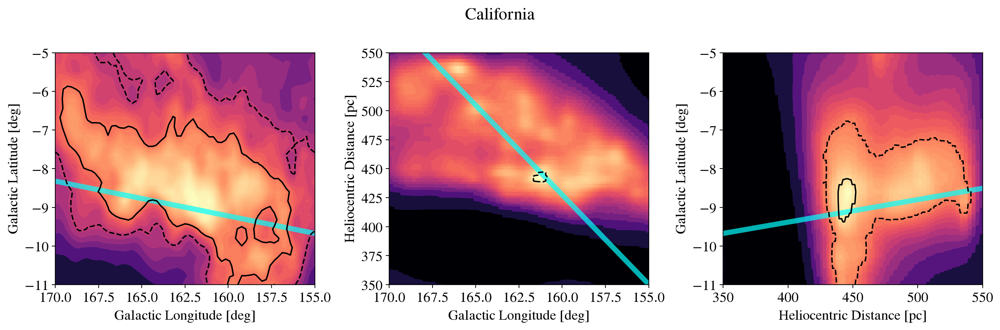

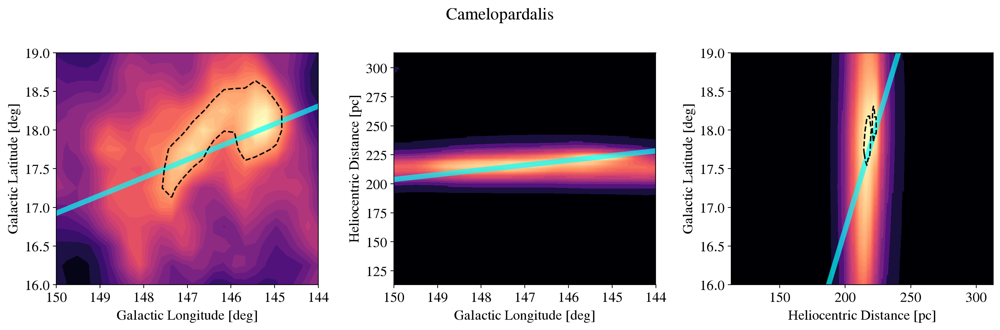

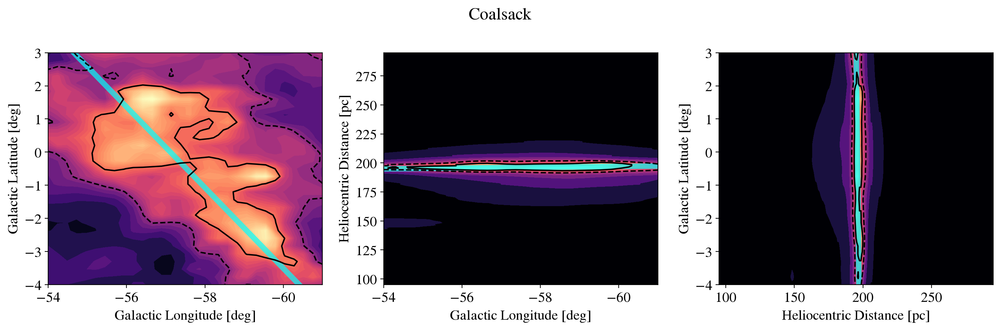

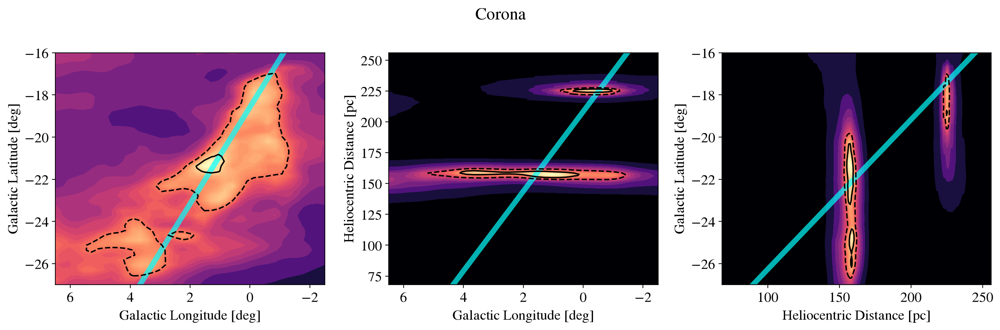

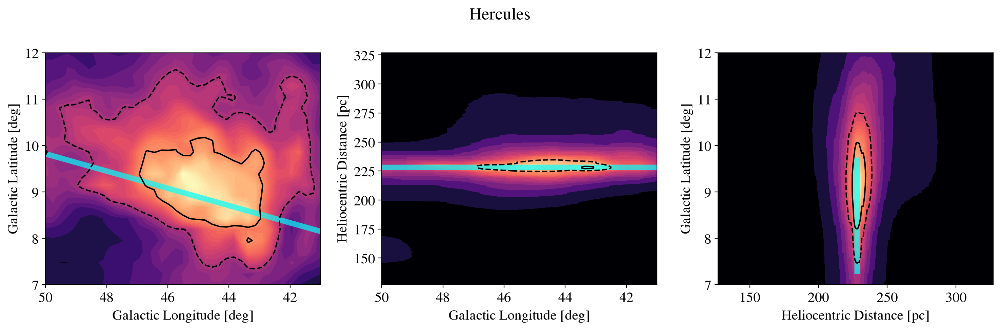

...

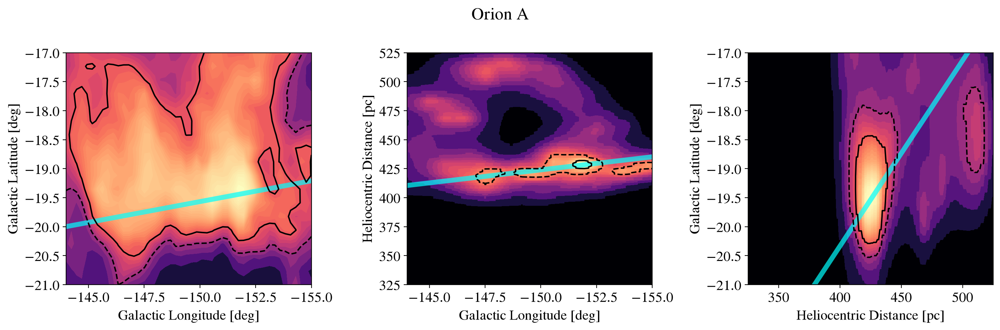

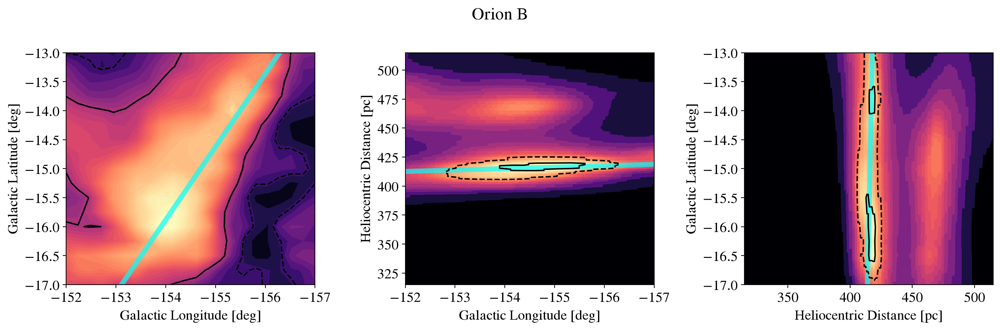

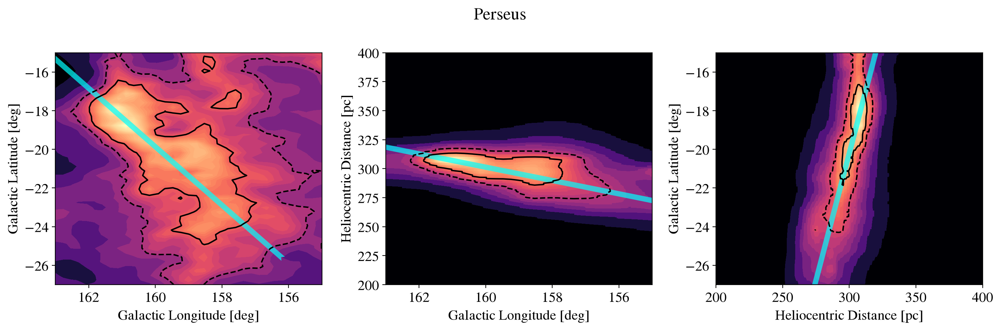

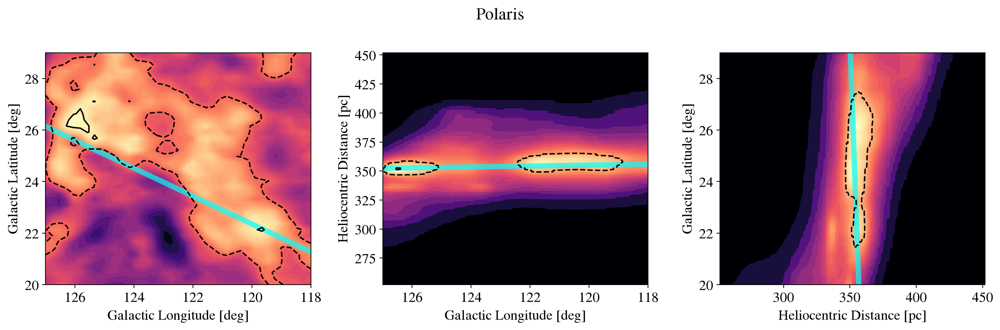

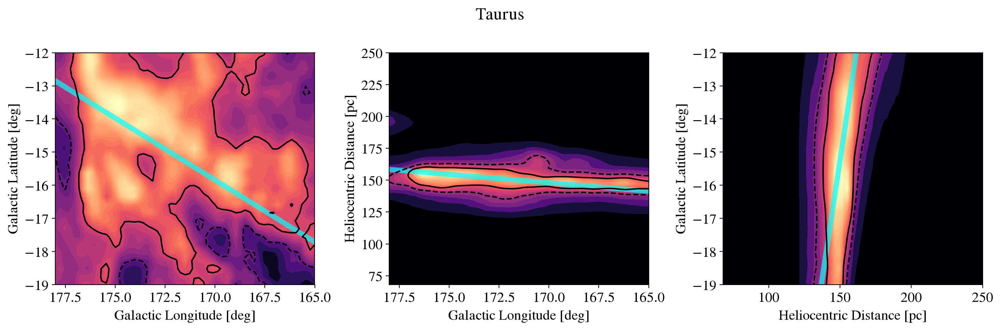

[((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>),
  None,
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>),
  None,
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', ylabel='Galactic Latitude [deg]'>),
  None,
  None),
 ((<Axes: xlabel='Galactic Longitude [deg]', ylabel='Galactic Latitude [deg]'>,
   <Axes: xlabel='Galactic Longitude [deg]', ylabel='Heliocentric Distance [pc]'>,
   <Axes: xlabel='Heliocentric Distance [pc]', y

In [14]:
[(moment_maps,
  plot_spine(moment_maps,cloud_dict['spine']),

 plt.show())

for i in range(len(table1))#[7]
# for cube, coords in [get_cloud_info(i, ednhfr_cm3,table1,100)]
for cloud_dict in [ha(i, ednhfr_cm3,table1,100)]
for moment_maps in [plot_moment_maps(cloud_dict['dust_cube'],cloud_dict['coords'],table1['cloud'].iloc[i])]
]

# fig2

In [ ]:
mw_m0 = np.nansum(ednhfr_cm3,axis=0)

In [ ]:
np.arange(786)*0.229-90.6

array([-9.0600e+01, -9.0371e+01, -9.0142e+01, -8.9913e+01, -8.9684e+01,
       -8.9455e+01, -8.9226e+01, -8.8997e+01, -8.8768e+01, -8.8539e+01,
       -8.8310e+01, -8.8081e+01, -8.7852e+01, -8.7623e+01, -8.7394e+01,
       -8.7165e+01, -8.6936e+01, -8.6707e+01, -8.6478e+01, -8.6249e+01,
       -8.6020e+01, -8.5791e+01, -8.5562e+01, -8.5333e+01, -8.5104e+01,
       -8.4875e+01, -8.4646e+01, -8.4417e+01, -8.4188e+01, -8.3959e+01,
       -8.3730e+01, -8.3501e+01, -8.3272e+01, -8.3043e+01, -8.2814e+01,
       -8.2585e+01, -8.2356e+01, -8.2127e+01, -8.1898e+01, -8.1669e+01,
       -8.1440e+01, -8.1211e+01, -8.0982e+01, -8.0753e+01, -8.0524e+01,
       -8.0295e+01, -8.0066e+01, -7.9837e+01, -7.9608e+01, -7.9379e+01,
       -7.9150e+01, -7.8921e+01, -7.8692e+01, -7.8463e+01, -7.8234e+01,
       -7.8005e+01, -7.7776e+01, -7.7547e+01, -7.7318e+01, -7.7089e+01,
       -7.6860e+01, -7.6631e+01, -7.6402e+01, -7.6173e+01, -7.5944e+01,
       -7.5715e+01, -7.5486e+01, -7.5257e+01, -7.5028e+01, -7.47

In [ ]:
# [(moment_maps,
#   # print(cloud_dict['spine']),
#  plot_spine(moment_maps,cloud_dict['spine']),
#  plt.show())

# for i in range(12)#ange(62)
# # for cube, coords in [get_cloud_info(i, ednhfr_cm3,table1,100)]
# for cloud_dict in [ha(i, ednhfr_cm3,table1,100)]
# for moment_maps in plot_moment_maps(cloud_dict['dust_cube'],cloud_dict['coords'],table1['cloud'].iloc[i])
# ]

In [ ]:
[(plot_moment_maps(cube,coords,table1['cloud'].iloc[i]),
 plt.show())

for i in range(62)
for cube, coords in [get_cloud_info(i, ednhfr_cm3,table1,200)]
]

Unexpected exception formatting exception. Falling back to standard exception


[autoreload of dust_3d_functions failed: Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 261, in check
    superreload(m, reload, self.old_objects)
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 459, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/importlib/__init__.py", line 169, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 621, in _exec
  File "<frozen importlib._bootstrap_external>", line 940, in exec_module
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_removed
  File "/Users/thummimm/Documents/research/local/dust_3d/dust_3d_clouds/code_and_data/dust_3d_functions.py", line 169, in <module>
    drs = np.nanmax((np.nanstd(table1

In [ ]:
[plot_moment_maps(cube,coords,name_,_)]

In [ ]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),
    
[
plot_spine(axs,dict_['spine'],scolor=clr) 
    for d,clr in zip([3*r,2*r,r],['red','orange','green',])
    for dict_ in [ha(i,ednhfr_cm3,d)]
],
     
plt.show())
    
for i,r in zip(range(12) ,table1['d_std(pc)'])
for dict_ in [ha(i,ednhfr_cm3,75)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             names[i]+', r = '+str(np.around(r,2))+' pc',
                             _,_)]
                            #   b_perp=dict_['b_perp'] ,b_parl=dict_['b_parl'])]

]

/Users/thummimm/Library/Python/3.11/lib/python/site-packages/numpy/lib/nanfunctions.py:1562: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


UndefinedVariableError: name 'nan' is not defined

# fig 2: moment map of clouds with co and traditional extinction boundaries overlaid

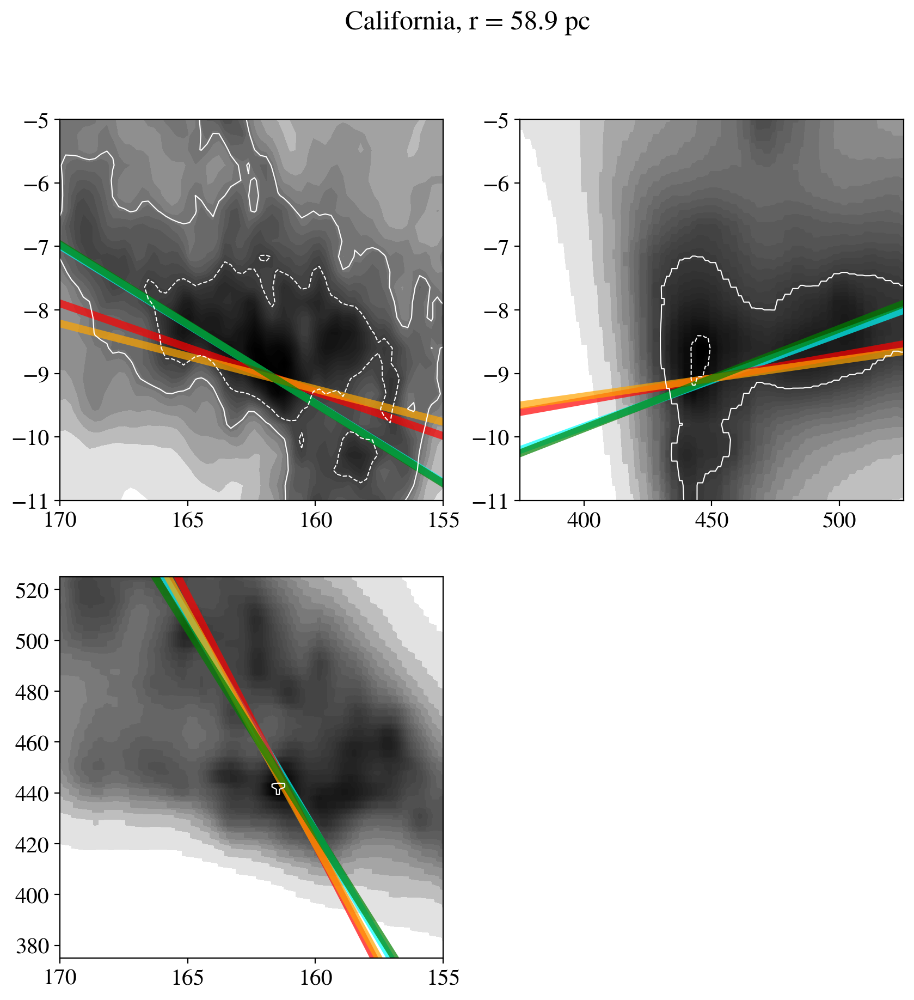

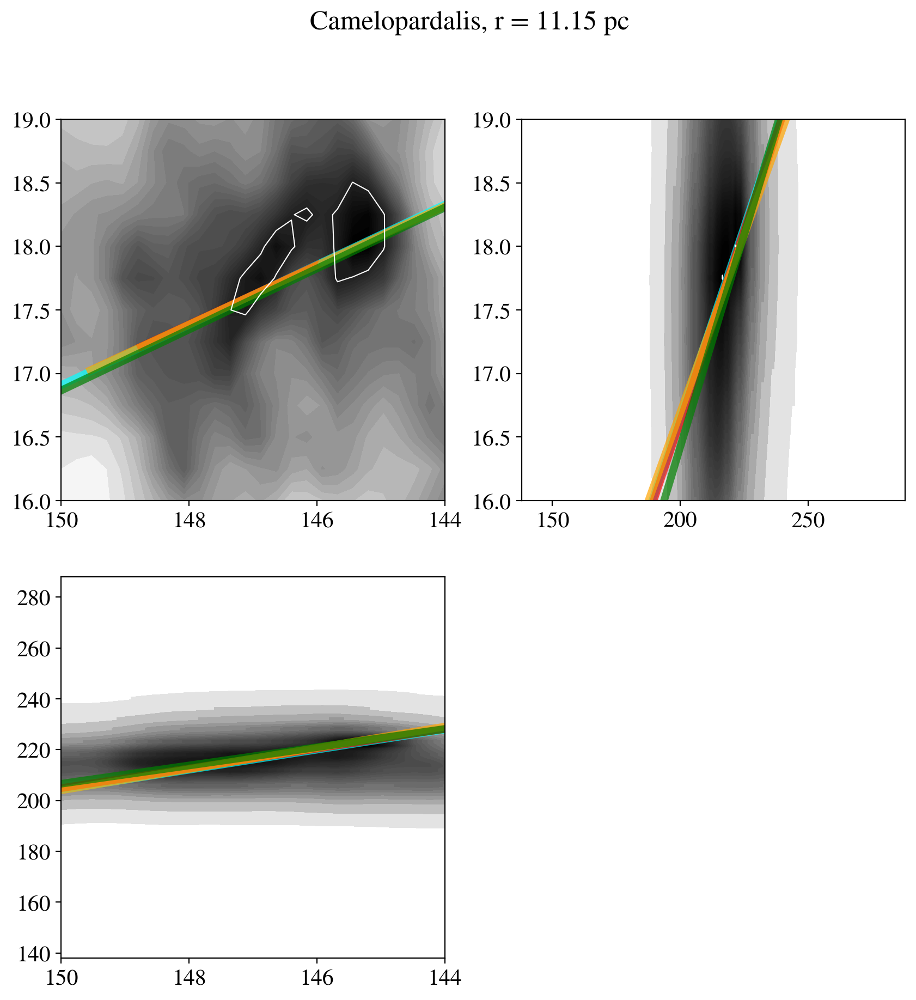

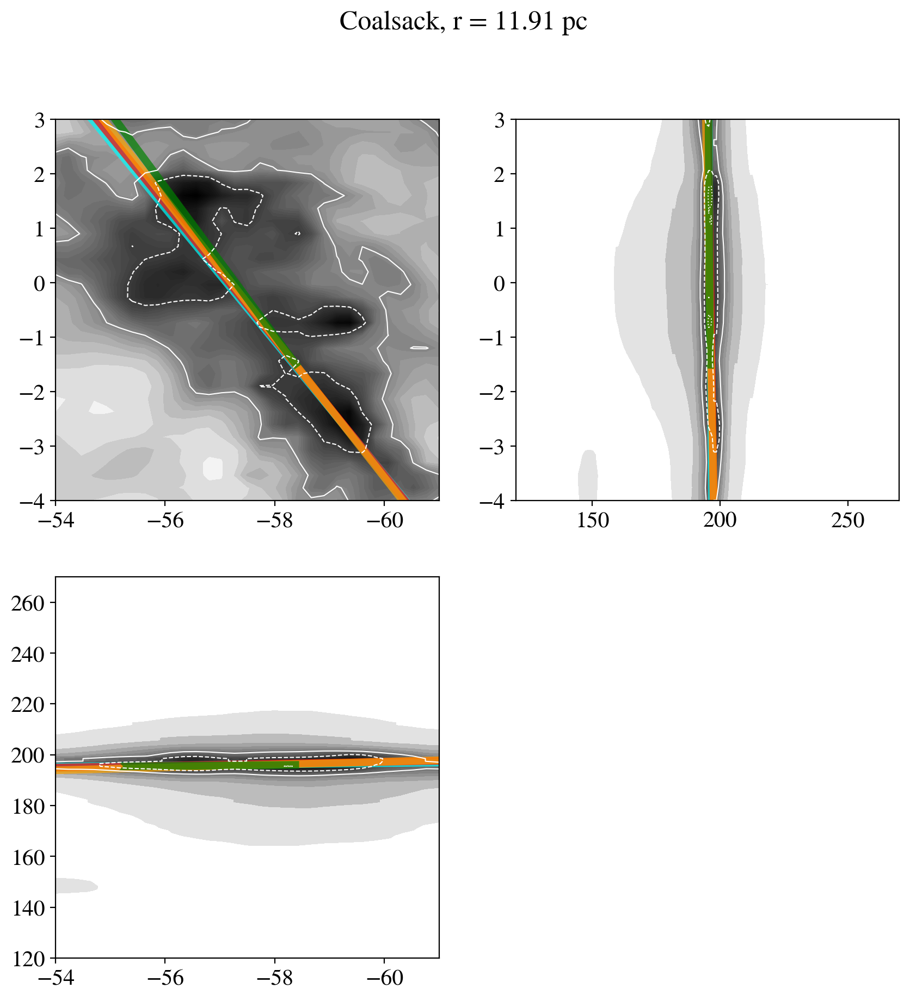

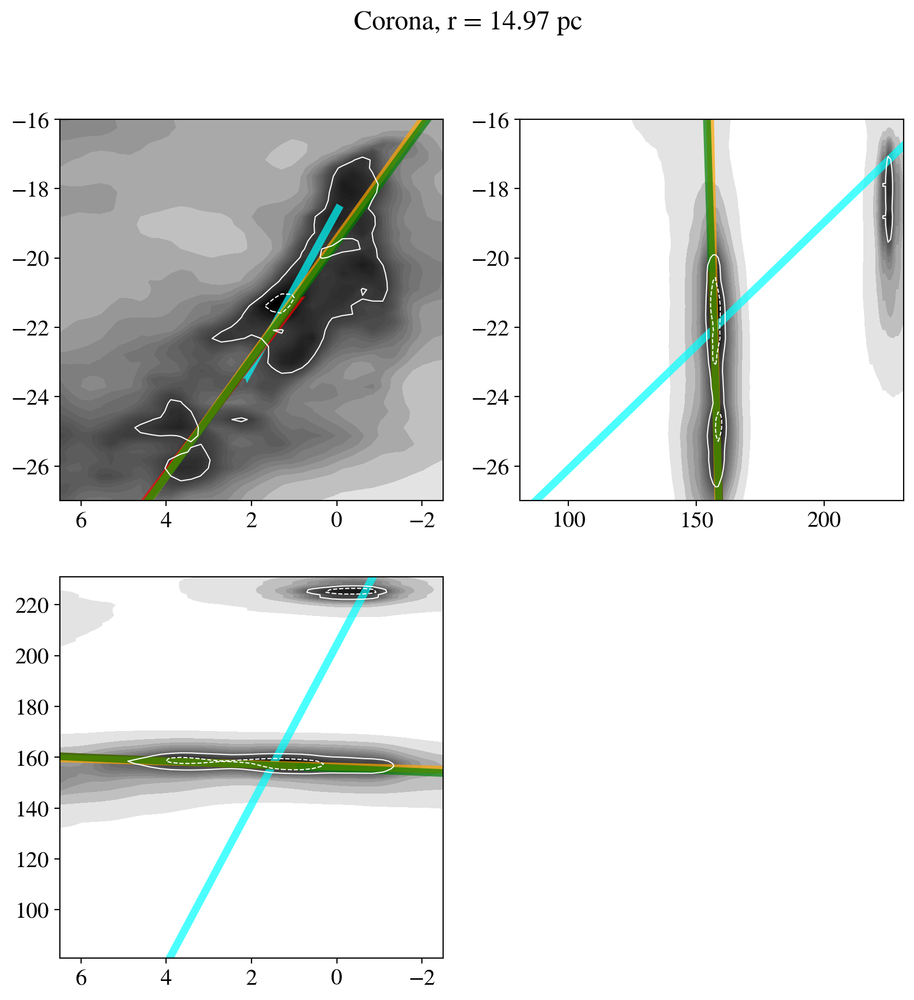

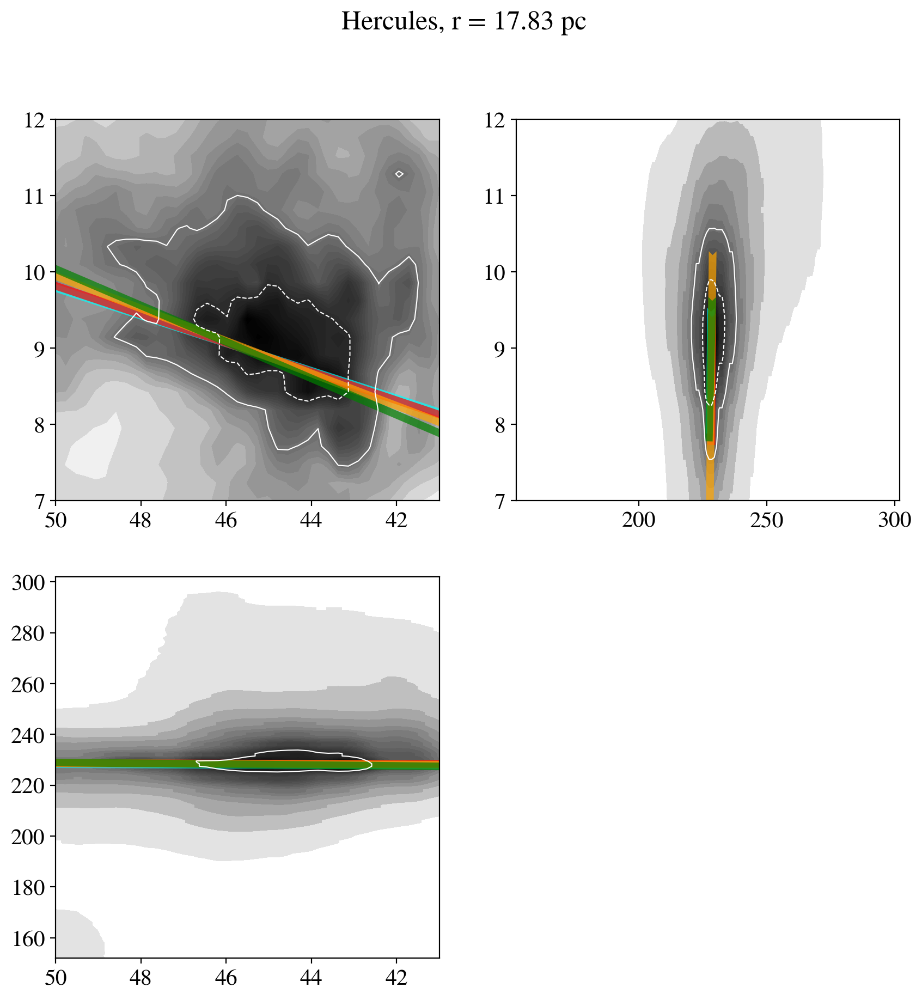

...

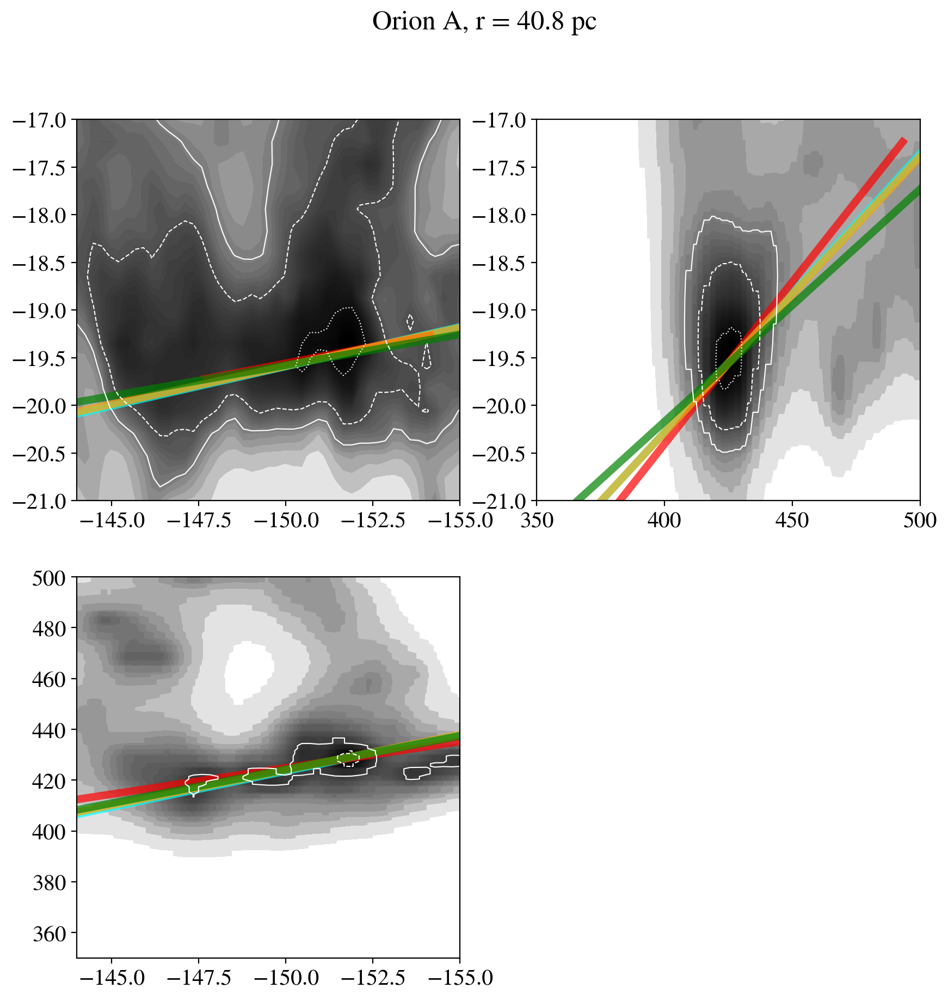

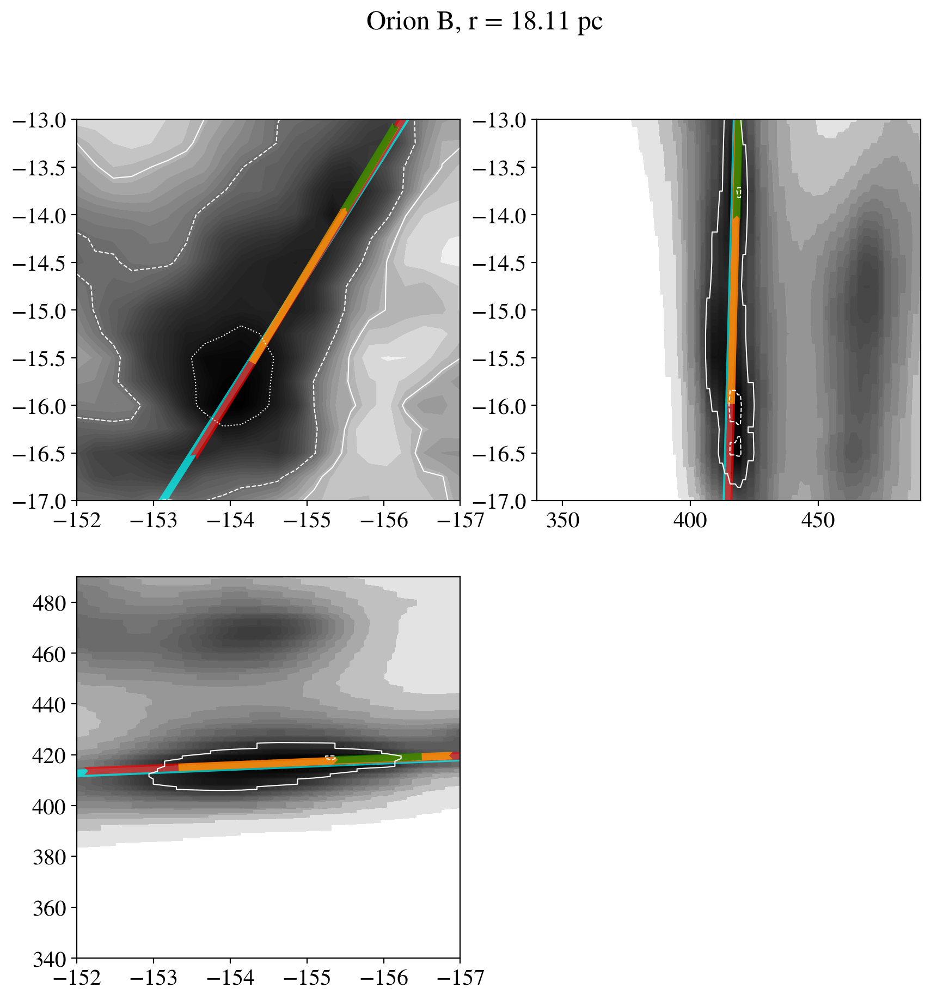

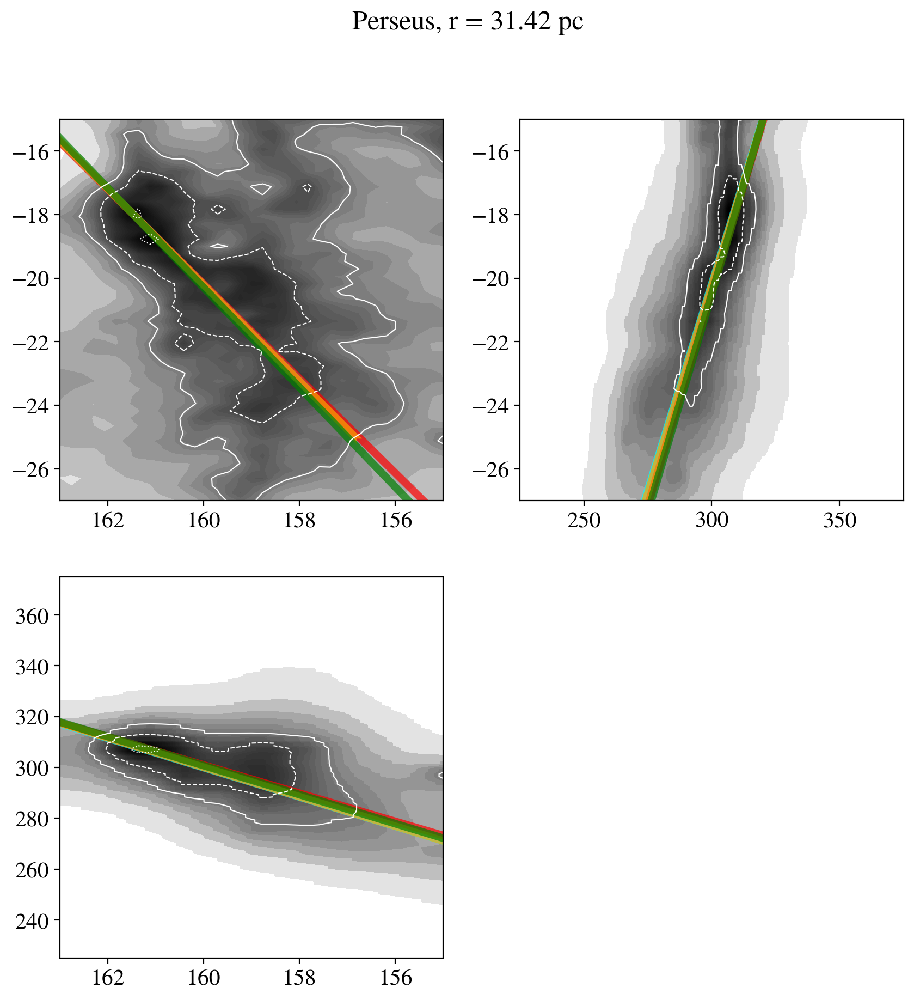

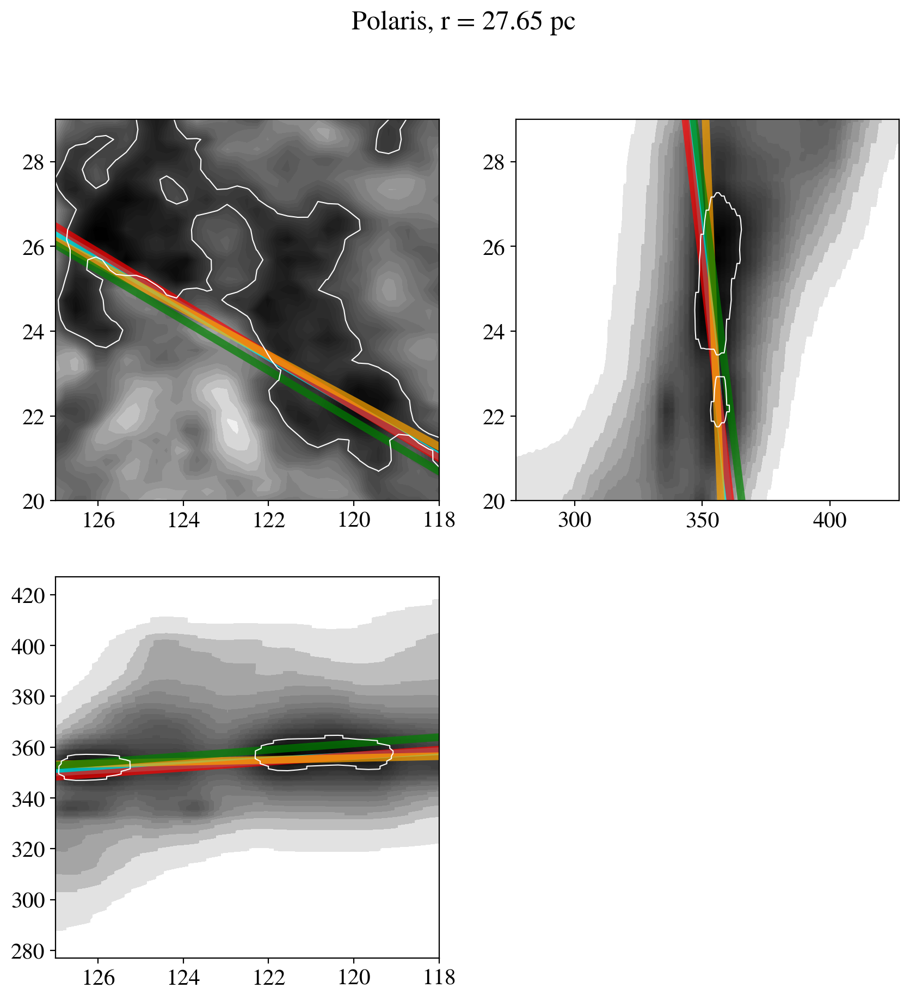

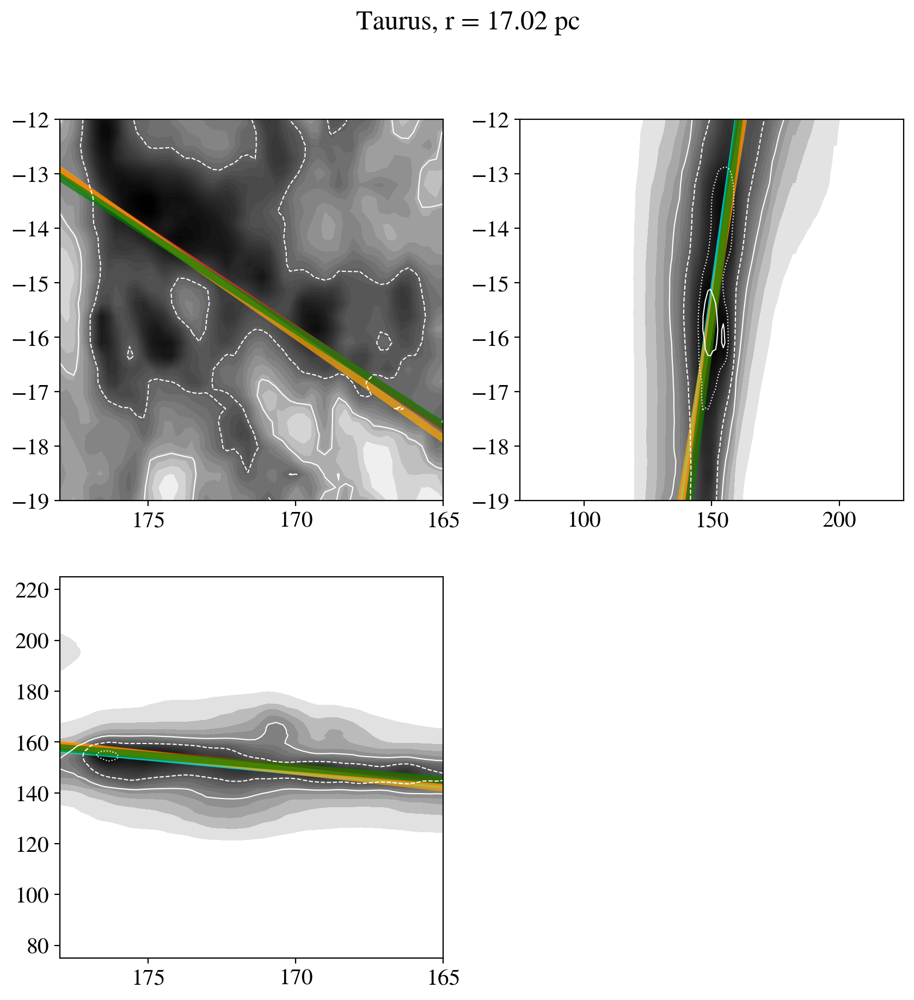

[(array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], d

In [ ]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),
    
[
plot_spine(axs,dict_['spine'],scolor=clr) 
    for d,clr in zip([3*r,2*r,r],['red','orange','green',])
    for dict_ in [ha(i,ednhfr_cm3,d)]
],
     
plt.show())
    
for i,r in zip(range(12) ,drs)
for dict_ in [ha(i,ednhfr_cm3,75)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             names[i]+', r = '+str(np.around(r,2))+' pc',
                             _,_)]
                            #   b_perp=dict_['b_perp'] ,b_parl=dict_['b_parl'])]

]

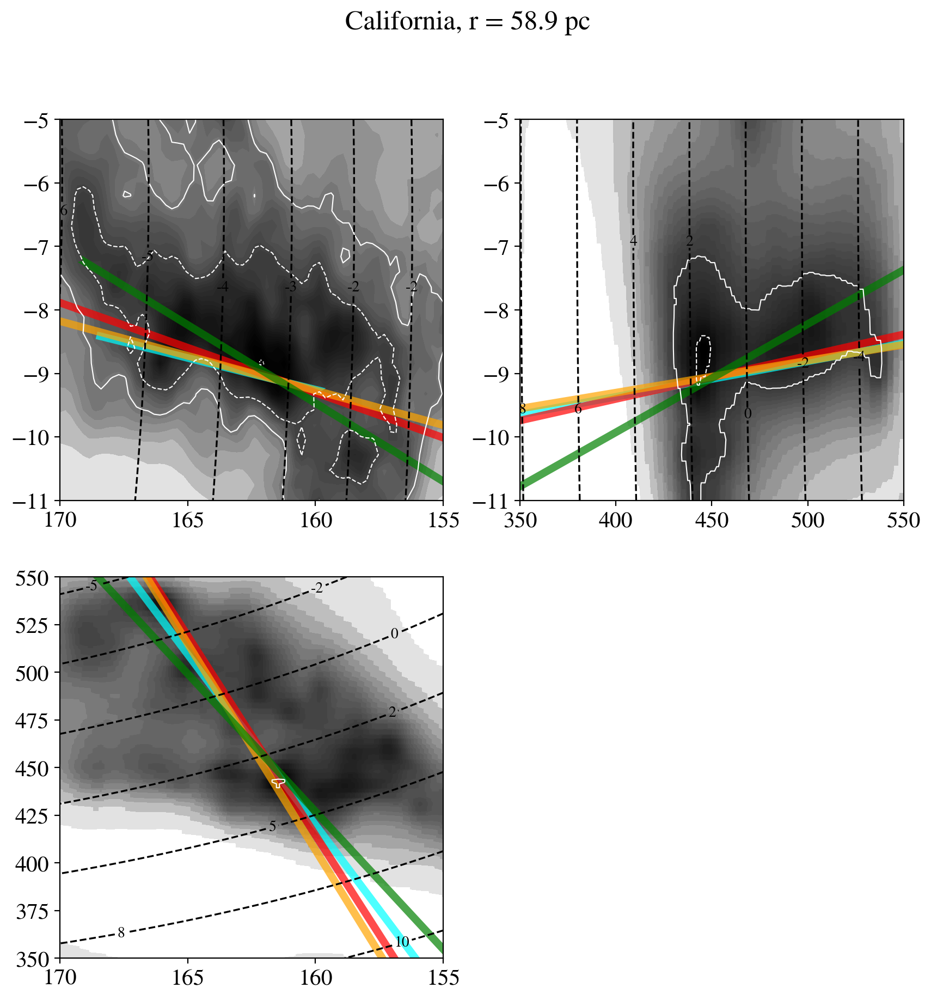

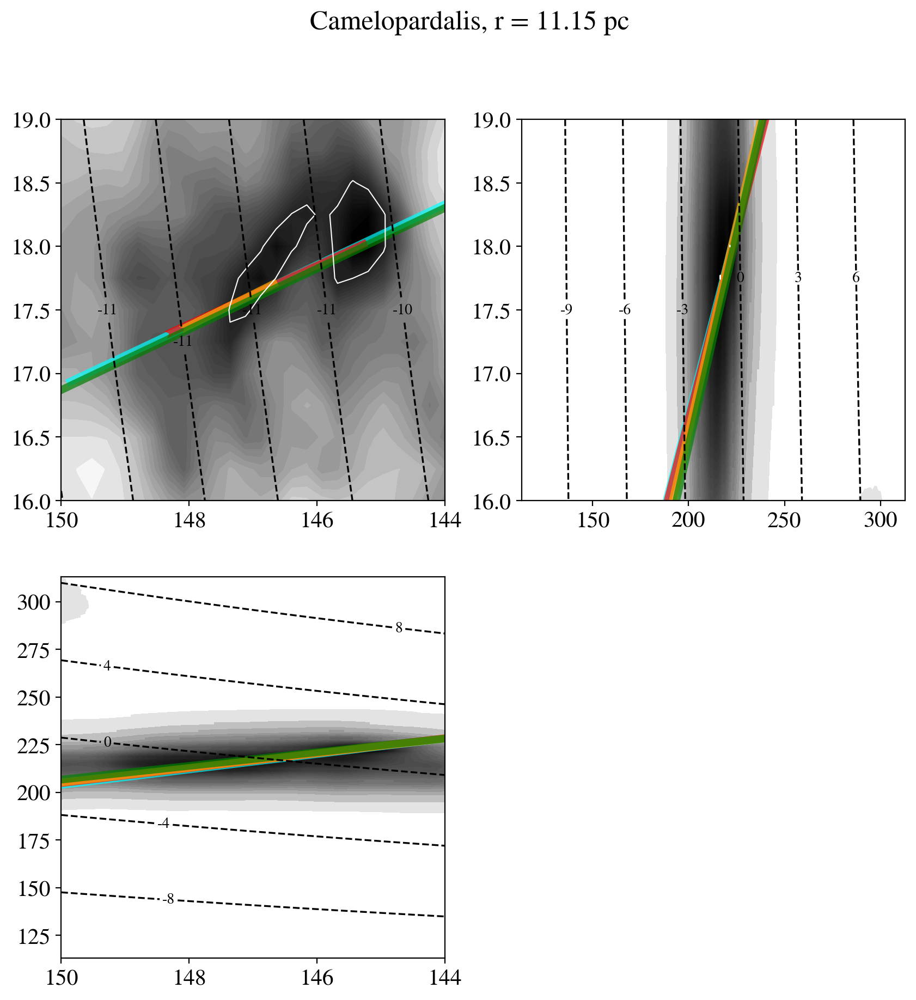

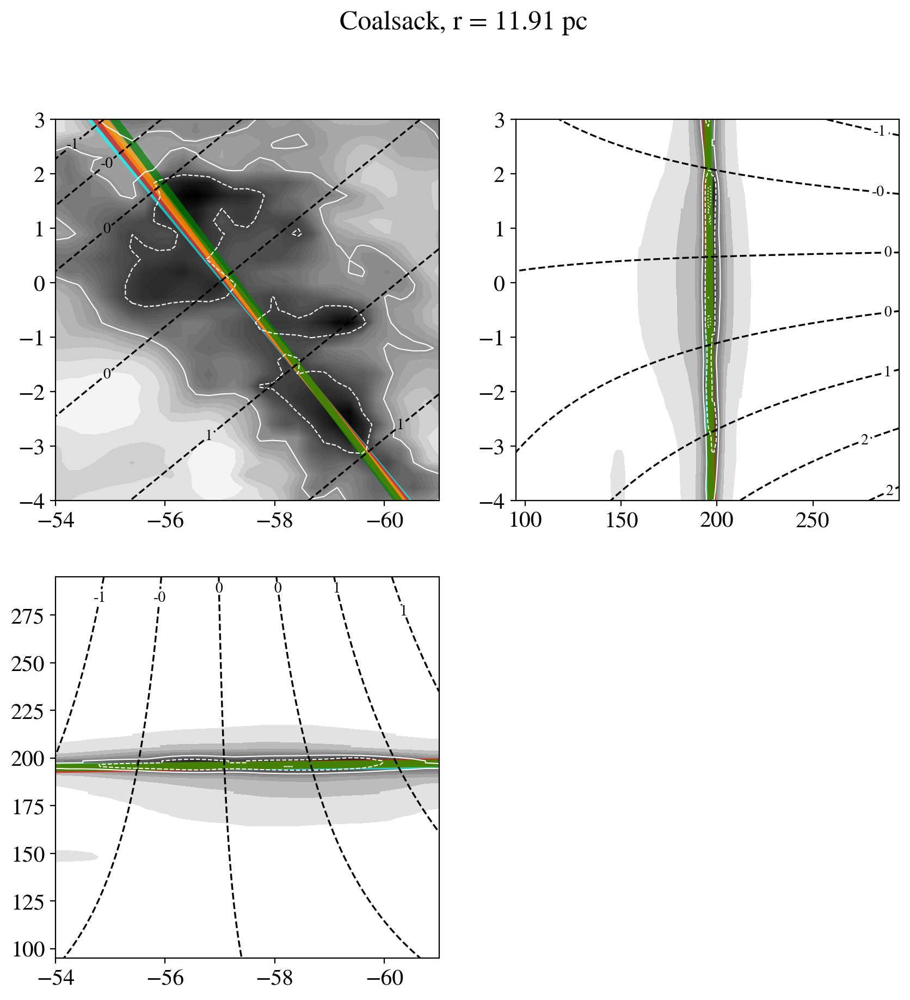

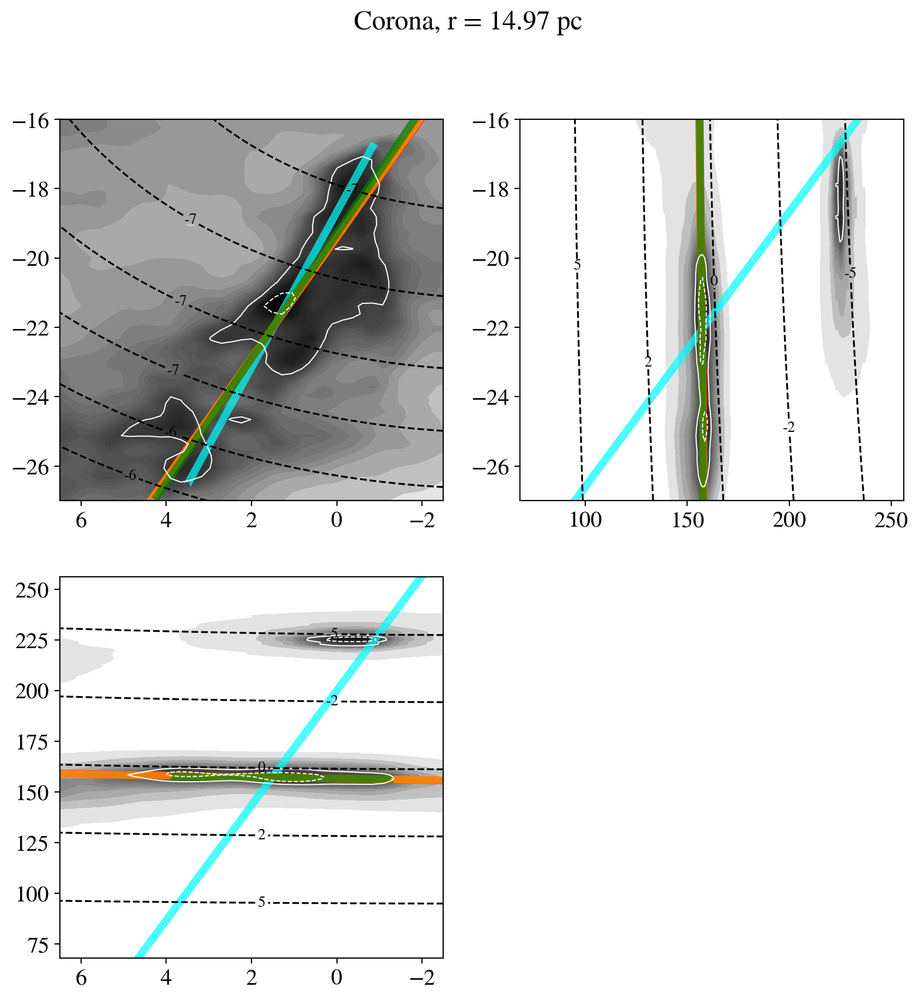

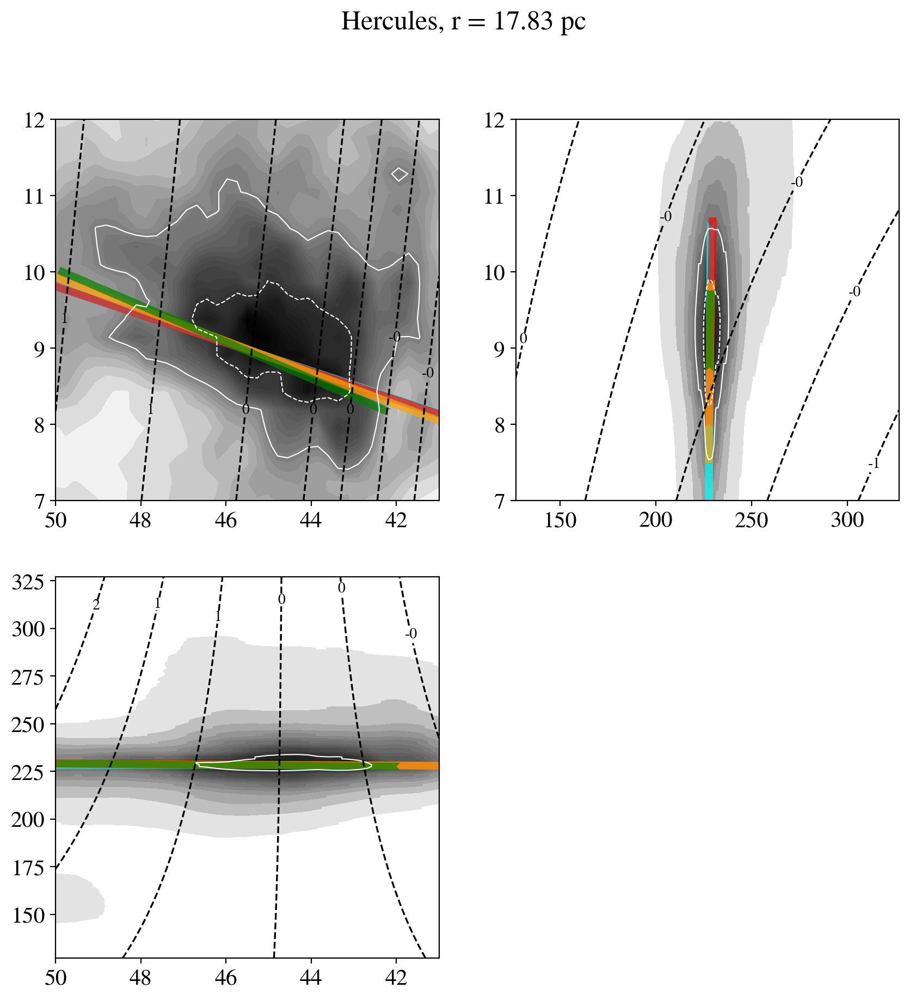

...

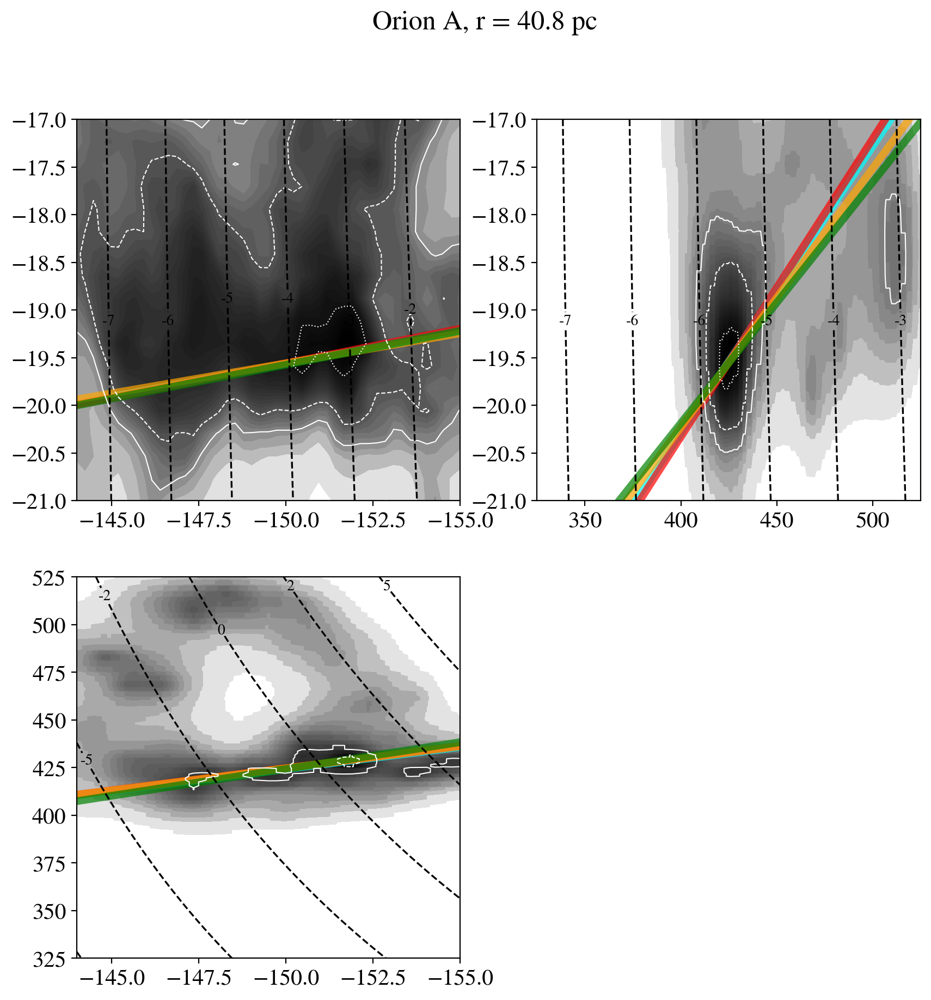

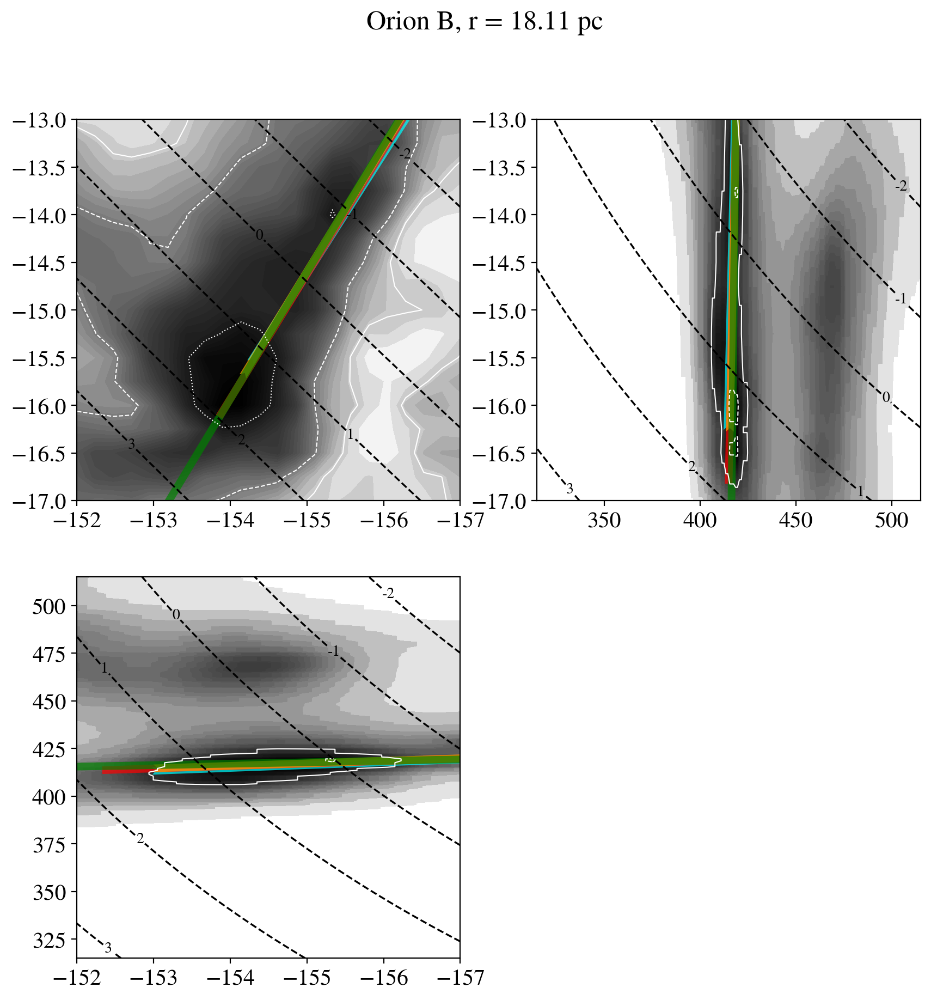

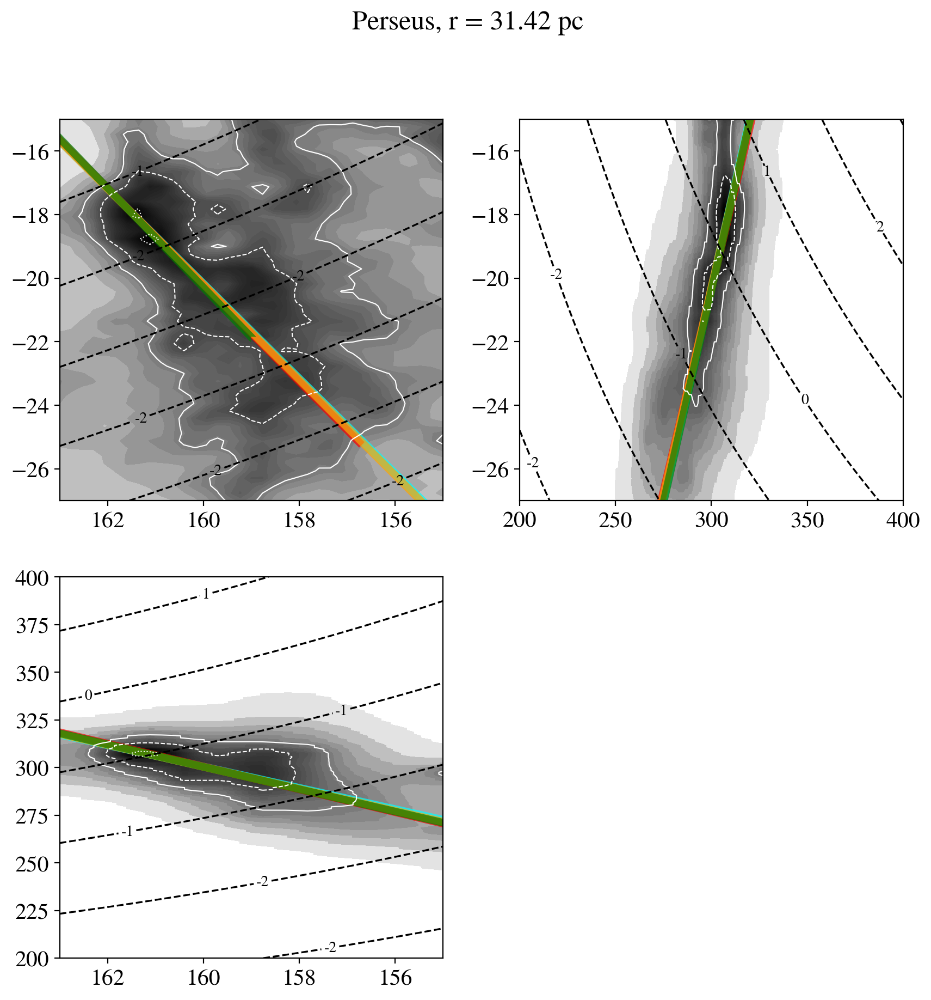

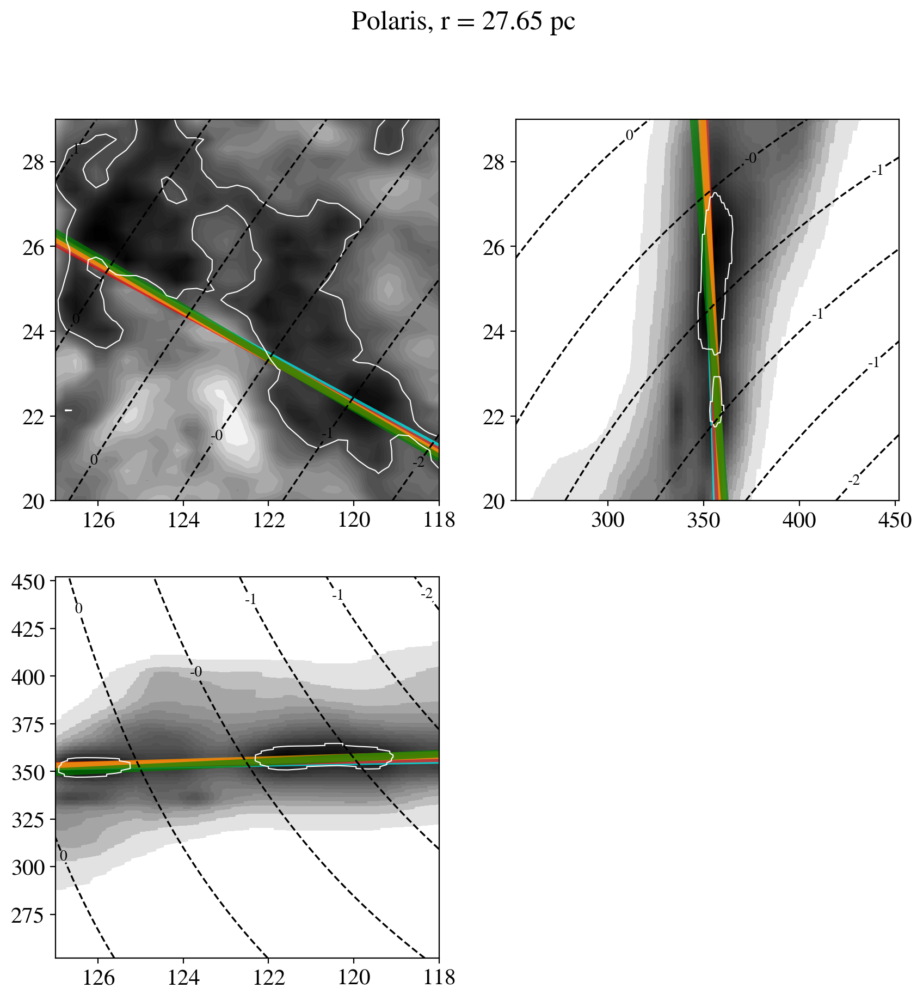

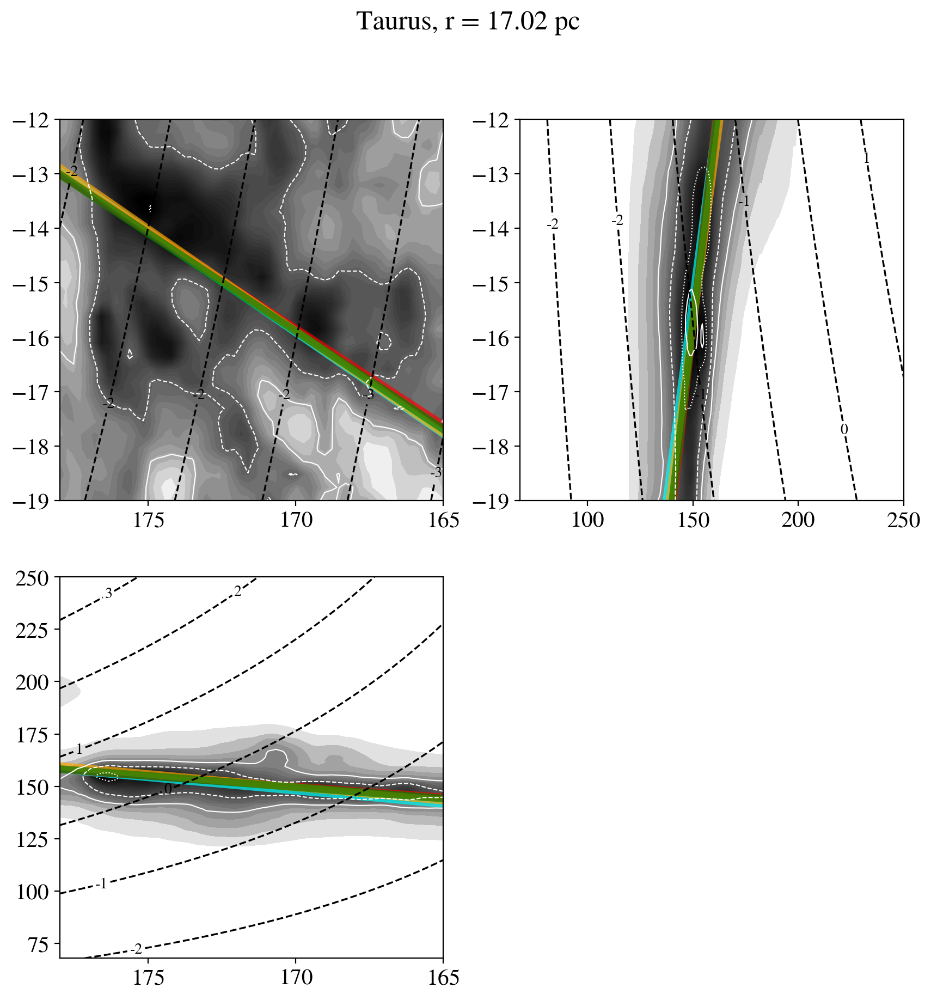

[(array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], dtype=object),
  None,
  [None, None, None],
  None),
 (array([[<Axes: >, <Axes: >],
         [<Axes: >, <Axes: >]], d

In [ ]:
[(
    
axs,
plot_spine(axs,dict_['spine'],scolor='cyan'),
    
[
plot_spine(axs,dict_['spine'],scolor=clr) 
    for d,clr in zip([3*r,2*r,r],['red','orange','green',])
    for dict_ in [ha(i,ednhfr_cm3,d)]
],
     
plt.show())
    
for i,r in zip(range(12) ,drs)
for dict_ in [ha(i,ednhfr_cm3,100)] 
    
for axs in [plot_moment_maps(dict_['dust_cube'],dict_['coords'],
                             names[i]+', r = '+str(np.around(r,2))+' pc',
                              _ ,b_parl=dict_['b_parl'])]

]

# fig 2: "spectrum" or other way of showing the distance ranges endet endemimereTu

# fig 3: moment maps with the fit yetederegut spines, for diff distance ranges yalutn overplot

# fig 4: density profile along $b_\perp$ and $b_\parallel$

In [ ]:
dds = #come down on a definition

In [ ]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
rho_radial_profiles(i,ednhfr_cm3, dds[i],color='black',lbl=f'{round(dds[i],2)} pc'),
# plt.save_fig('../figures/b_perp_parl'),
# ax[0].legend(),
plt.show()
) for i,r in zip([0],drs[:1])
]

NameError: name 'dds' is not defined

In [ ]:
def record_spine_props(i,source_array,drange,n_jobs=-1):
    cloud_dict = ha(i, source_array, drange, n_jobs=n_jobs)
    save_out = #what is the 

In [ ]:
record_spine_props(0,ednhfr_cm3,100)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,1)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,2)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,3)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,4)

In [ ]:
record_spine_props(0,ednhfr_cm3,100,8)

In [ ]:
pta, veca, dperp, dparl, L1da = get_spine(i, source_array, drange, n_jobs=n_jobs)

In [ ]:
cmap_ = plt.cm.plasma.resampled(5)

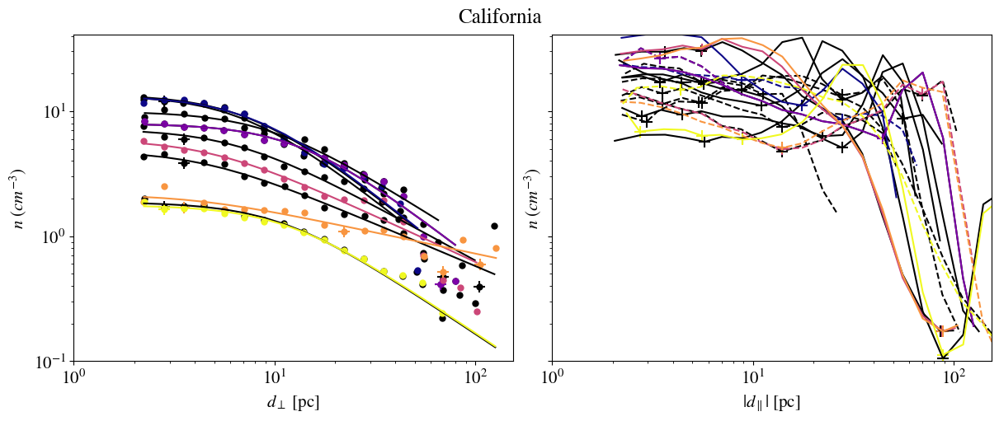

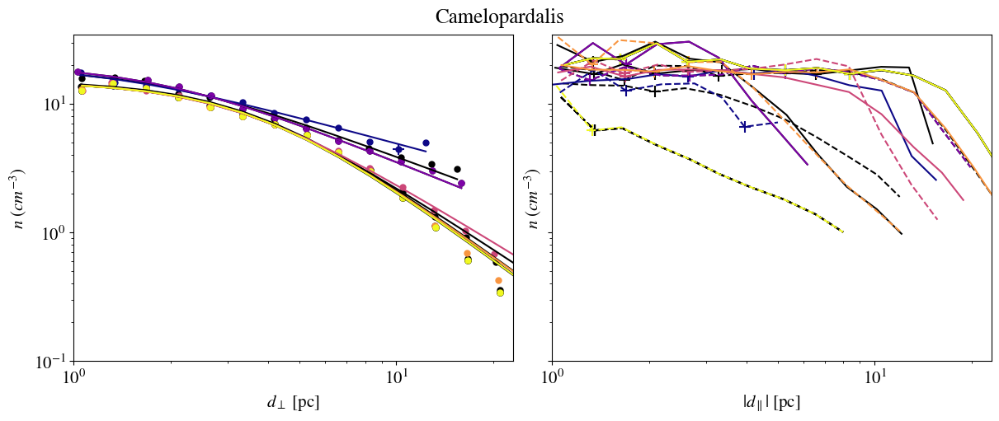

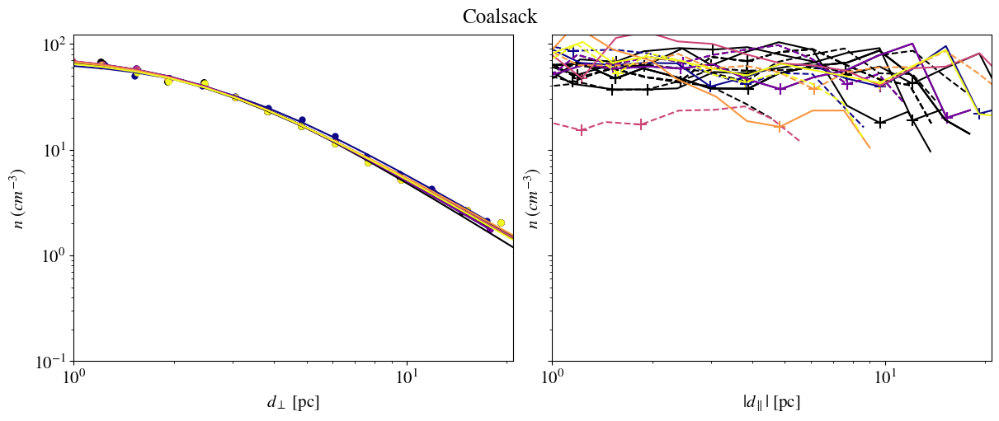

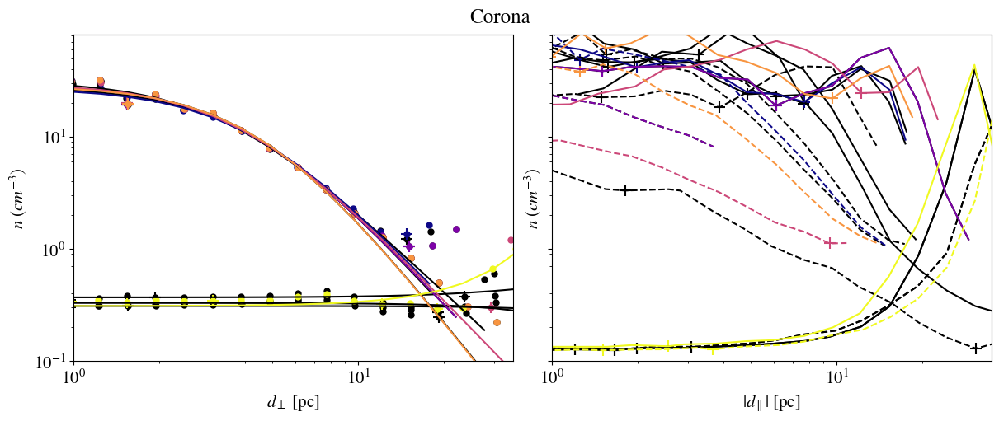

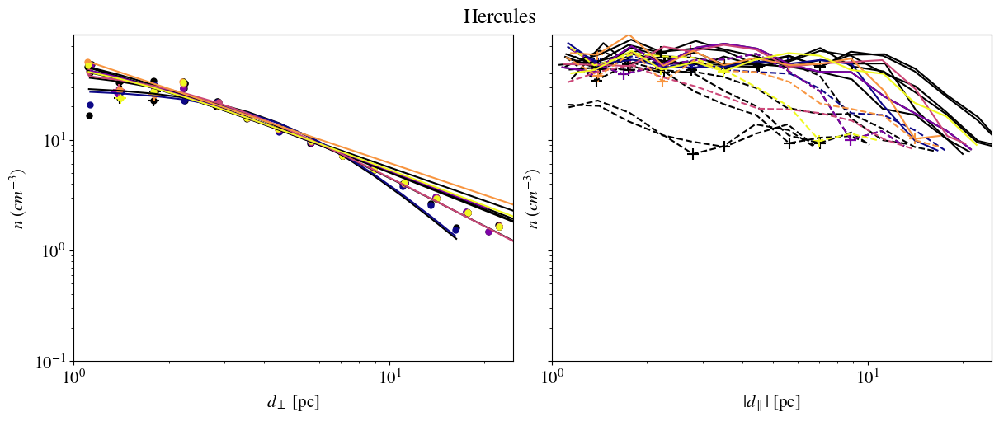

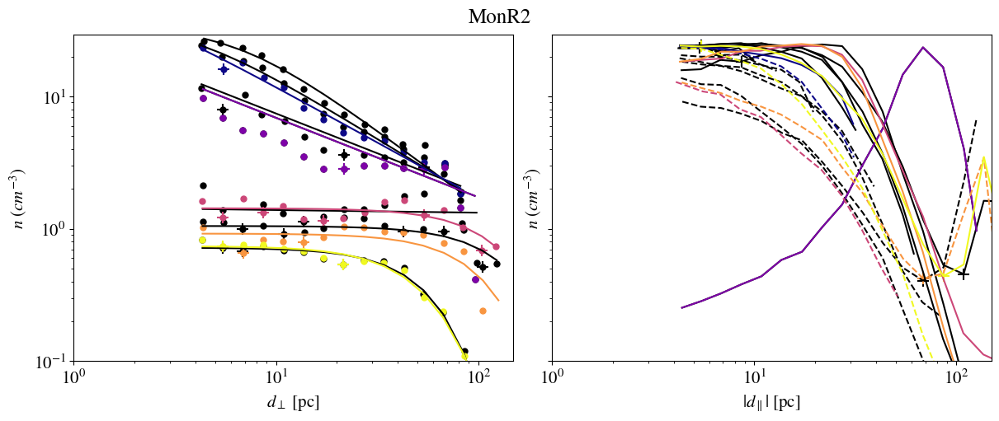

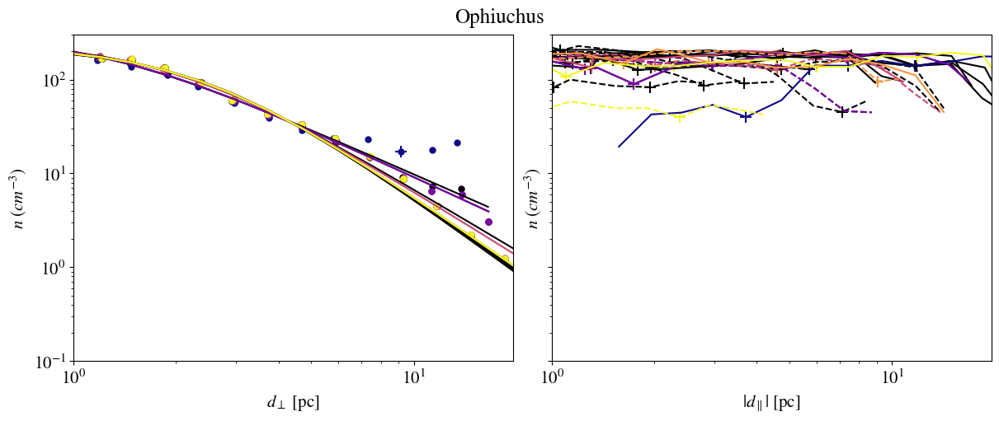

KeyboardInterrupt: 

In [ ]:
[(
# print('rho0:',fitpars[0],'r0:',fitpars[0],'alpha:',fitpars[0]),
ax,

[rho_radial_profiles(i,ednhfr_cm3, d,plt_=ax,color='black',lbl=f'{round(d,2)} pc') 
for d in [10,25,50,100,150,300]],

[rho_radial_profiles(i,ednhfr_cm3, d,plt_=ax,color=cmap_(j),lbl=f'{round(d,2)} pc') 
for j,d in enumerate(drs[i]*np.array([0.5,1,2,3,5]))],
    
# ax[0].legend(),
plt.show()
) for i,r in zip(range(12) ,drs)
  for ax,fitpars in [rho_radial_profiles(i,ednhfr_cm3,'by r',color='black',lbl='r')]
]

# fig 3: distance spectra of the clouds

[[<matplotlib.lines.Line2D at 0x4b125f6d0>]]

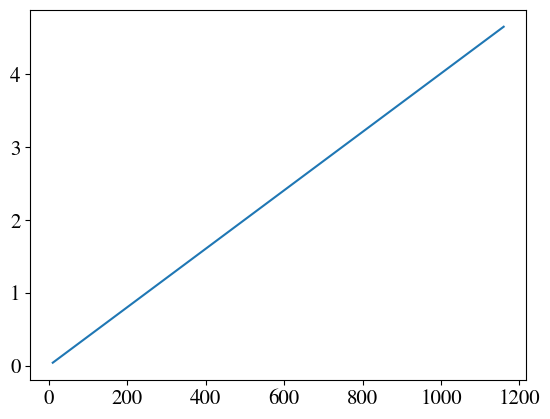

In [ ]:
[plt.plot(ds,0.23*u.deg.to(u.rad)*ds) for ds in [np.arange(10,1200,50)]]

In [ ]:
table2 = pd.read_csv('../figures/distance_peaks_by_claude.csv')

In [ ]:
table2

,cloud,b1_pc,b2_pc,b3_pc,b4_pc,b5_pc,b6_pc,b7_pc,b8_pc,b9_pc,b10_pc
0,Aquila_South,183.8,300,,,,,,,,
1,Ophiuchus,129.9,175.4,400,,,,,,,
2,Taurus,176.8,220,346.6,,,,,,,
3,Corona_Australis,74.3,183.8,354.4,,,,,,,
4,Lupus,122.1,160,220,,,,,,,
5,Pipe,176.8,,,,,,,,,
6,Chamaeleon,202.0,,,,,,,,,
7,Coalsack,421.7,,,,,,,,,
8,Hercules,121.2,342.7,523.4,790.7,,,,,,
9,LBN917,84.8,220.2,319.2,,,,,,,


[ 49.3  26.8 -29.1  -5.1  68.  207.2] (139, 104, 97)
[  49.3   26.8  -29.1   -5.1   68.  1250. ] (1182, 104, 97)
1.4687517


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


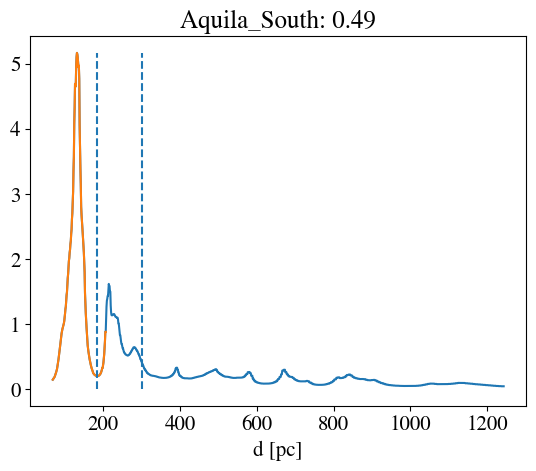

[ 18.4 -20.7   2.   32.   68.  214.4] (146, 131, 170)
[  18.4  -20.7    2.    32.    68.  1250. ] (1182, 131, 170)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


3.0427504


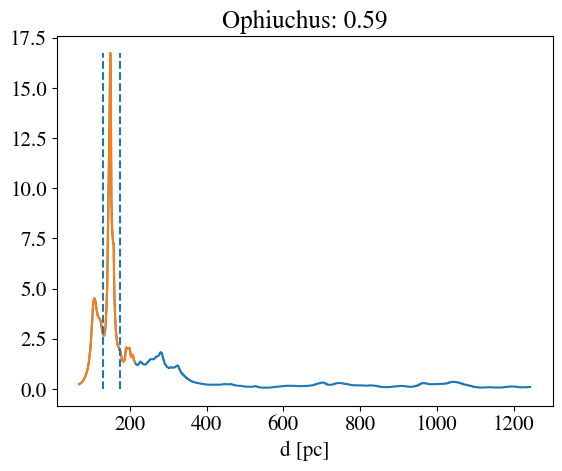

[185.8 156.2 -29.2  -2.3  71.9 221.9] (150, 117, 129)
[ 185.8  156.2  -29.2   -2.3   68.  1250. ] (1182, 117, 129)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


2.7221355


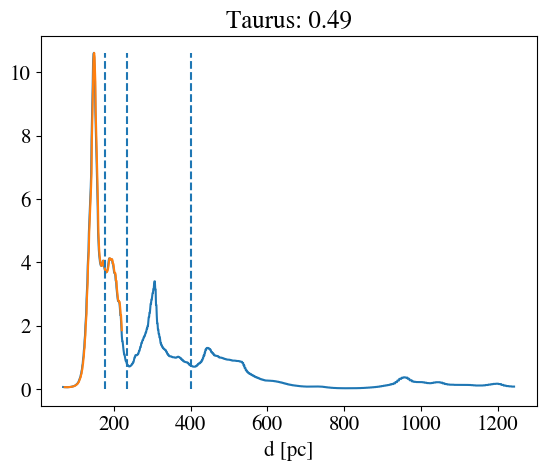

[ 10.8 -10.5 -31.   -7.8  80.7 230.7] (150, 101, 93)
[  10.8  -10.5  -31.    -7.8   68.  1250. ] (1182, 101, 93)
0.7921431


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


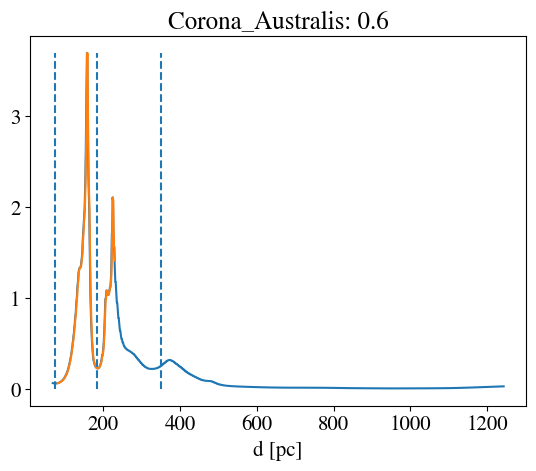

[ -2.7 -31.3  -3.6  27.4  93.5 243.5] (150, 135, 124)
[  -2.7  -31.3   -3.6   27.4   68.  1250. ] (1182, 135, 124)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


2.255836


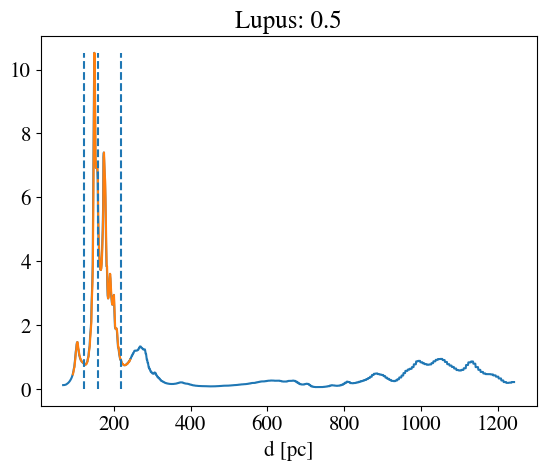

[  6.9 -13.1  -2.7  17.3 105.  255. ] (150, 87, 87)
[   6.9  -13.1   -2.7   17.3   68.  1250. ] (1182, 87, 87)
4.0010366


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


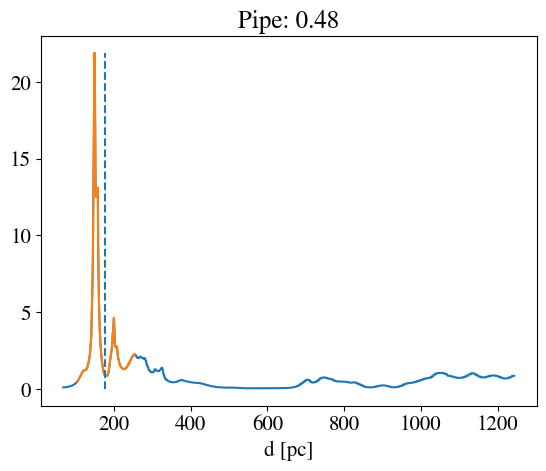

[-46.7 -72.5 -26.7  -4.2 112.  262. ] (150, 97, 112)
[ -46.7  -72.5  -26.7   -4.2   68.  1250. ] (1182, 97, 112)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


1.7371932


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


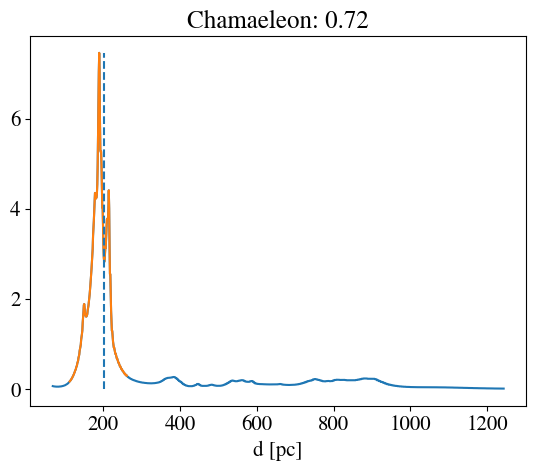

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[-47.1 -70.  -12.6  13.1 113.8 263.8] (150, 112, 99)
[ -47.1  -70.   -12.6   13.1   68.  1250. ] (1182, 112, 99)
1.8956246


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


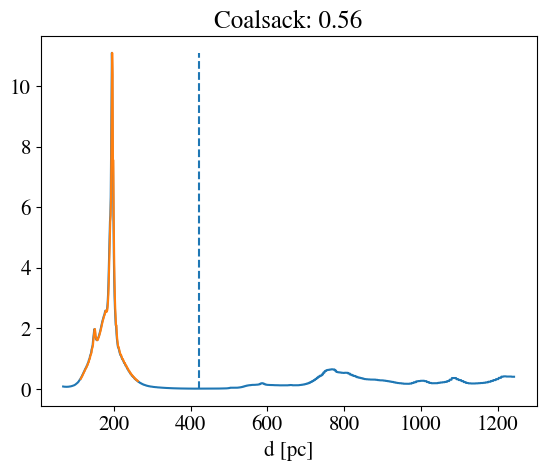

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[ 55.1  32.8  -2.1  18.9 150.3 300.3] (150, 92, 97)
[  55.1   32.8   -2.1   18.9   68.  1250. ] (1182, 92, 97)
0.6971981


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


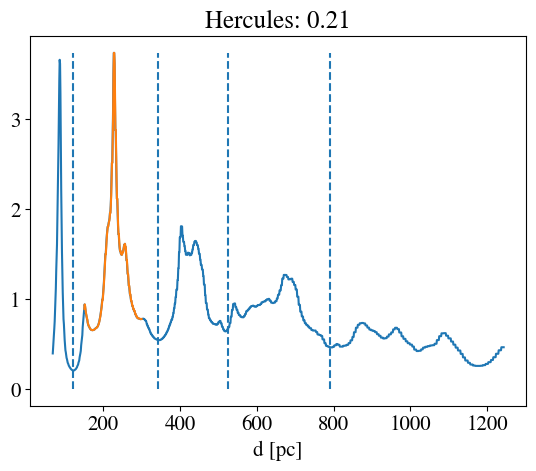

[-146.3 -166.3  -40.3  -20.3  157.   307. ] (150, 87, 87)
[-146.3 -166.3  -40.3  -20.3   68.  1250. ] (1182, 87, 87)
0.4604433


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


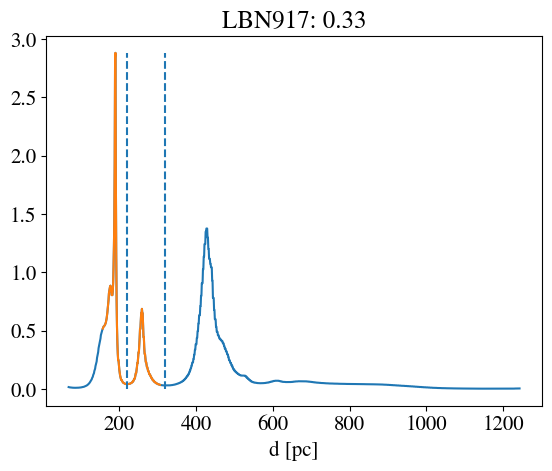

[ 31.8   6.   -0.8  26.6 161.6 311.6] (150, 119, 112)
[ 3.18e+01  6.00e+00 -8.00e-01  2.66e+01  6.80e+01  1.25e+03] (1182, 119, 112)
0.54041916


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


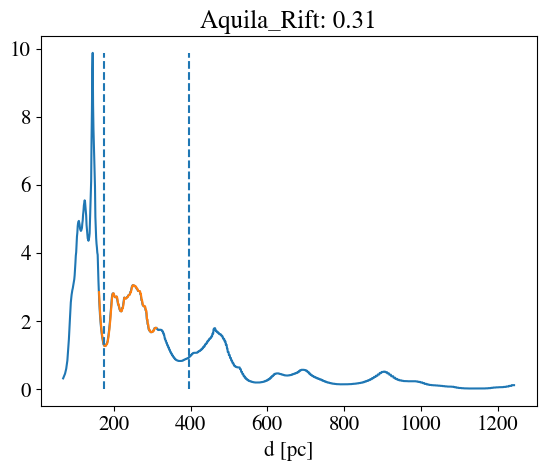

[-144.4 -164.4  -32.   -12.   182.   332. ] (150, 87, 87)
[-144.4 -164.4  -32.   -12.    68.  1250. ] (1182, 87, 87)
0.17374405


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


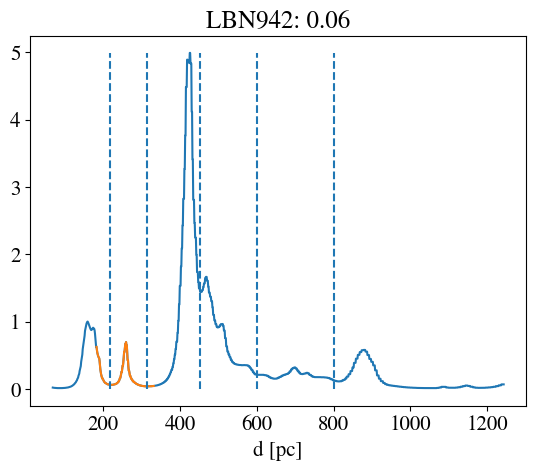

[115.6  78.8 -51.3 -20.6 185.2 335.2] (150, 133, 160)
[ 115.6   78.8  -51.3  -20.6   68.  1250. ] (1182, 133, 160)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.49440354


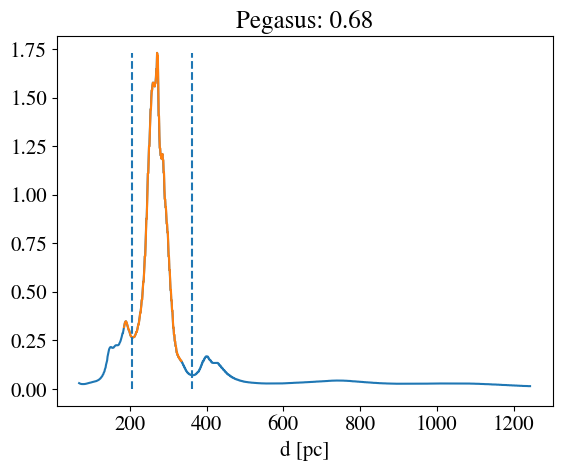

[-141.6 -161.6  -32.2  -12.2  199.   349. ] (150, 87, 87)
[-141.6 -161.6  -32.2  -12.2   68.  1250. ] (1182, 87, 87)
0.15037392


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


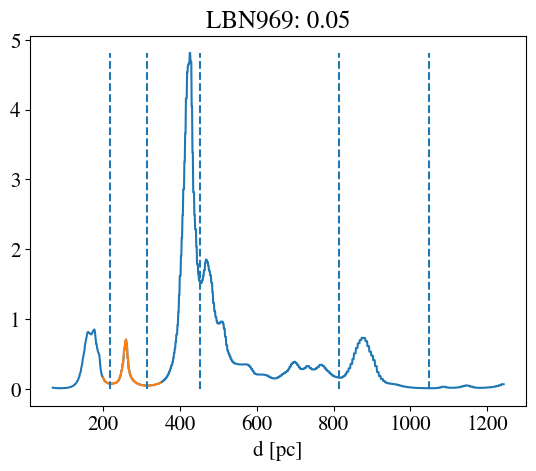

[158.8 134.8   7.2  27.8 205.6 355.6] (150, 89, 105)
[ 158.8  134.8    7.2   27.8   68.  1250. ] (1182, 89, 105)
0.7461379


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


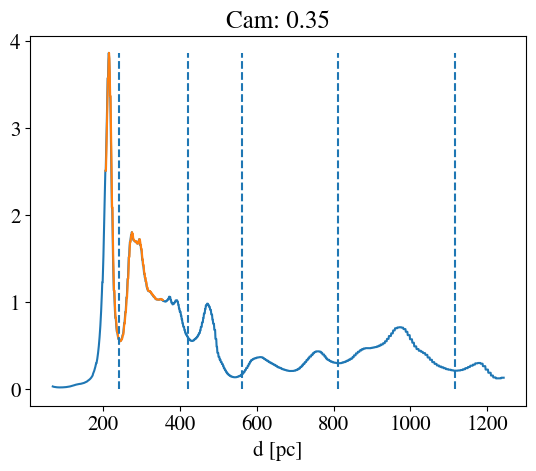

[170.8 147.5 -32.8  -6.3 206.8 356.8] (150, 115, 102)
[ 170.8  147.5  -32.8   -6.3   68.  1250. ] (1182, 115, 102)
1.2681462


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


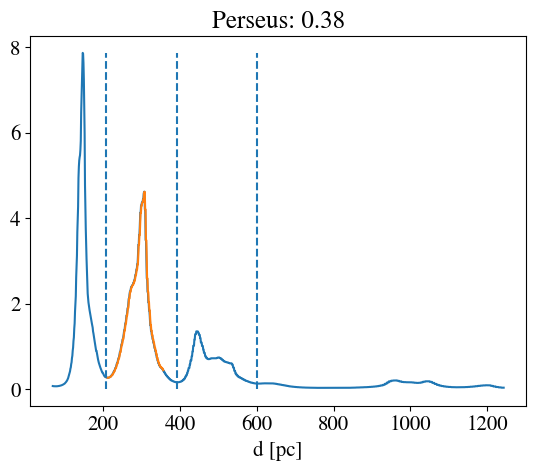

[138.9 118.9   3.7  23.7 208.  358. ] (150, 87, 87)
[ 138.9  118.9    3.7   23.7   68.  1250. ] (1182, 87, 87)
0.8228558


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


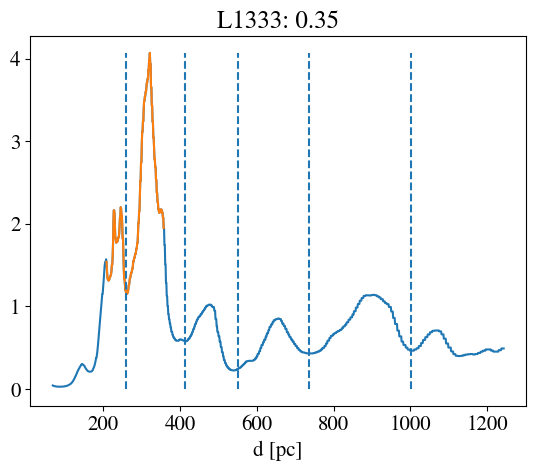

[-147.8 -167.8  -41.4  -21.4  212.   362. ] (150, 87, 86)
[-147.8 -167.8  -41.4  -21.4   68.  1250. ] (1182, 87, 86)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.1296041


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


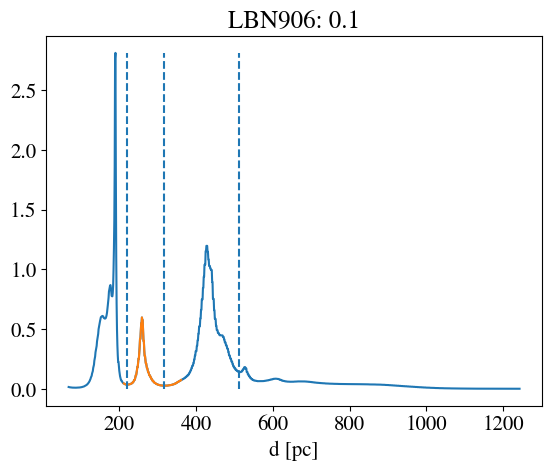

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


[-142.7 -163.6  -37.2  -16.   219.7  369.7] (150, 92, 91)
[-142.7 -163.6  -37.2  -16.    68.  1250. ] (1182, 92, 91)
0.14232703


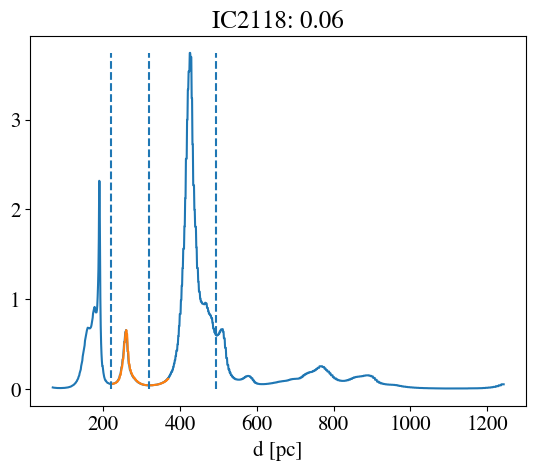

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[-141.6 -161.6  -38.4  -18.4  244.   394. ] (150, 87, 87)
[-141.6 -161.6  -38.4  -18.4   68.  1250. ] (1182, 87, 87)
0.16502486


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


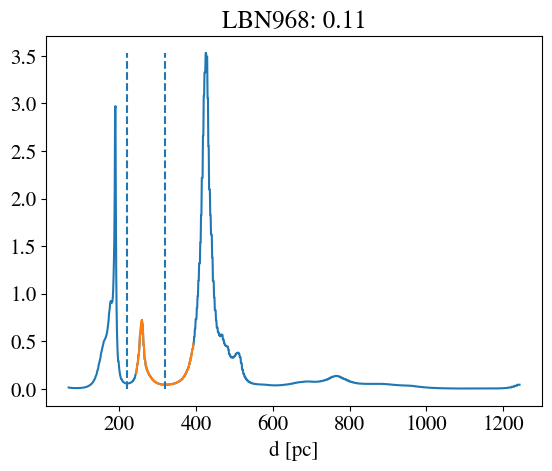

[125.9 105.9 -12.    8.  269.  419. ] (150, 87, 87)
[ 125.9  105.9  -12.     8.    68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.7161761


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


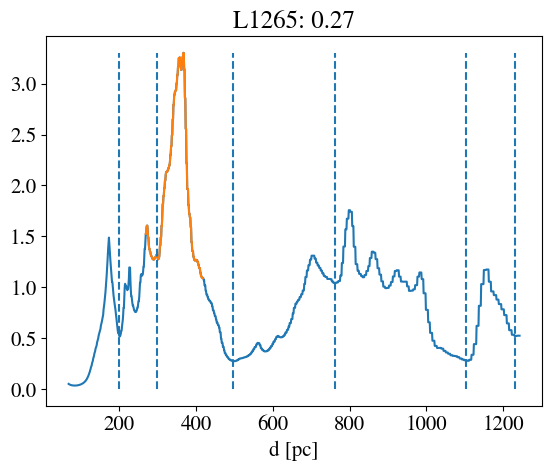

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[124.6 104.6   4.5  24.5 276.  426. ] (150, 87, 87)
[ 124.6  104.6    4.5   24.5   68.  1250. ] (1182, 87, 87)
1.1852196


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


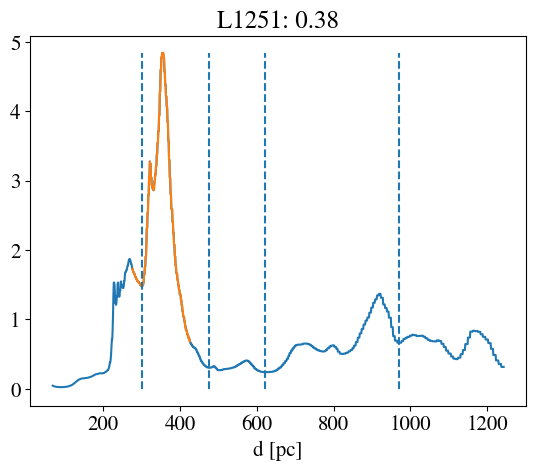

[168.5 133.4  25.2  50.7 285.5 435.5] (150, 111, 153)
[ 168.5  133.4   25.2   50.7   68.  1250. ] (1182, 111, 153)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.24814261


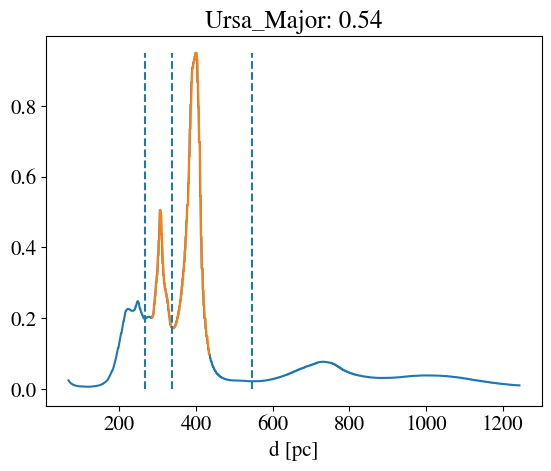

[121.8 101.8  10.2  30.2 291.  441. ] (150, 87, 87)
[ 121.8  101.8   10.2   30.2   68.  1250. ] (1182, 87, 87)
1.4425988


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


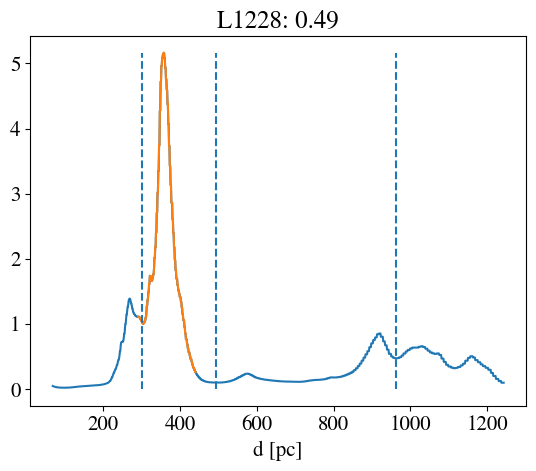

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[144.8 124.8  30.5  50.5 294.  444. ] (150, 87, 87)
[ 144.8  124.8   30.5   50.5   68.  1250. ] (1182, 87, 87)
0.23213078


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


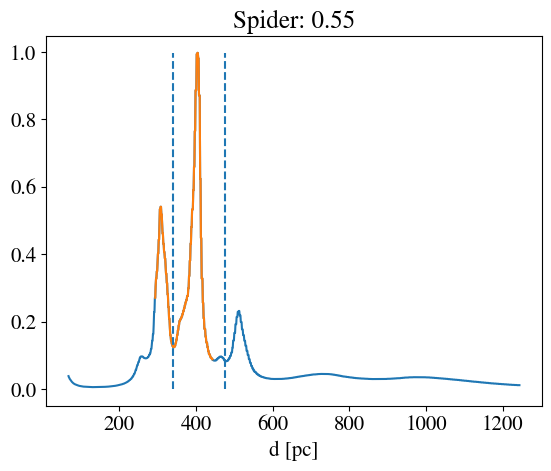

[-144.2 -164.2  -31.6  -11.6  299.   449. ] (150, 87, 87)
[-144.2 -164.2  -31.6  -11.6   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


1.6354431


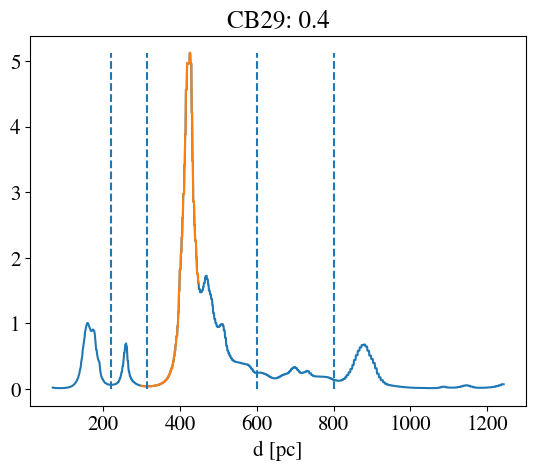

[-142.4 -162.4  -33.2  -12.8  301.5  451.5] (150, 89, 87)
[-142.4 -162.4  -33.2  -12.8   68.  1250. ] (1182, 89, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


1.4843762


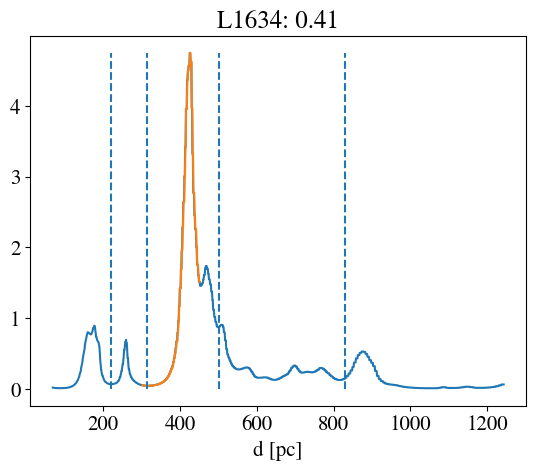

[139.5 113.5   7.3  47.9 310.3 460.3] (150, 177, 113)
[ 139.5  113.5    7.3   47.9   68.  1250. ] (1182, 177, 113)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.510508


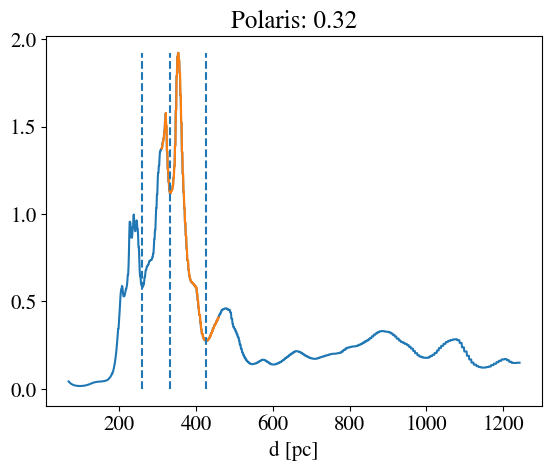

[-146.5 -166.5  -34.8  -14.8  317.   467. ] (150, 87, 87)
[-146.5 -166.5  -34.8  -14.8   68.  1250. ] (1182, 87, 87)
1.2264585


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


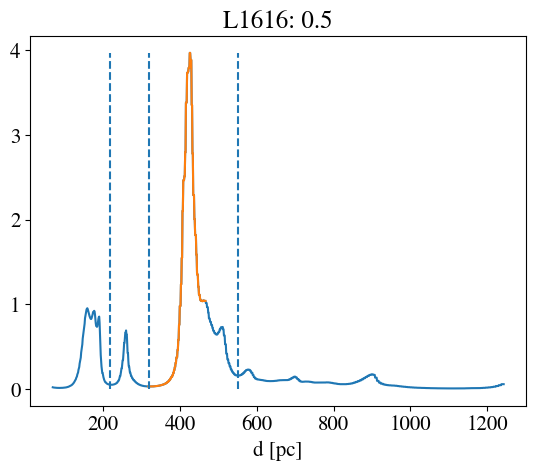

[-146.  -166.   -35.3  -15.3  323.   473. ] (150, 87, 87)
[-146.  -166.   -35.3  -15.3   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


1.1584713


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


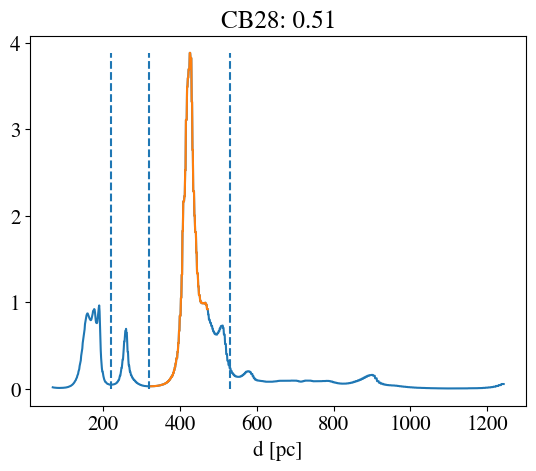

[-136.4 -156.4  -38.9  -18.9  333.   483. ] (150, 87, 87)
[-136.4 -156.4  -38.9  -18.9   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.7377201


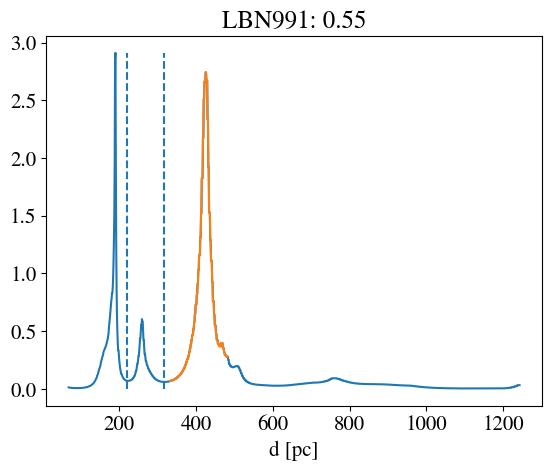

[-146.5 -166.5  -22.    -2.   339.   489. ] (150, 87, 87)
[-146.5 -166.5  -22.    -2.    68.  1250. ] (1182, 87, 87)
1.5809587


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


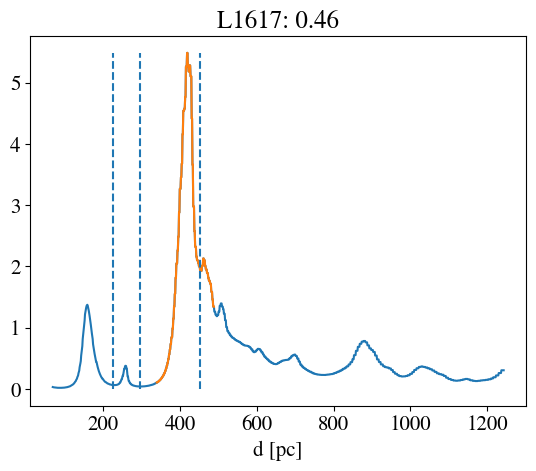

[-145.3 -165.3  -21.8   -1.8  343.   493. ] (150, 87, 87)
[-145.3 -165.3  -21.8   -1.8   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


1.5080191


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


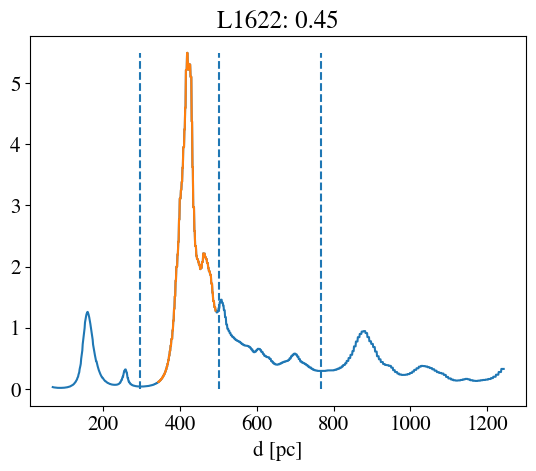

[-142.1 -168.7  -26.8   -3.3  355.8  505.8] (150, 102, 115)
[-142.1 -168.7  -26.8   -3.3   68.  1250. ] (1182, 102, 115)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


1.0956438


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


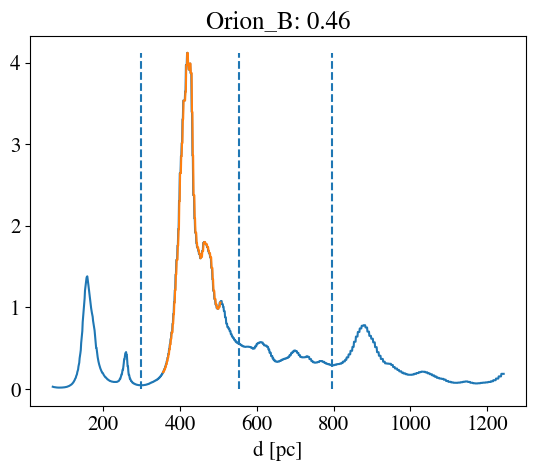

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[-135.3 -165.3  -30.1   -7.3  360.6  510.6] (150, 99, 131)
[-135.3 -165.3  -30.1   -7.3   68.  1250. ] (1182, 99, 131)
0.9309201


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


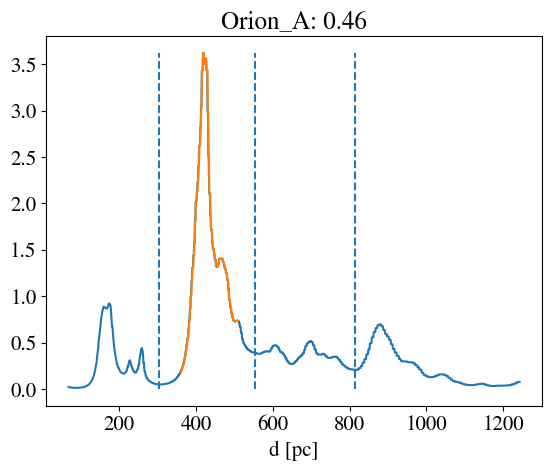

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[173.8 151.2 -19.5   2.1 377.  527. ] (150, 94, 99)
[ 173.8  151.2  -19.5    2.1   68.  1250. ] (1182, 94, 99)
0.51843333


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


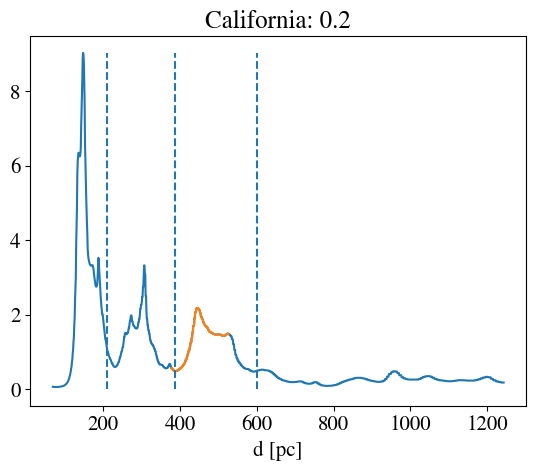

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


[ 99.5  79.5  28.4  48.4 406.  556. ] (150, 87, 87)
[  99.5   79.5   28.4   48.4   68.  1250. ] (1182, 87, 87)
0.028182315


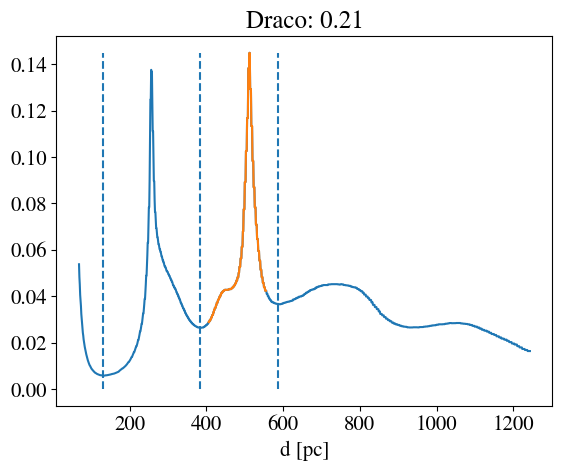

[ 42.9  18.1  -7.4  15.2 412.3 562.3] (150, 99, 108)
[  42.9   18.1   -7.4   15.2   68.  1250. ] (1182, 99, 108)
0.49461064


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


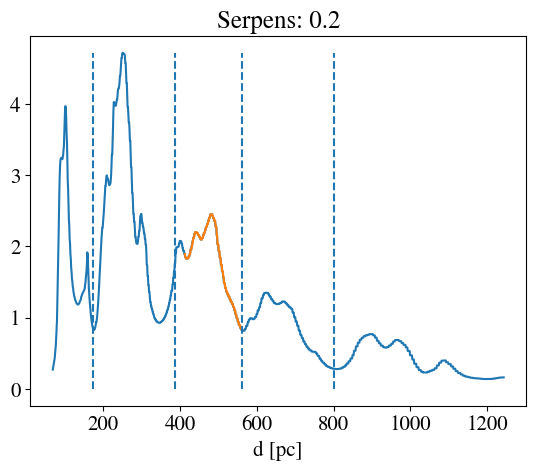

[ 1.061e+02  8.580e+01 -2.150e+01 -2.000e-01  4.135e+02  5.635e+02] (150, 93, 88)
[ 1.061e+02  8.580e+01 -2.150e+01 -2.000e-01  6.800e+01  1.250e+03] (1182, 93, 88)
0.12948161


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


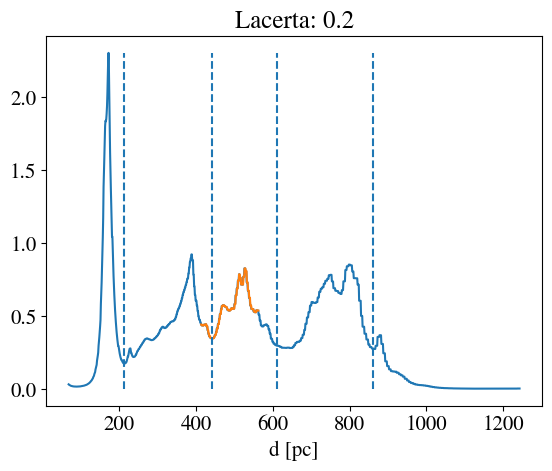

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[122.3 102.3   3.8  23.8 416.  566. ] (150, 87, 87)
[ 122.3  102.3    3.8   23.8   68.  1250. ] (1182, 87, 87)
0.27620733


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


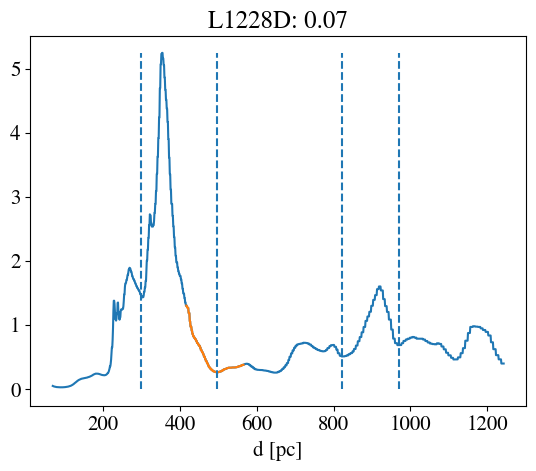

[102.6  81.3  -6.5  14.3 486.7 636.7] (150, 91, 92)
[ 102.6   81.3   -6.5   14.3   68.  1250. ] (1182, 91, 92)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.40002218


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


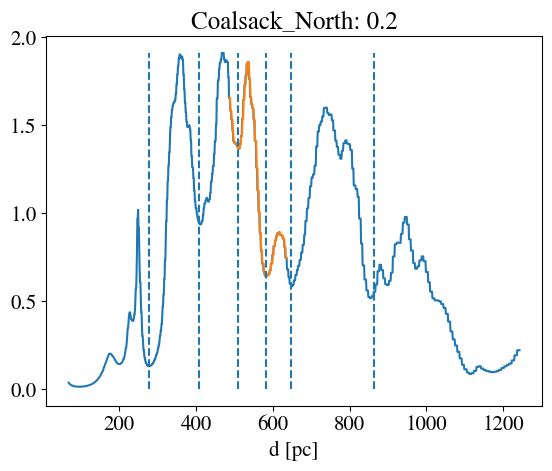

[126.1  93.5  -4.5  30.8 541.1 691.1] (150, 153, 141)
[ 126.1   93.5   -4.5   30.8   68.  1250. ] (1182, 153, 141)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.050329123


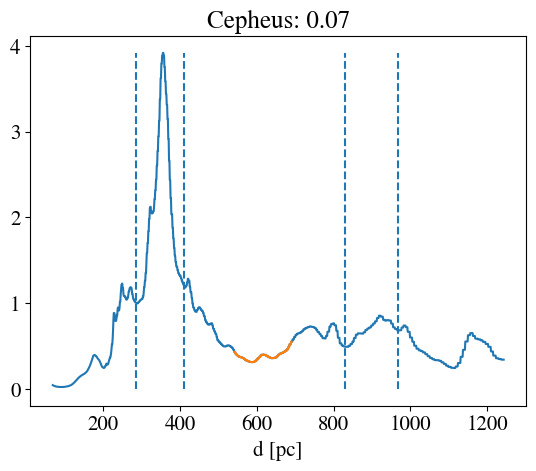

[100.7  80.2  -7.7  12.4 544.5 694.5] (150, 88, 89)
[ 100.7   80.2   -7.7   12.4   68.  1250. ] (1182, 88, 89)
0.28162602


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


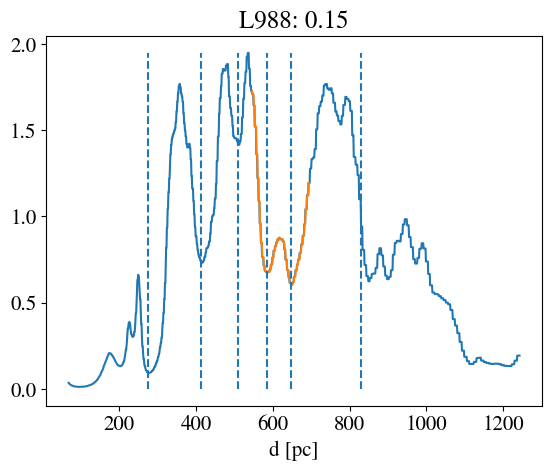

[138.9 118.9  -5.7  14.3 572.  722. ] (150, 87, 87)
[ 138.9  118.9   -5.7   14.3   68.  1250. ] (1182, 87, 87)
0.1793106


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


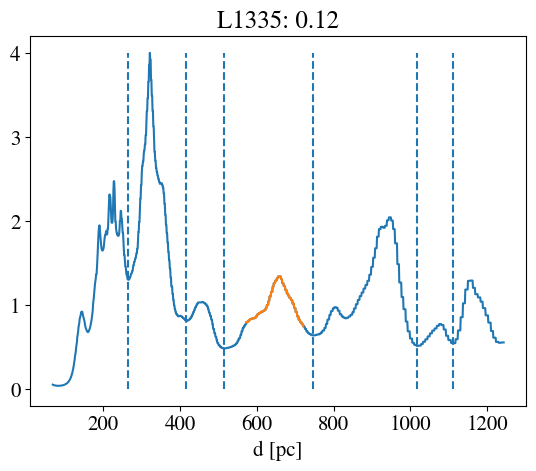

[ 99.8  79.5  -8.   12.2 576.  726. ] (150, 88, 88)
[  99.8   79.5   -8.    12.2   68.  1250. ] (1182, 88, 88)
0.29934114


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


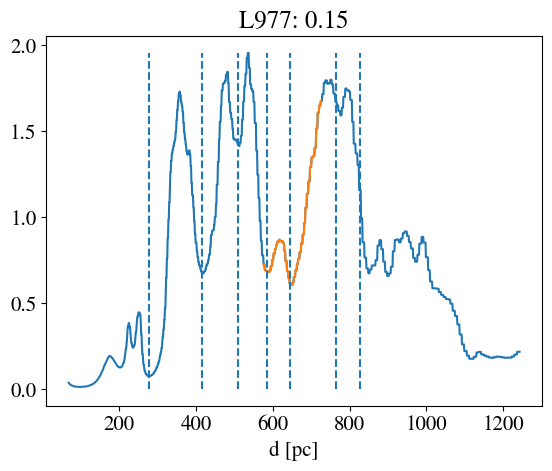

[-31.6 -53.1 -13.9   6.8 604.  754. ] (150, 90, 94)
[ -31.6  -53.1  -13.9    6.8   68.  1250. ] (1182, 90, 94)
0.18667528


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


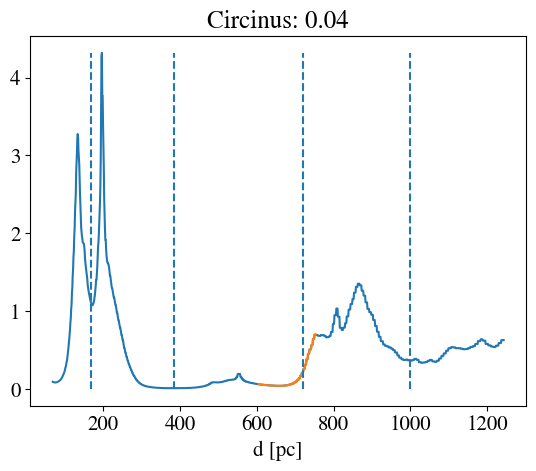

[-11.2 -31.2  -8.2  11.8 646.  796. ] (150, 87, 87)
[ -11.2  -31.2   -8.2   11.8   68.  1250. ] (1182, 87, 87)
0.15454042


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


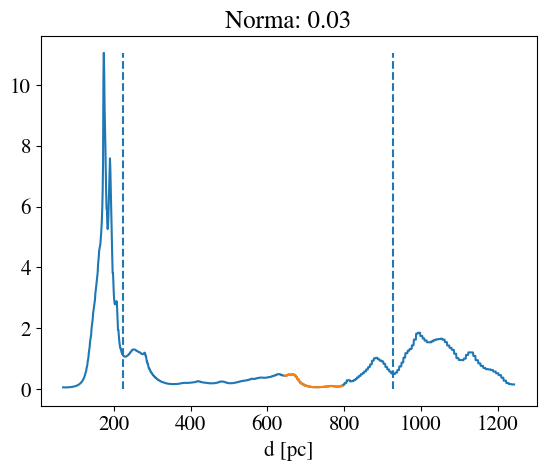

[-146.9 -169.6   -9.2   12.7  673.7  823.7] (150, 95, 98)
[-146.9 -169.6   -9.2   12.7   68.  1250. ] (1182, 95, 98)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.12706156


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


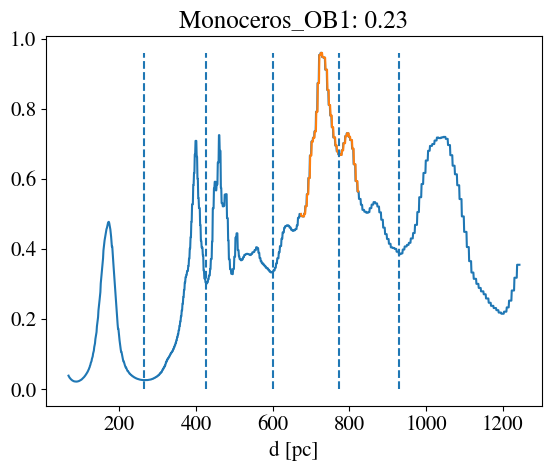

[104.4  83.4 -15.5   5.8 686.8 836.8] (150, 93, 91)
[ 104.4   83.4  -15.5    5.8   68.  1250. ] (1182, 93, 91)
0.18282047


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


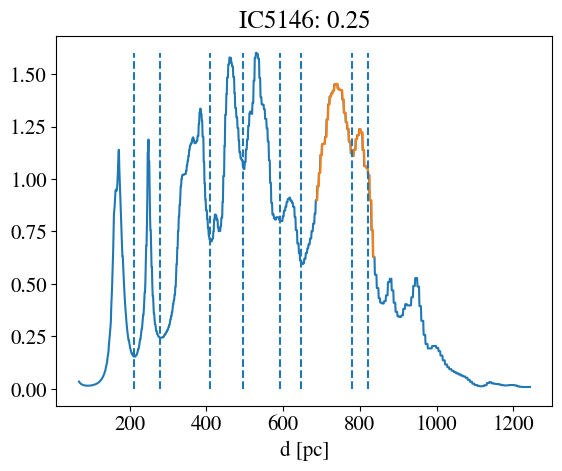

[ 96.6  71.7 -12.2  10.1 734.3 884.3] (150, 96, 108)
[  96.6   71.7  -12.2   10.1   68.  1250. ] (1182, 96, 108)
0.28491944


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


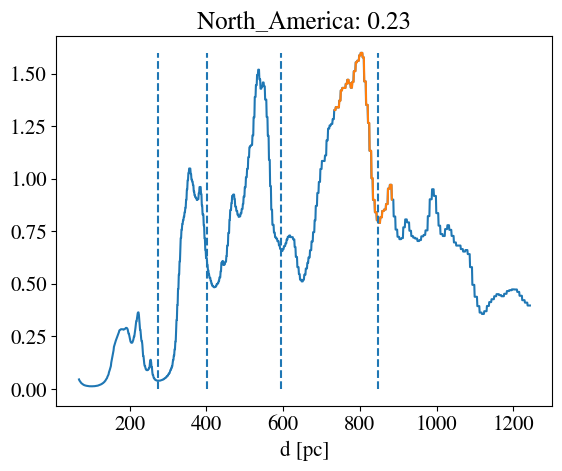

[-129.1 -157.   -22.9    2.3  780.8  930.8] (150, 110, 122)
[-129.1 -157.   -22.9    2.3   68.  1250. ] (1182, 110, 122)
0.19978592


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


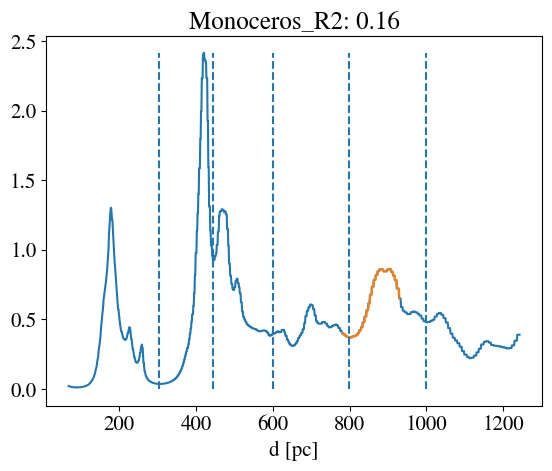

[140.  120.    1.5  21.5 783.  933. ] (150, 87, 87)
[ 140.   120.     1.5   21.5   68.  1250. ] (1182, 87, 87)
0.23976782


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


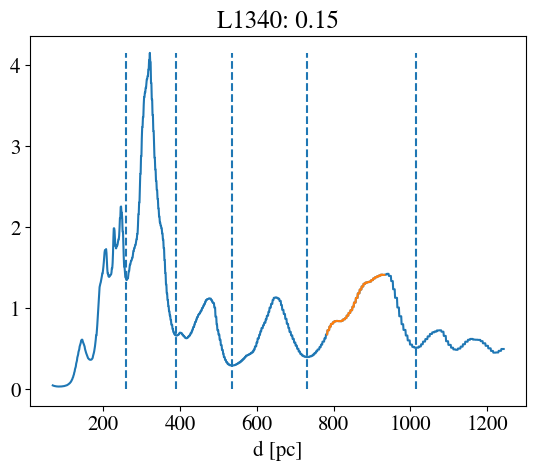

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[134.6 114.3  -7.4  13.3 793.  943. ] (150, 90, 88)
[ 134.6  114.3   -7.4   13.3   68.  1250. ] (1182, 90, 88)
0.20825088


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


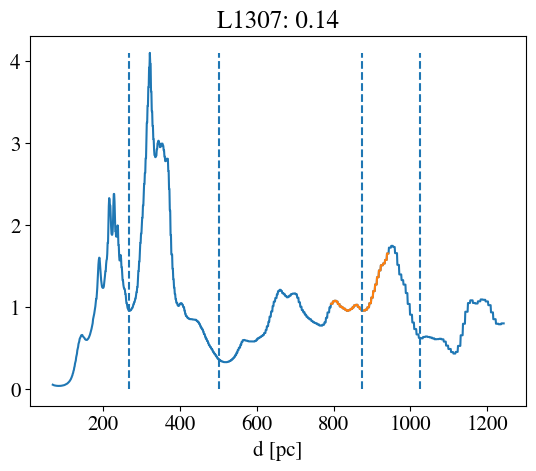

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[132.  112.  -11.4   8.6 831.  981. ] (150, 87, 87)
[ 132.   112.   -11.4    8.6   68.  1250. ] (1182, 87, 87)
0.19614905


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


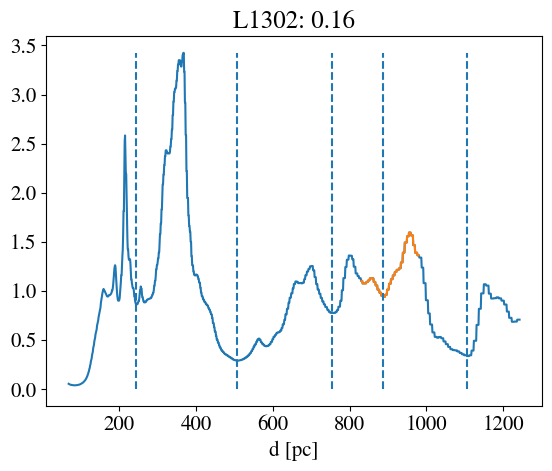

[ -83.9 -105.7   -8.8   12.5  842.4  992.4] (150, 93, 94)
[ -83.9 -105.7   -8.8   12.5   68.  1250. ] (1182, 93, 94)
0.3193263


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


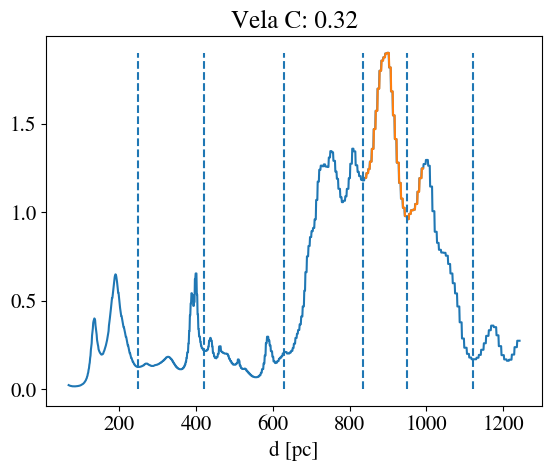

[110.4  88.9  -6.6  14.7 842.8 992.8] (150, 93, 93)
[ 110.4   88.9   -6.6   14.7   68.  1250. ] (1182, 93, 93)
0.22219408


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


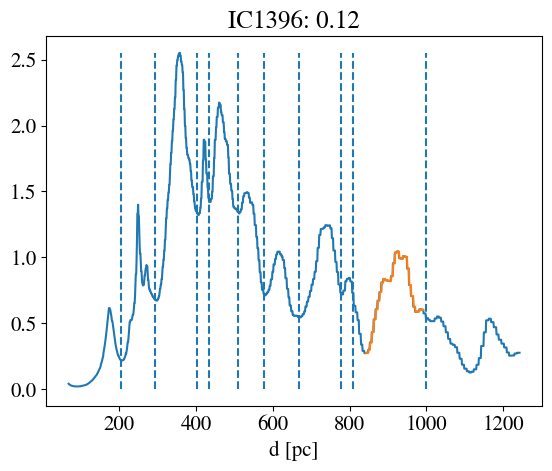

[136.8 115.6 -10.8   9.4 847.  997. ] (150, 87, 92)
[ 136.8  115.6  -10.8    9.4   68.  1250. ] (1182, 87, 92)
0.27981058


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


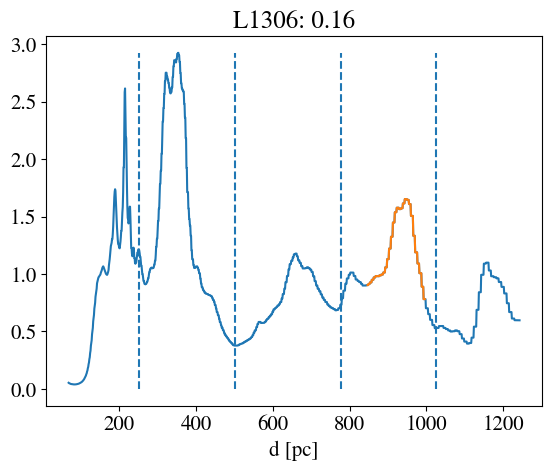

[ 143.6  122.8   -1.1   19.3  861.  1011. ] (150, 88, 90)
[ 1.436e+02  1.228e+02 -1.100e+00  1.930e+01  6.800e+01  1.250e+03] (1182, 88, 90)
0.4027099


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/3133420683.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


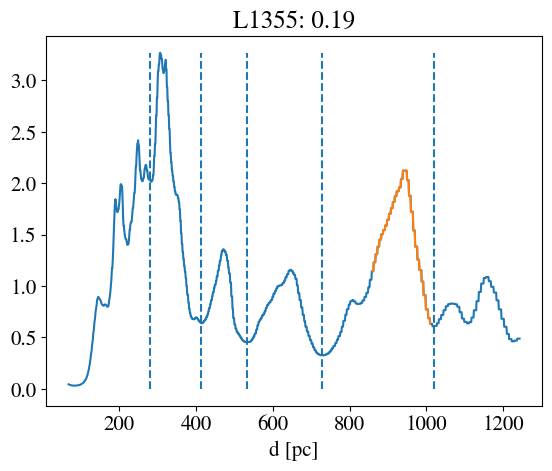

[([<matplotlib.lines.Line2D at 0x4e80cab50>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Aquila_South: 0.49'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4e813ed10>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Ophiuchus: 0.59'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4e8153e90>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Taurus: 0.49'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4e8227390>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Corona_Australis: 0.6'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4e828b9d0>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Lupus: 0.5'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4e82f3e10>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Pipe: 0.48'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4e8201350>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Chamaeleon: 0.72'),
  None,
  None),
 (

In [ ]:
[(
plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
plt.plot(np.arange(cube.shape[0])+coords[4],np.nanmean(cube,axis=(1,2))),

plt.vlines(table2.iloc[i].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),

plt.xlabel('d [pc]'),
# plt.xlim(table1['d_mean(pc)'].iloc[i]+np.array([-1,1])*300),
plt.title(table1['cloud'].iloc[i]+': '+str(round(np.nansum(cube)/np.nansum(cubel),2))),
# plt.plot(np.nanmean(cube,axis=(1,2)))

print(np.nanstd(np.nanmean(cube,axis=(1,2)))),

plt.show()
) 

for i in range(len(table1))#in_edenhfr #range(26) 
for cube,coords in [get_cloud_info(i,ednhfr_cm3,table1,75)]
for cubel,coordsl in [get_cloud_info(i,ednhfr_cm3,table1,'full')] 
]

[ 49.3  26.8 -29.1  -5.1  68.  207.2] (139, 104, 97)
[  49.3   26.8  -29.1   -5.1   68.  1250. ] (1182, 104, 97)
1.4687517


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


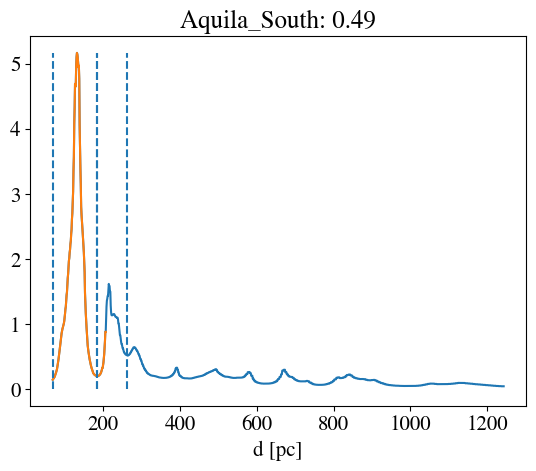

[ 18.4 -20.7   2.   32.   68.  214.4] (146, 131, 170)
[  18.4  -20.7    2.    32.    68.  1250. ] (1182, 131, 170)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


3.0427504


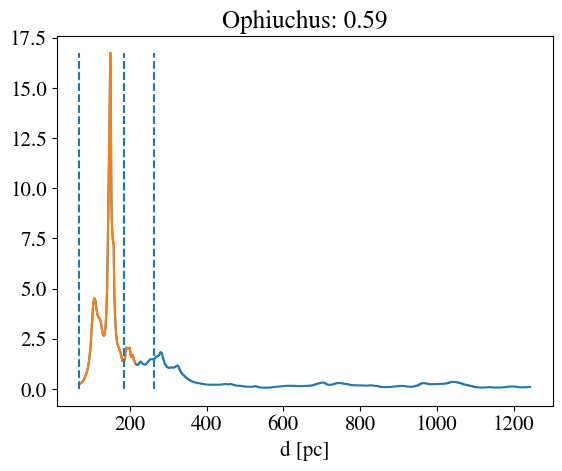

[185.8 156.2 -29.2  -2.3  71.9 221.9] (150, 117, 129)
[ 185.8  156.2  -29.2   -2.3   68.  1250. ] (1182, 117, 129)
2.7221355


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


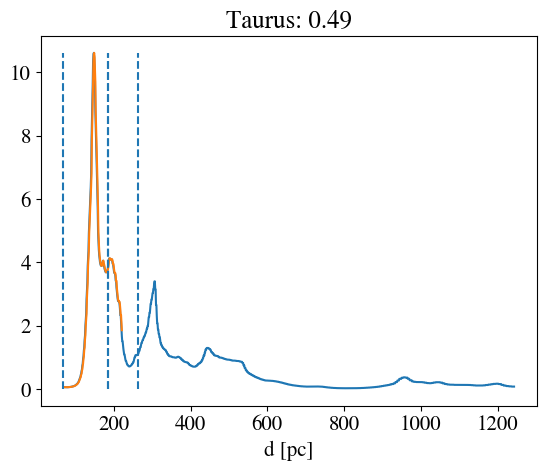

[ 10.8 -10.5 -31.   -7.8  80.7 230.7] (150, 101, 93)
[  10.8  -10.5  -31.    -7.8   68.  1250. ] (1182, 101, 93)
0.7921431


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


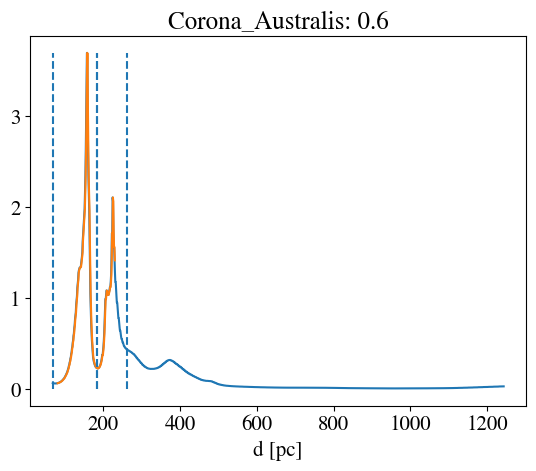

[ -2.7 -31.3  -3.6  27.4  93.5 243.5] (150, 135, 124)
[  -2.7  -31.3   -3.6   27.4   68.  1250. ] (1182, 135, 124)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


2.255836


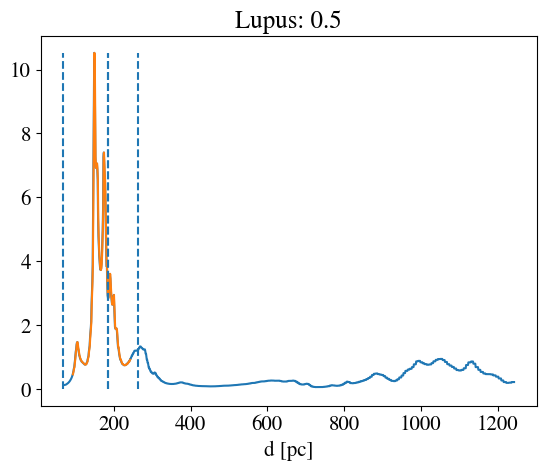

[  6.9 -13.1  -2.7  17.3 105.  255. ] (150, 87, 87)
[   6.9  -13.1   -2.7   17.3   68.  1250. ] (1182, 87, 87)
4.0010366


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


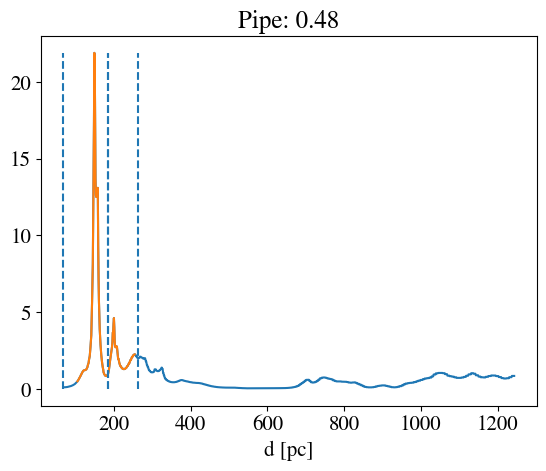

[-46.7 -72.5 -26.7  -4.2 112.  262. ] (150, 97, 112)
[ -46.7  -72.5  -26.7   -4.2   68.  1250. ] (1182, 97, 112)
1.7371932


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


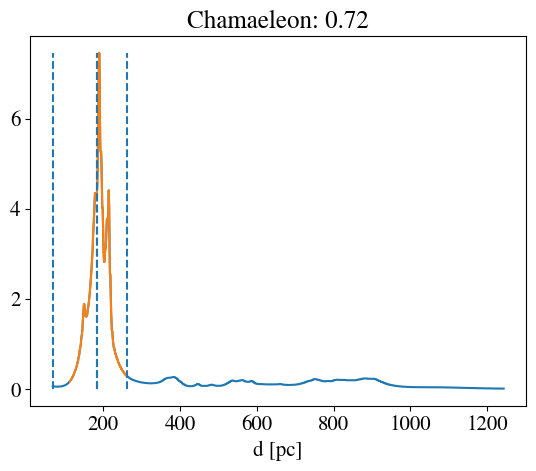

[-47.1 -70.  -12.6  13.1 113.8 263.8] (150, 112, 99)
[ -47.1  -70.   -12.6   13.1   68.  1250. ] (1182, 112, 99)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


1.8956246


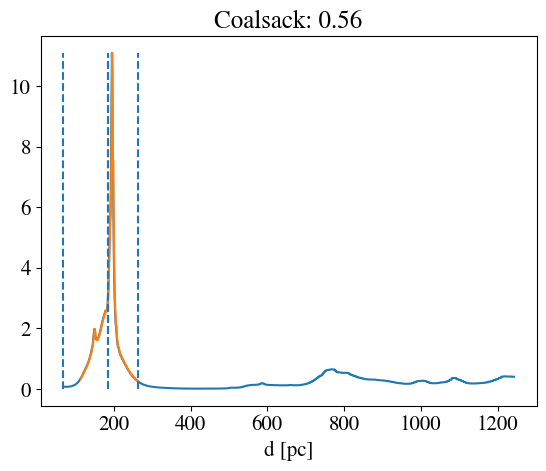

[ 55.1  32.8  -2.1  18.9 150.3 300.3] (150, 92, 97)
[  55.1   32.8   -2.1   18.9   68.  1250. ] (1182, 92, 97)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.6971981


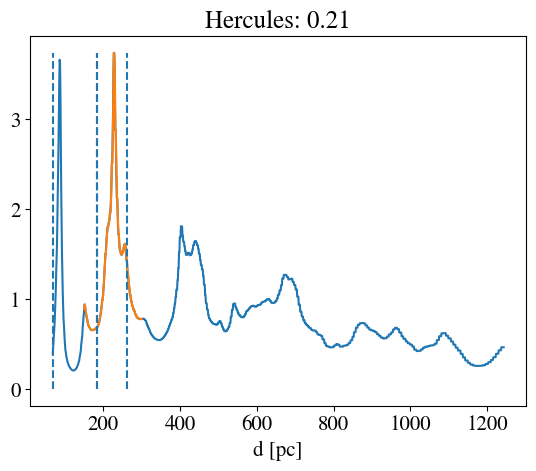

[-146.3 -166.3  -40.3  -20.3  157.   307. ] (150, 87, 87)
[-146.3 -166.3  -40.3  -20.3   68.  1250. ] (1182, 87, 87)
0.4604433


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


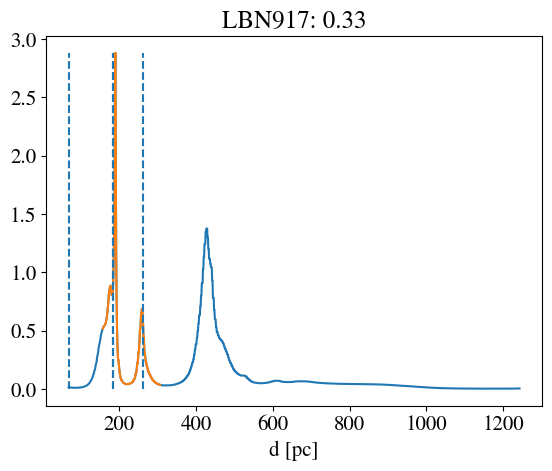

[ 31.8   6.   -0.8  26.6 161.6 311.6] (150, 119, 112)
[ 3.18e+01  6.00e+00 -8.00e-01  2.66e+01  6.80e+01  1.25e+03] (1182, 119, 112)
0.54041916


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


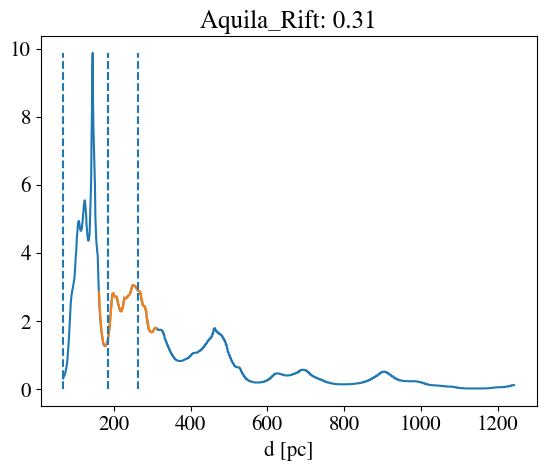

[-144.4 -164.4  -32.   -12.   182.   332. ] (150, 87, 87)
[-144.4 -164.4  -32.   -12.    68.  1250. ] (1182, 87, 87)
0.17374405


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


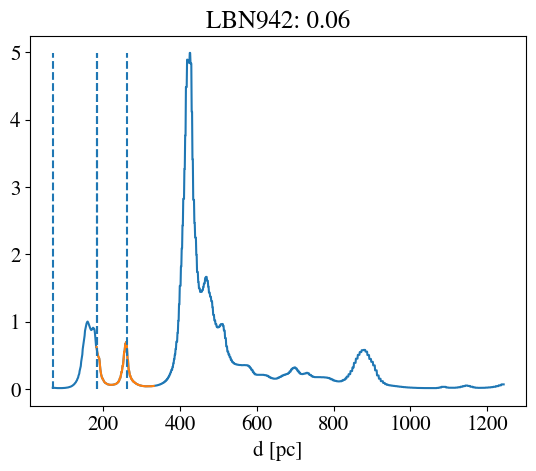

[115.6  78.8 -51.3 -20.6 185.2 335.2] (150, 133, 160)
[ 115.6   78.8  -51.3  -20.6   68.  1250. ] (1182, 133, 160)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.49440354


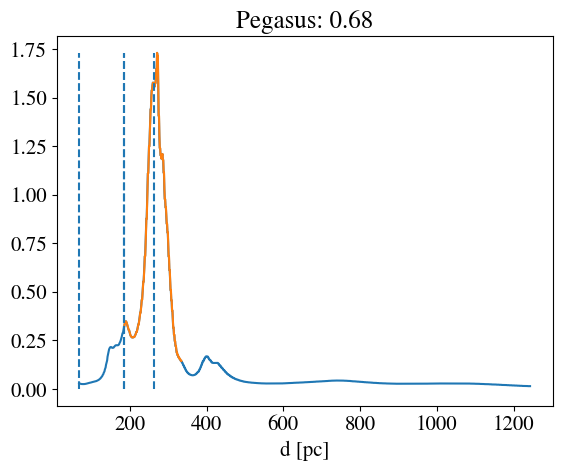

[-141.6 -161.6  -32.2  -12.2  199.   349. ] (150, 87, 87)
[-141.6 -161.6  -32.2  -12.2   68.  1250. ] (1182, 87, 87)
0.15037392


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


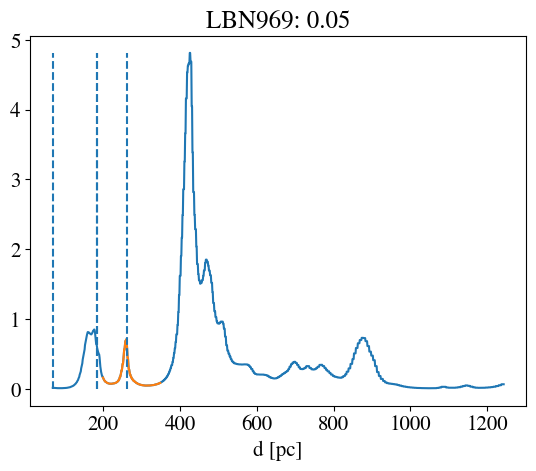

[158.8 134.8   7.2  27.8 205.6 355.6] (150, 89, 105)
[ 158.8  134.8    7.2   27.8   68.  1250. ] (1182, 89, 105)
0.7461379


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


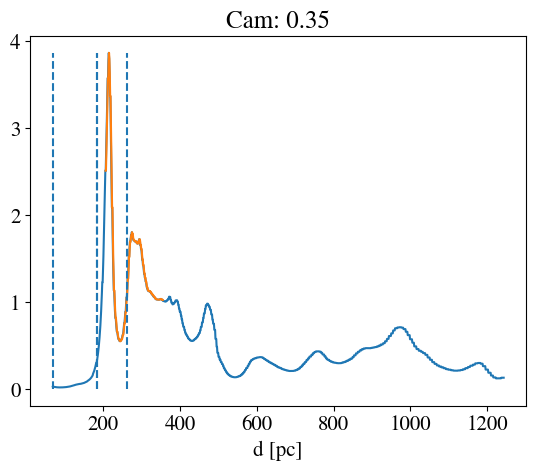

[170.8 147.5 -32.8  -6.3 206.8 356.8] (150, 115, 102)
[ 170.8  147.5  -32.8   -6.3   68.  1250. ] (1182, 115, 102)
1.2681462


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


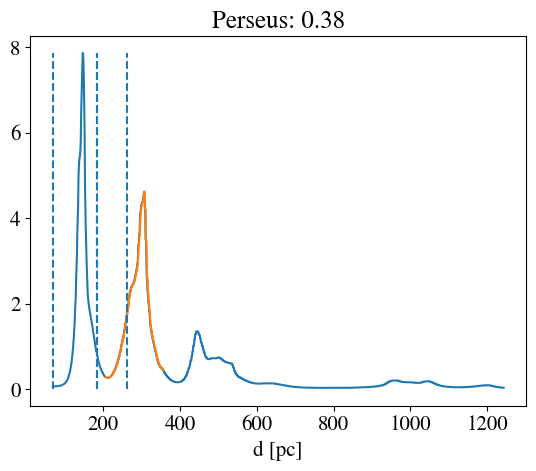

[138.9 118.9   3.7  23.7 208.  358. ] (150, 87, 87)
[ 138.9  118.9    3.7   23.7   68.  1250. ] (1182, 87, 87)
0.8228558


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


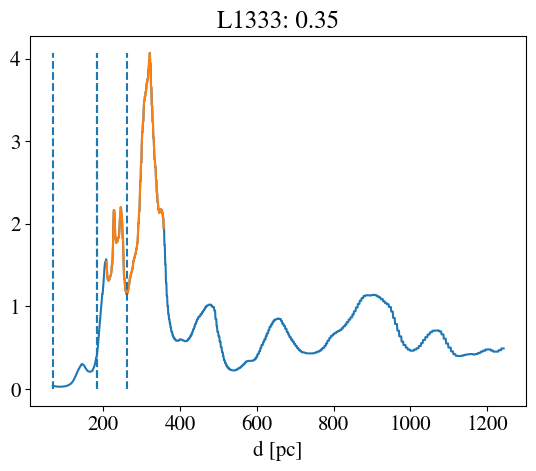

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[-147.8 -167.8  -41.4  -21.4  212.   362. ] (150, 87, 86)
[-147.8 -167.8  -41.4  -21.4   68.  1250. ] (1182, 87, 86)
0.1296041


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


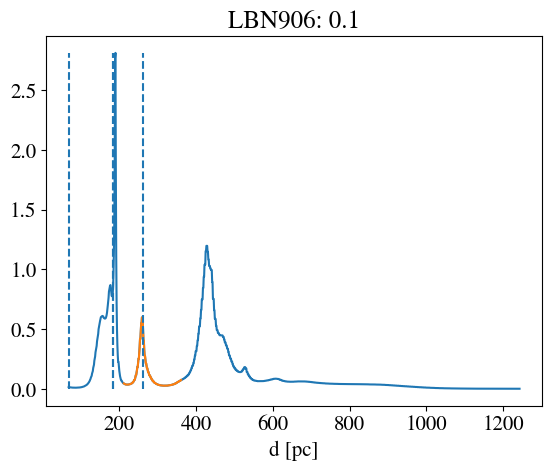

[-142.7 -163.6  -37.2  -16.   219.7  369.7] (150, 92, 91)
[-142.7 -163.6  -37.2  -16.    68.  1250. ] (1182, 92, 91)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.14232703


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


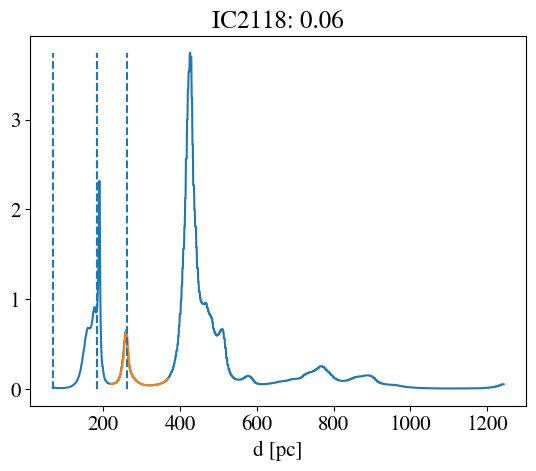

[-141.6 -161.6  -38.4  -18.4  244.   394. ] (150, 87, 87)
[-141.6 -161.6  -38.4  -18.4   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.16502486


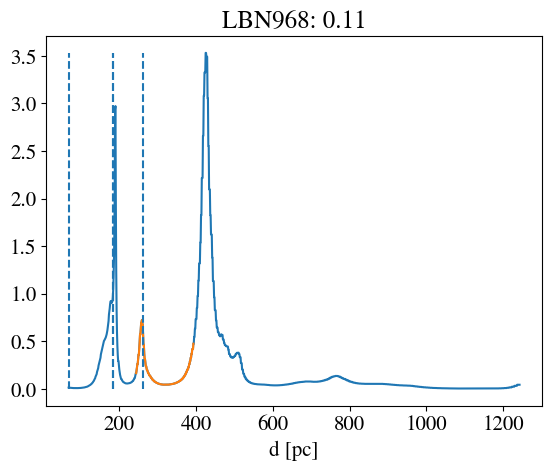

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[125.9 105.9 -12.    8.  269.  419. ] (150, 87, 87)
[ 125.9  105.9  -12.     8.    68.  1250. ] (1182, 87, 87)
0.7161761


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


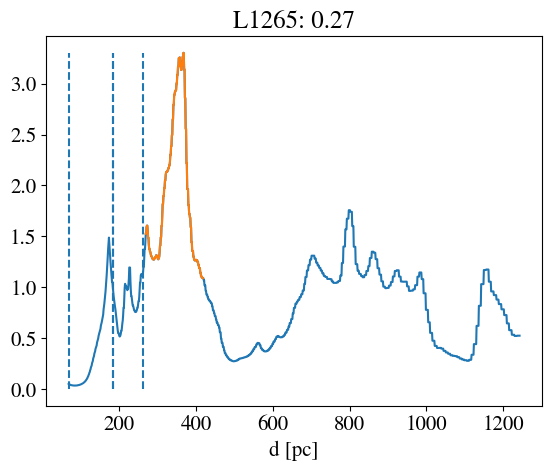

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[124.6 104.6   4.5  24.5 276.  426. ] (150, 87, 87)
[ 124.6  104.6    4.5   24.5   68.  1250. ] (1182, 87, 87)
1.1852196


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


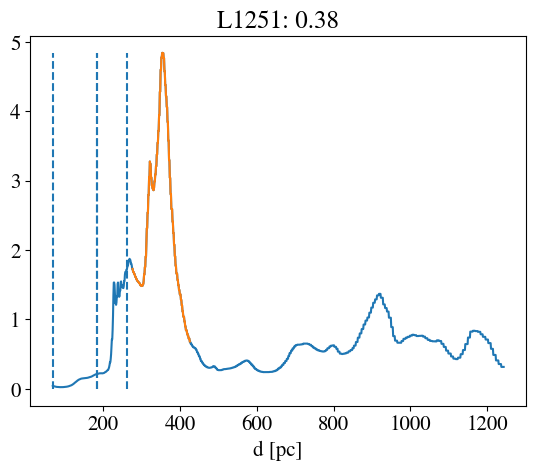

[168.5 133.4  25.2  50.7 285.5 435.5] (150, 111, 153)
[ 168.5  133.4   25.2   50.7   68.  1250. ] (1182, 111, 153)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.24814261


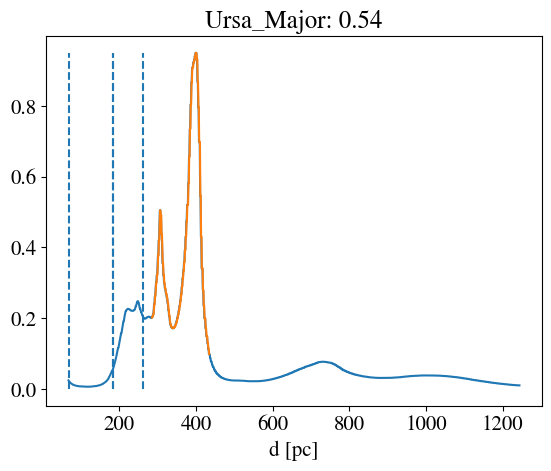

[121.8 101.8  10.2  30.2 291.  441. ] (150, 87, 87)
[ 121.8  101.8   10.2   30.2   68.  1250. ] (1182, 87, 87)
1.4425988


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


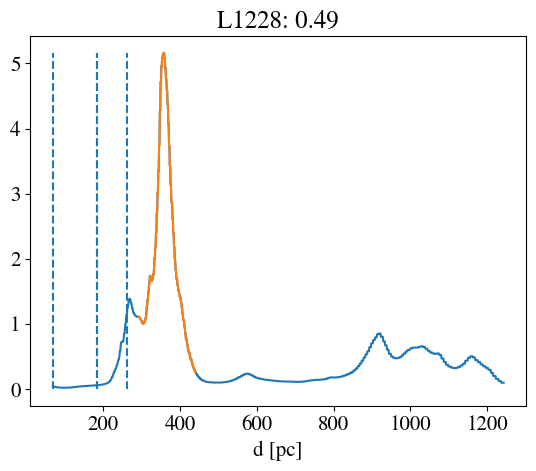

[144.8 124.8  30.5  50.5 294.  444. ] (150, 87, 87)
[ 144.8  124.8   30.5   50.5   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.23213078


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


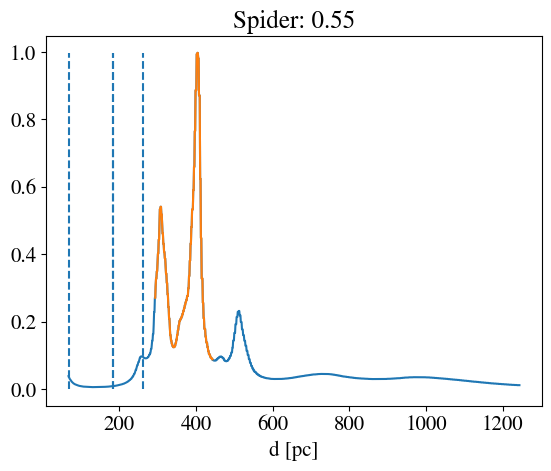

[-144.2 -164.2  -31.6  -11.6  299.   449. ] (150, 87, 87)
[-144.2 -164.2  -31.6  -11.6   68.  1250. ] (1182, 87, 87)
1.6354431


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


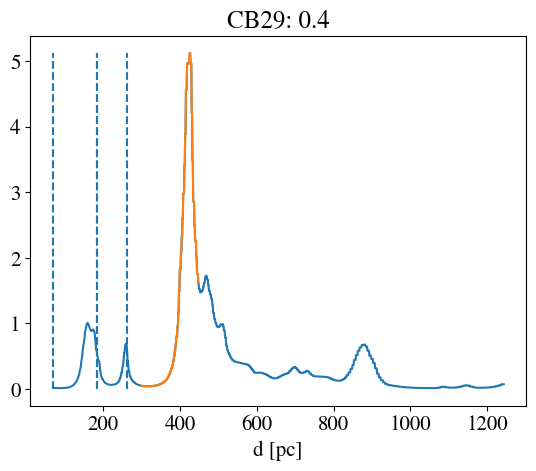

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[-142.4 -162.4  -33.2  -12.8  301.5  451.5] (150, 89, 87)
[-142.4 -162.4  -33.2  -12.8   68.  1250. ] (1182, 89, 87)
1.4843762


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


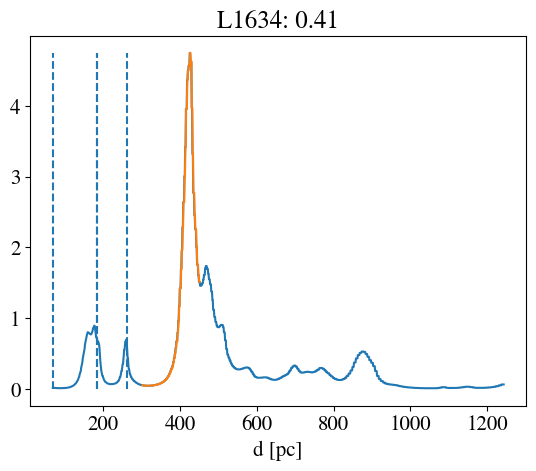

[139.5 113.5   7.3  47.9 310.3 460.3] (150, 177, 113)
[ 139.5  113.5    7.3   47.9   68.  1250. ] (1182, 177, 113)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.510508


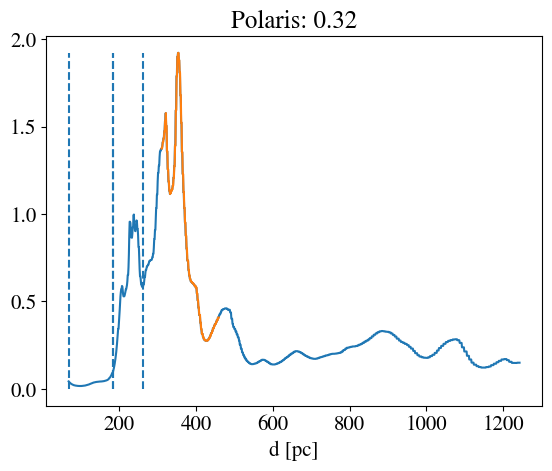

[-146.5 -166.5  -34.8  -14.8  317.   467. ] (150, 87, 87)
[-146.5 -166.5  -34.8  -14.8   68.  1250. ] (1182, 87, 87)
1.2264585


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


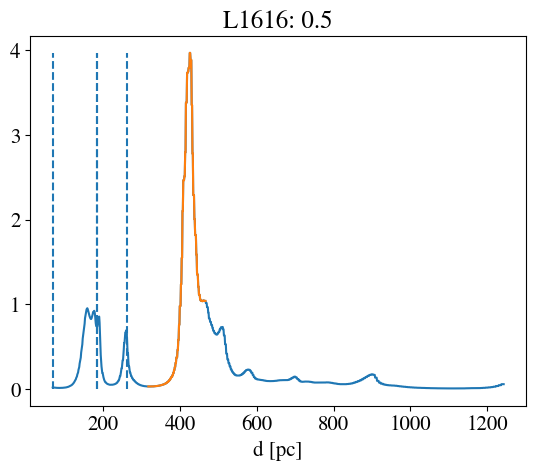

[-146.  -166.   -35.3  -15.3  323.   473. ] (150, 87, 87)
[-146.  -166.   -35.3  -15.3   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


1.1584713


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


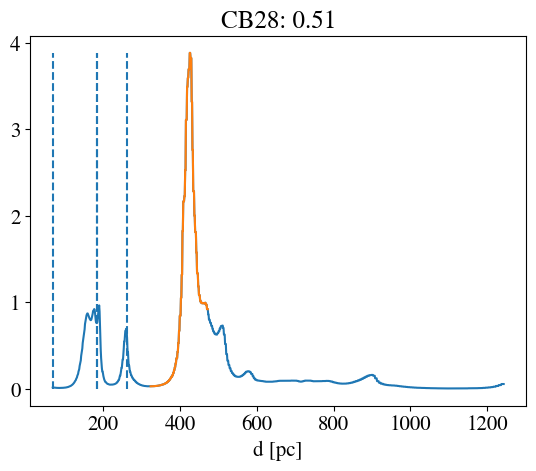

[-136.4 -156.4  -38.9  -18.9  333.   483. ] (150, 87, 87)
[-136.4 -156.4  -38.9  -18.9   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.7377201


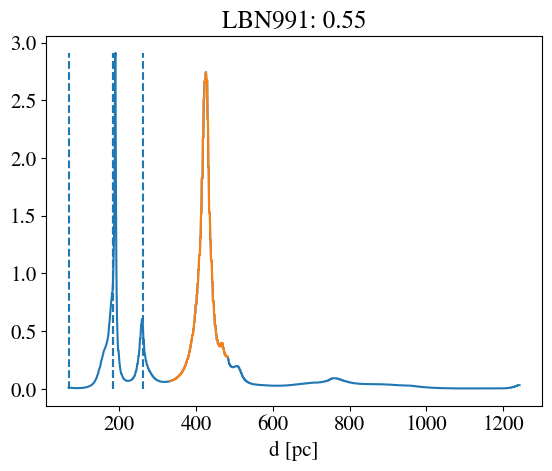

[-146.5 -166.5  -22.    -2.   339.   489. ] (150, 87, 87)
[-146.5 -166.5  -22.    -2.    68.  1250. ] (1182, 87, 87)
1.5809587


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


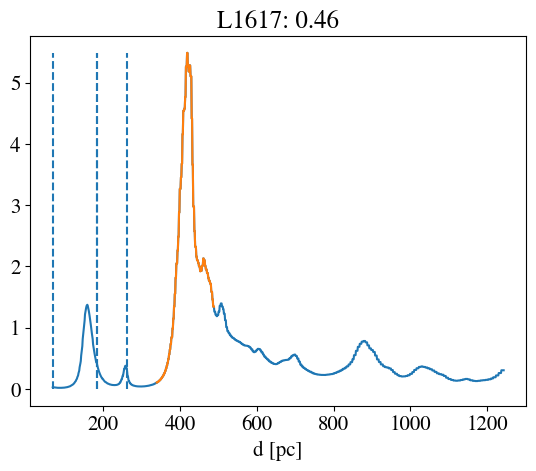

[-145.3 -165.3  -21.8   -1.8  343.   493. ] (150, 87, 87)
[-145.3 -165.3  -21.8   -1.8   68.  1250. ] (1182, 87, 87)
1.5080191


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


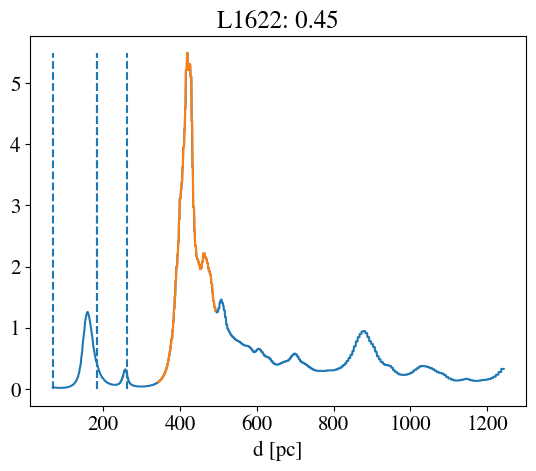

[-142.1 -168.7  -26.8   -3.3  355.8  505.8] (150, 102, 115)
[-142.1 -168.7  -26.8   -3.3   68.  1250. ] (1182, 102, 115)
1.0956438


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


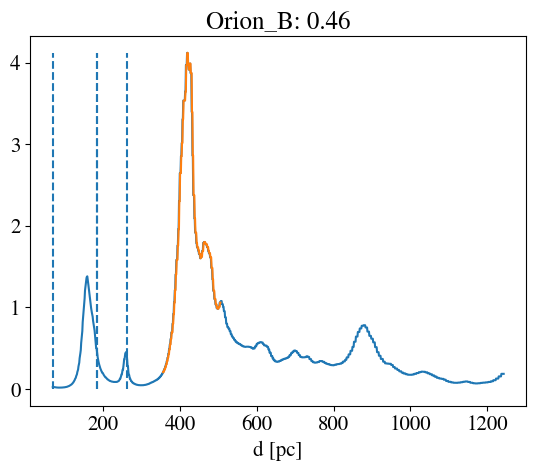

[-135.3 -165.3  -30.1   -7.3  360.6  510.6] (150, 99, 131)
[-135.3 -165.3  -30.1   -7.3   68.  1250. ] (1182, 99, 131)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.9309201


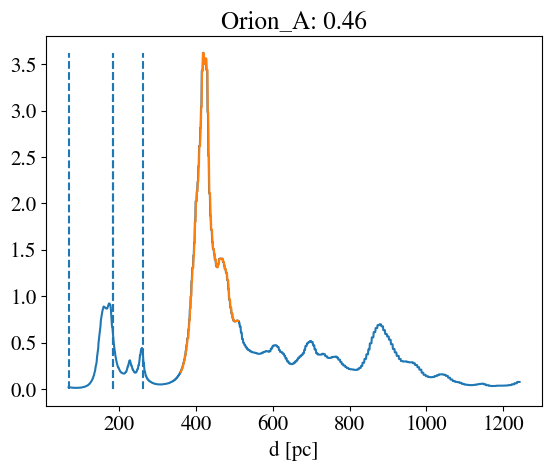

[173.8 151.2 -19.5   2.1 377.  527. ] (150, 94, 99)
[ 173.8  151.2  -19.5    2.1   68.  1250. ] (1182, 94, 99)
0.51843333


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


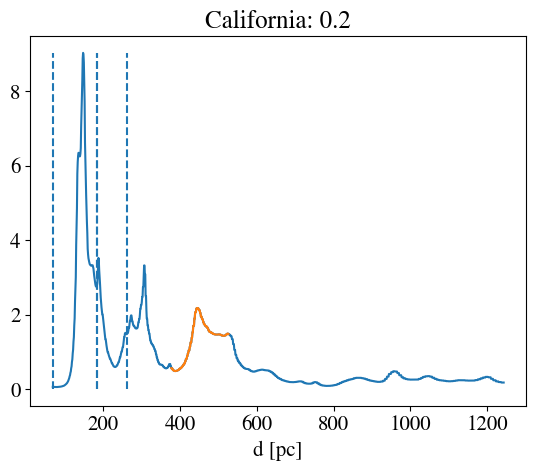

[ 99.5  79.5  28.4  48.4 406.  556. ] (150, 87, 87)
[  99.5   79.5   28.4   48.4   68.  1250. ] (1182, 87, 87)
0.028182315


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


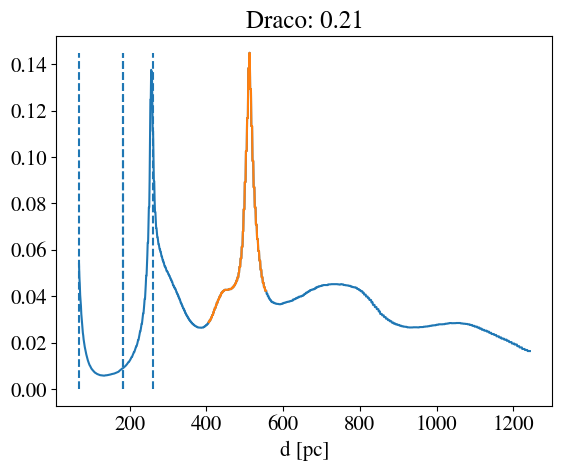

[ 42.9  18.1  -7.4  15.2 412.3 562.3] (150, 99, 108)
[  42.9   18.1   -7.4   15.2   68.  1250. ] (1182, 99, 108)
0.49461064


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


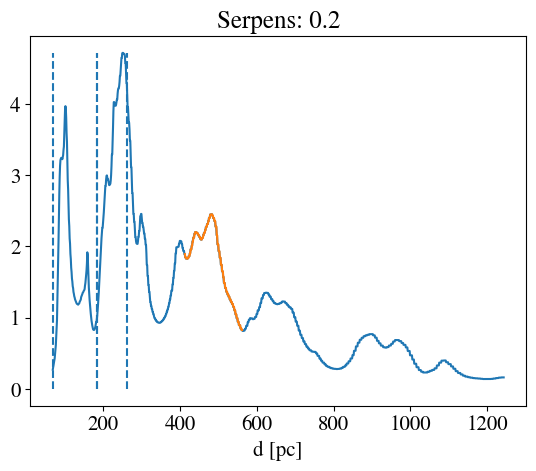

[ 1.061e+02  8.580e+01 -2.150e+01 -2.000e-01  4.135e+02  5.635e+02] (150, 93, 88)
[ 1.061e+02  8.580e+01 -2.150e+01 -2.000e-01  6.800e+01  1.250e+03] (1182, 93, 88)
0.12948161


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


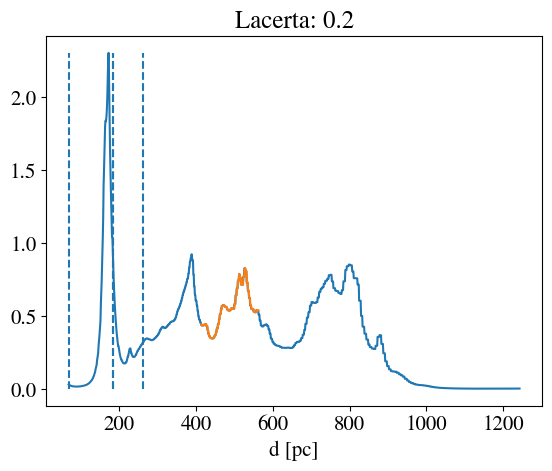

[122.3 102.3   3.8  23.8 416.  566. ] (150, 87, 87)
[ 122.3  102.3    3.8   23.8   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.27620733


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


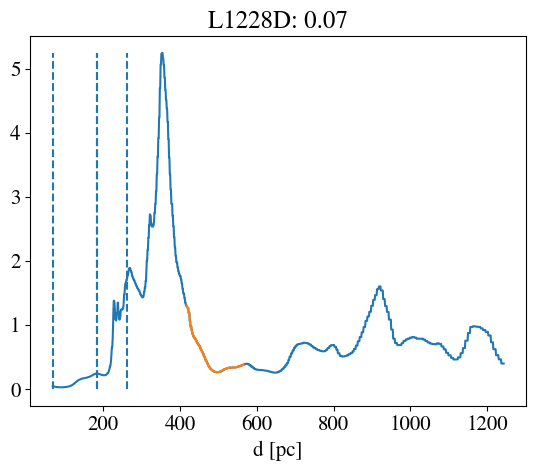

[102.6  81.3  -6.5  14.3 486.7 636.7] (150, 91, 92)
[ 102.6   81.3   -6.5   14.3   68.  1250. ] (1182, 91, 92)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.40002218


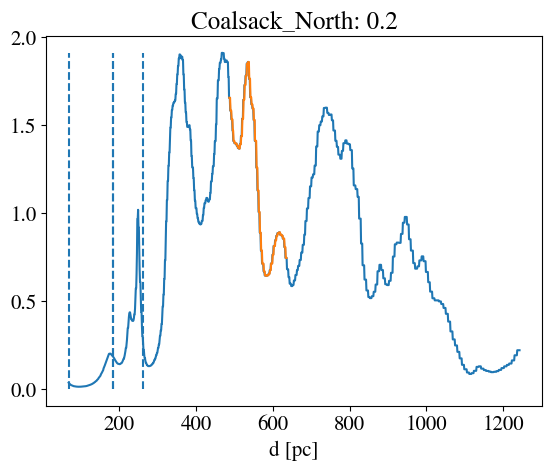

[126.1  93.5  -4.5  30.8 541.1 691.1] (150, 153, 141)
[ 126.1   93.5   -4.5   30.8   68.  1250. ] (1182, 153, 141)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.050329123


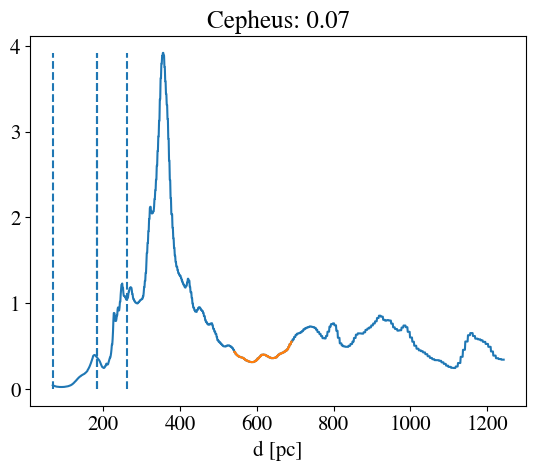

[100.7  80.2  -7.7  12.4 544.5 694.5] (150, 88, 89)
[ 100.7   80.2   -7.7   12.4   68.  1250. ] (1182, 88, 89)
0.28162602


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


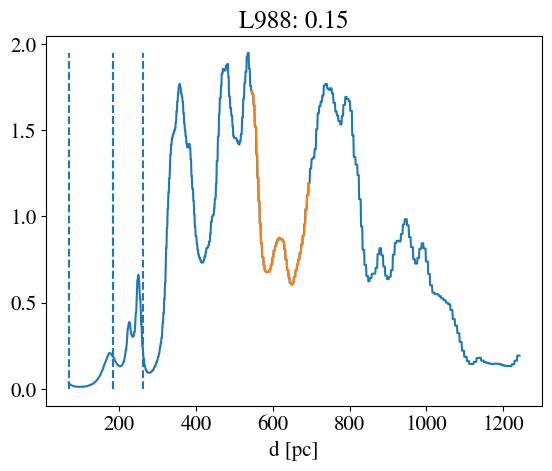

[138.9 118.9  -5.7  14.3 572.  722. ] (150, 87, 87)
[ 138.9  118.9   -5.7   14.3   68.  1250. ] (1182, 87, 87)
0.1793106


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


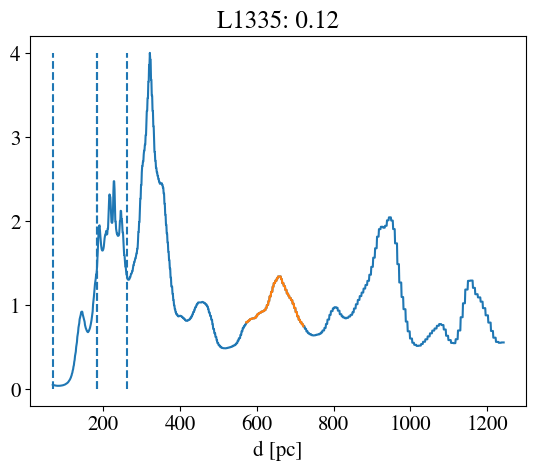

[ 99.8  79.5  -8.   12.2 576.  726. ] (150, 88, 88)
[  99.8   79.5   -8.    12.2   68.  1250. ] (1182, 88, 88)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


0.29934114


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


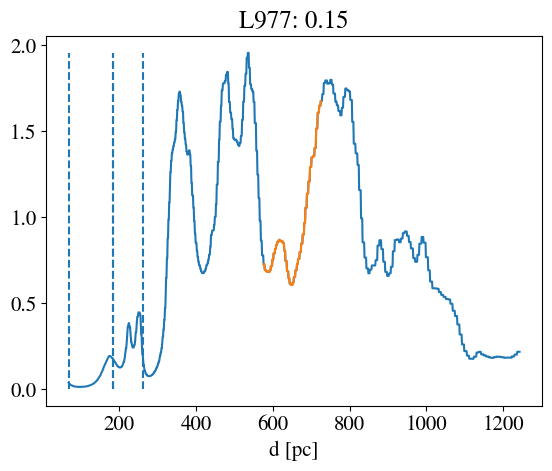

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),


[-31.6 -53.1 -13.9   6.8 604.  754. ] (150, 90, 94)
[ -31.6  -53.1  -13.9    6.8   68.  1250. ] (1182, 90, 94)
0.18667528


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


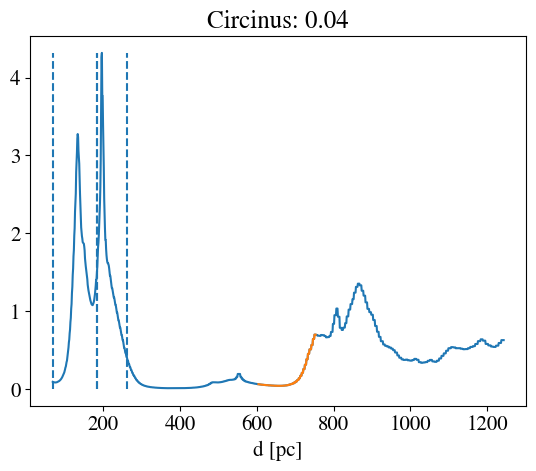

[-11.2 -31.2  -8.2  11.8 646.  796. ] (150, 87, 87)
[ -11.2  -31.2   -8.2   11.8   68.  1250. ] (1182, 87, 87)
0.15454042


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


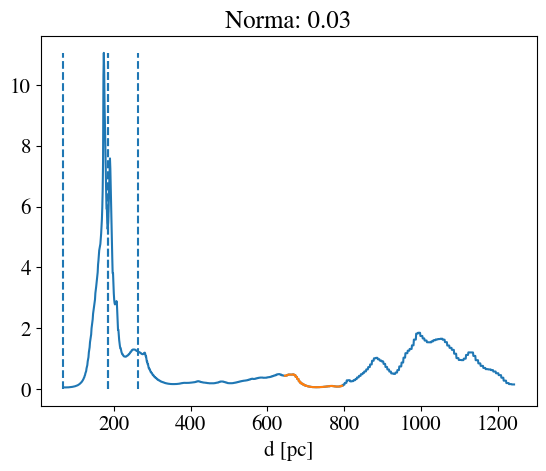

[-146.9 -169.6   -9.2   12.7  673.7  823.7] (150, 95, 98)
[-146.9 -169.6   -9.2   12.7   68.  1250. ] (1182, 95, 98)
0.12706156


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


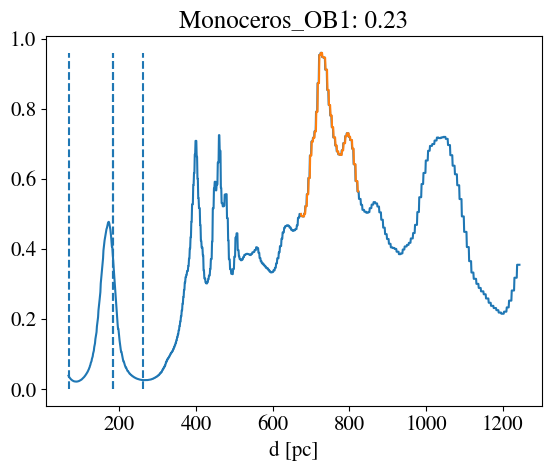

[104.4  83.4 -15.5   5.8 686.8 836.8] (150, 93, 91)
[ 104.4   83.4  -15.5    5.8   68.  1250. ] (1182, 93, 91)
0.18282047


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


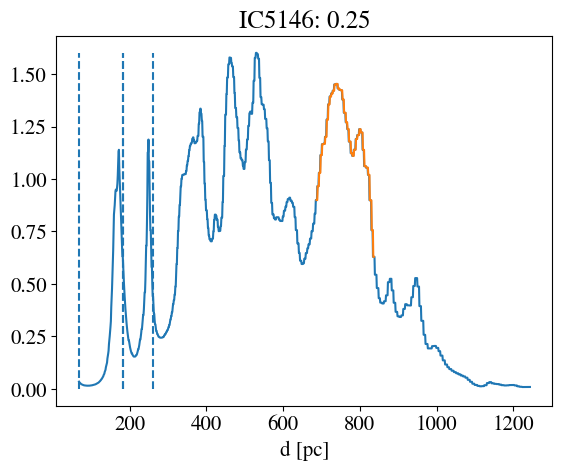

[ 96.6  71.7 -12.2  10.1 734.3 884.3] (150, 96, 108)
[  96.6   71.7  -12.2   10.1   68.  1250. ] (1182, 96, 108)
0.28491944


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


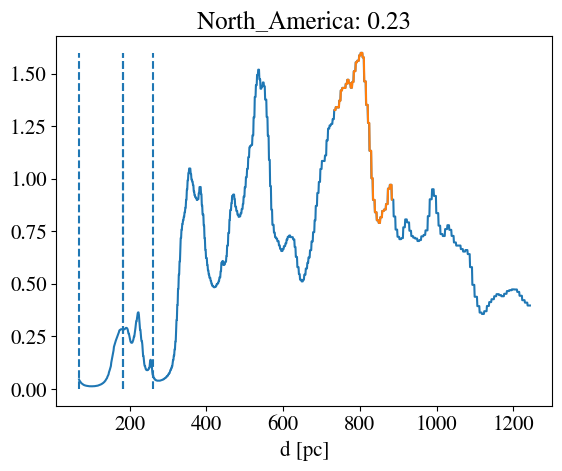

[-129.1 -157.   -22.9    2.3  780.8  930.8] (150, 110, 122)
[-129.1 -157.   -22.9    2.3   68.  1250. ] (1182, 110, 122)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.19978592


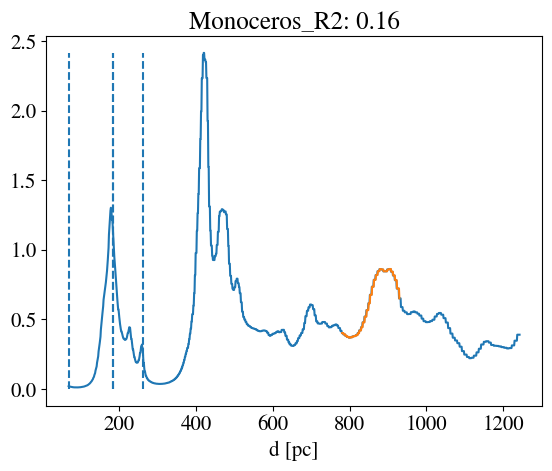

[140.  120.    1.5  21.5 783.  933. ] (150, 87, 87)
[ 140.   120.     1.5   21.5   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.23976782


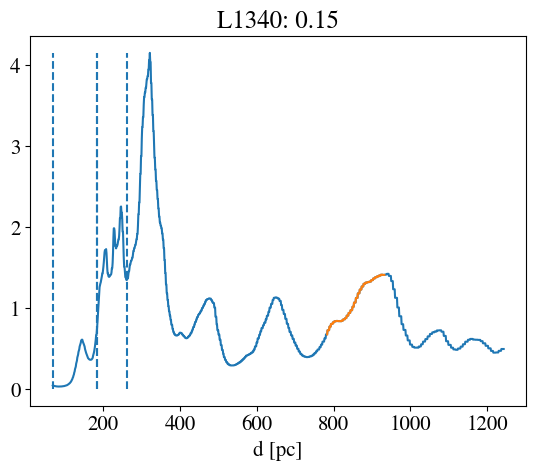

[134.6 114.3  -7.4  13.3 793.  943. ] (150, 90, 88)
[ 134.6  114.3   -7.4   13.3   68.  1250. ] (1182, 90, 88)
0.20825088


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


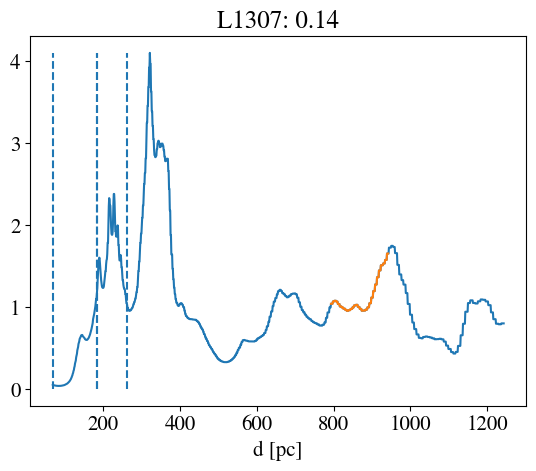

[132.  112.  -11.4   8.6 831.  981. ] (150, 87, 87)
[ 132.   112.   -11.4    8.6   68.  1250. ] (1182, 87, 87)


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


0.19614905


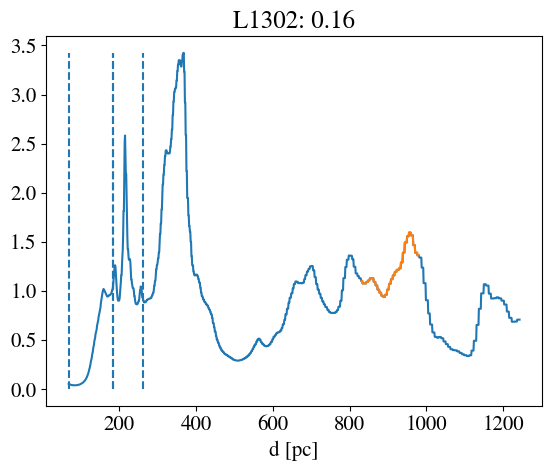

[ -83.9 -105.7   -8.8   12.5  842.4  992.4] (150, 93, 94)
[ -83.9 -105.7   -8.8   12.5   68.  1250. ] (1182, 93, 94)
0.3193263


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


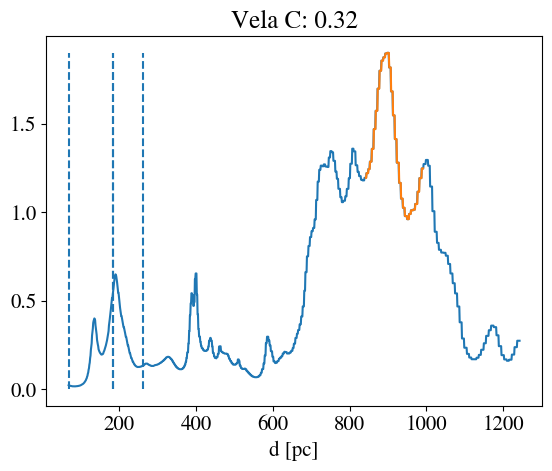

[110.4  88.9  -6.6  14.7 842.8 992.8] (150, 93, 93)
[ 110.4   88.9   -6.6   14.7   68.  1250. ] (1182, 93, 93)
0.22219408


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


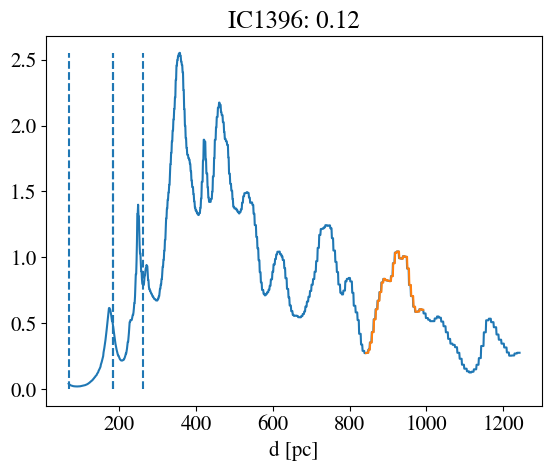

[136.8 115.6 -10.8   9.4 847.  997. ] (150, 87, 92)
[ 136.8  115.6  -10.8    9.4   68.  1250. ] (1182, 87, 92)
0.27981058


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


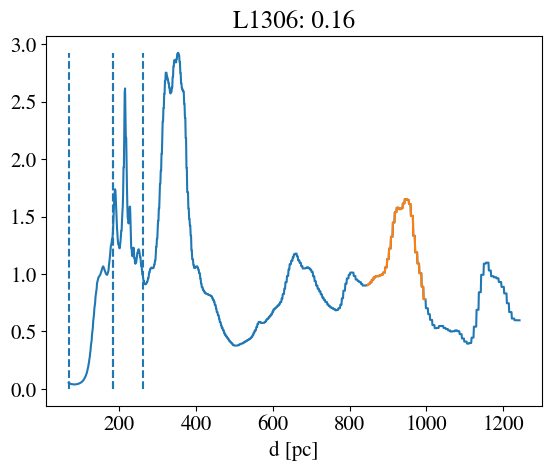

[ 143.6  122.8   -1.1   19.3  861.  1011. ] (150, 88, 90)
[ 1.436e+02  1.228e+02 -1.100e+00  1.930e+01  6.800e+01  1.250e+03] (1182, 88, 90)
0.4027099


/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:2: RuntimeWarning: Mean of empty slice
  plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_60675/2131198204.py:5: RuntimeWarning: Mean of empty slice
  plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),


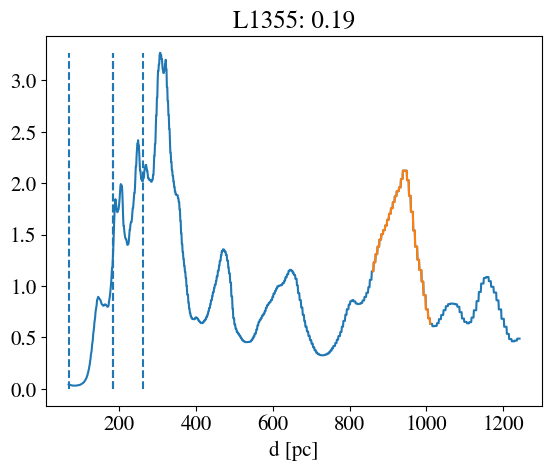

[([<matplotlib.lines.Line2D at 0x4b607c890>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Aquila_South: 0.49'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4b60aeb90>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Ophiuchus: 0.59'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4b6168a10>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Taurus: 0.49'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4b61ea7d0>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Corona_Australis: 0.6'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4b61a8490>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Lupus: 0.5'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4b62af8d0>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Pipe: 0.48'),
  None,
  None),
 ([<matplotlib.lines.Line2D at 0x4b62f7b90>],
  Text(0.5, 30.281249999999993, 'd [pc]'),
  Text(0.5, 1.0, 'Chamaeleon: 0.72'),
  None,
  None),
 (

In [ ]:
[(
plt.plot(np.arange(cubel.shape[0])+coordsl[4],np.nanmean(cubel,axis=(1,2))),
plt.plot(np.arange(cube.shape[0])+coords[4],np.nanmean(cube,axis=(1,2))),

plt.vlines(table2.iloc[0].to_numpy()[1:],0,np.nanmax(np.nanmean(cubel,axis=(1,2))),linestyle='--'),

plt.xlabel('d [pc]'),
# plt.xlim(table1['d_mean(pc)'].iloc[i]+np.array([-1,1])*300),
plt.title(table1['cloud'].iloc[i]+': '+str(round(np.nansum(cube)/np.nansum(cubel),2))),
# plt.plot(np.nanmean(cube,axis=(1,2)))

print(np.nanstd(np.nanmean(cube,axis=(1,2)))),

plt.show()
) 

for i in range(len(table1))#in_edenhfr #range(26) 
for cube,coords in [get_cloud_info(i,ednhfr_cm3,table1,75)]
for cubel,coordsl in [get_cloud_info(i,ednhfr_cm3,table1,'full')] 
]

In [ ]:
# appendix figure: showing the b_perp and b_parl grid overlaid on each cloud

# fig 5: pdfs of the volume density / distance from the spine (varying the distance ranges?)

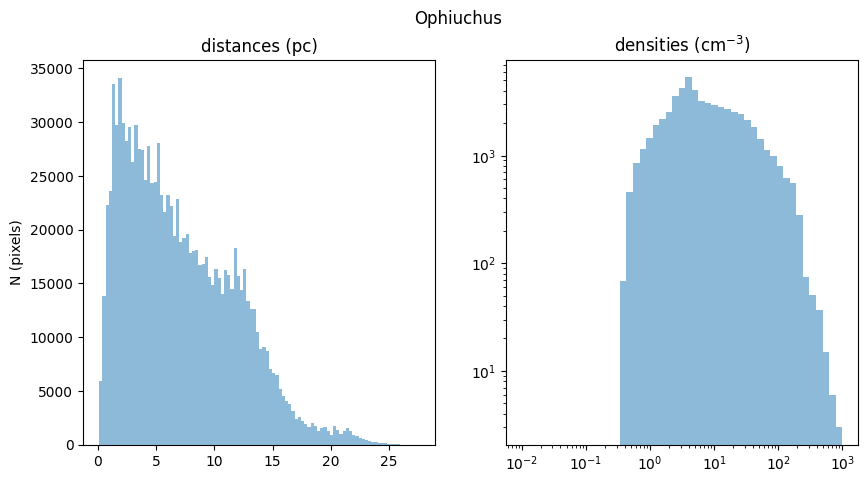

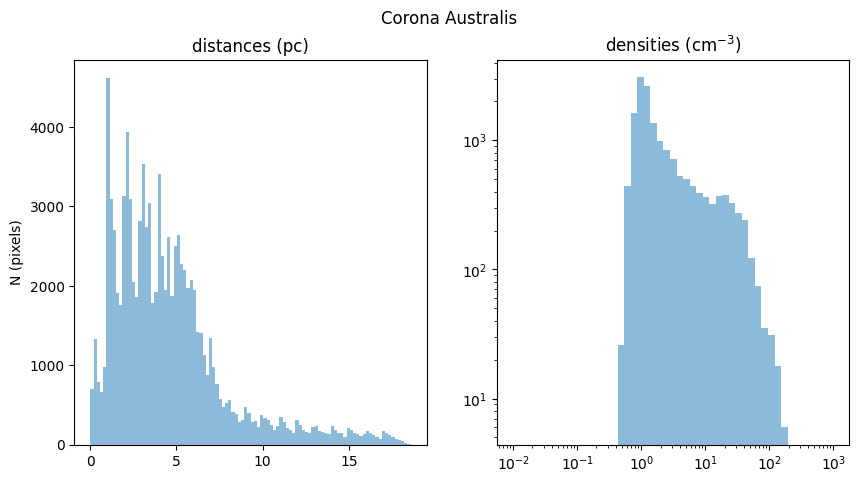

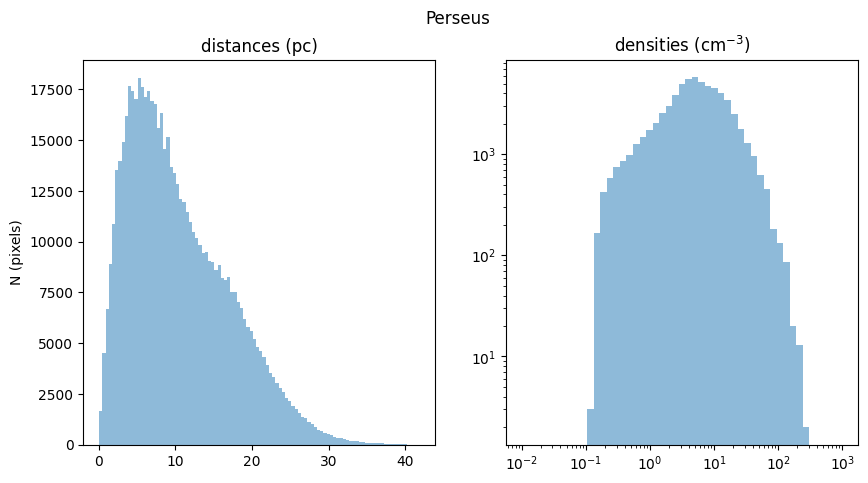

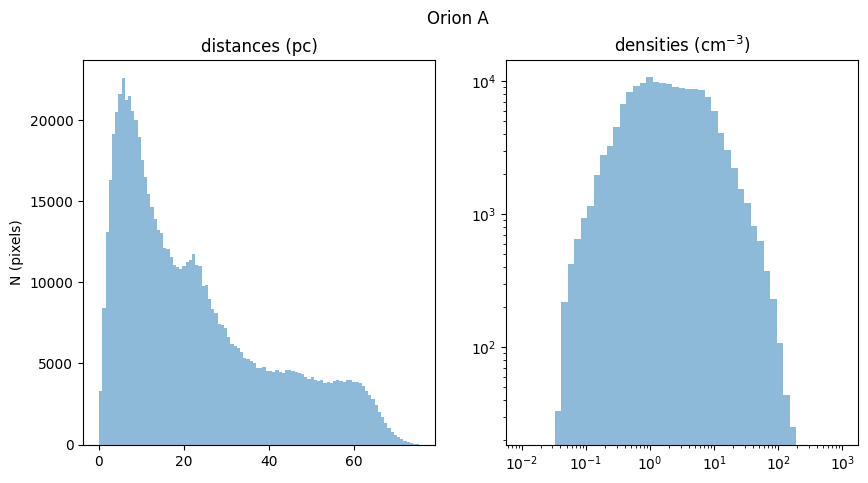

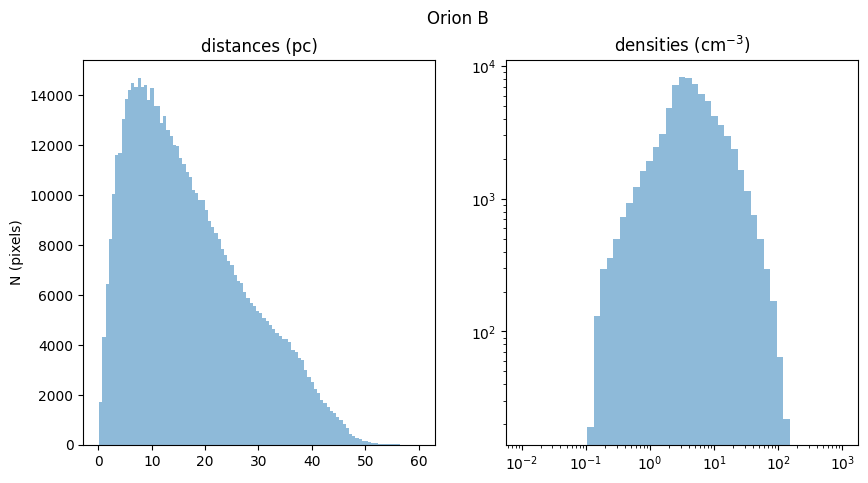

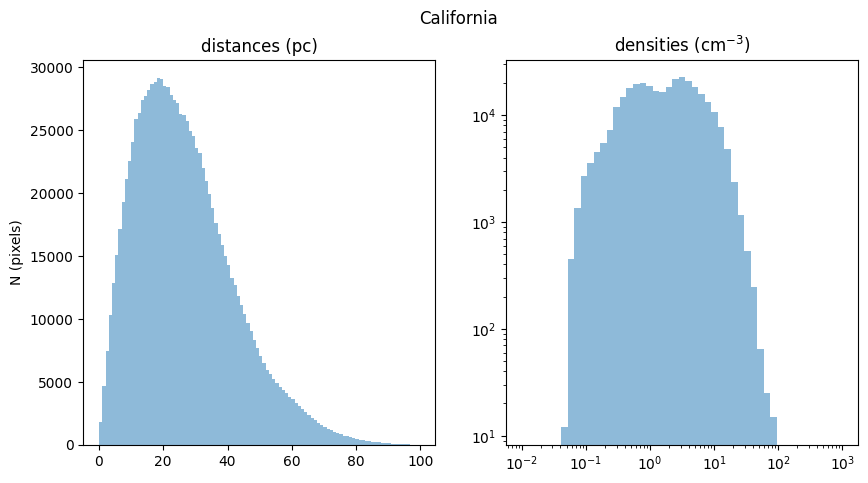

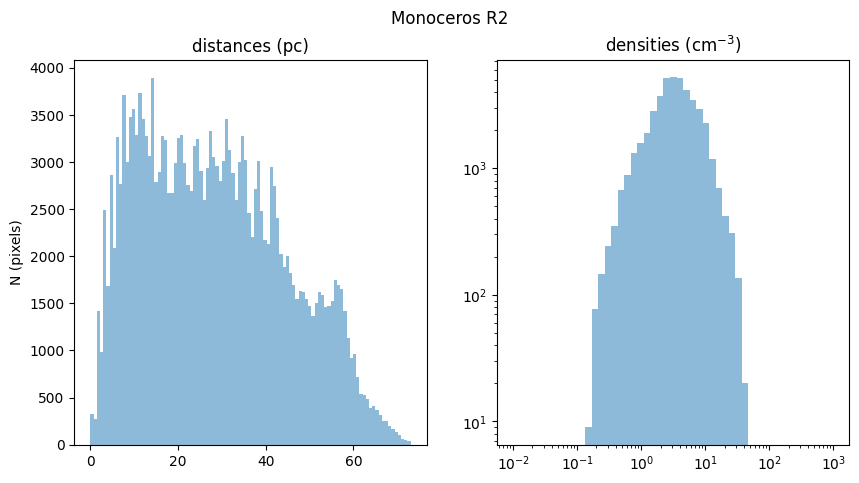

[None, None, None, None, None, None, None]

In [ ]:
[histogram(i,) for i,r in zip(og_if_clouds,lewis_rs)]